#### Trabajo Práctico · 2.er Cuatrimestre 2026

### METODOS PREDICTIVOS PARA LA GESTION

#### Tecnicatura Universitaria en Gestión y Análisis de Datos - FCE UBA

--------------------------------------------------------------------------

### 0. DESCRIPCIÓN Y FUENTE DEL DATASET

Para el desarrollo del trabajo se seleccionó el dataset Online News Popularity, disponible en el UCI Machine Learning Repository.

La base contiene información sobre artículos publicados por Mashable durante un período de dos años. Cada registro representa un artículo y contiene distintas características asociadas a su contenido y publicación, como la cantidad de palabras del título y del artículo, número de imágenes y videos, cantidad de enlaces, palabras clave, temática, día de publicación y diferentes indicadores relacionados con la subjetividad y el sentimiento del contenido.

Según los metadatos del repositorio UCI, el dataset registra 39.797 instancias y 58 variables predictoras. Sin embargo, al realizar la descarga y construir el DataFrame para este trabajo, se obtuvieron efectivamente 39.644 observaciones y 59 columnas, incluyendo la variable objetivo shares.

La variable shares representa la cantidad de veces que cada artículo fue compartido en redes sociales.

El objetivo del análisis será estudiar la relación entre las características de los artículos y su popularidad, buscando predecir la cantidad de veces que un artículo será compartido. Debido a que la variable objetivo shares es numérica, el problema será abordado mediante técnicas de regresión.

Fuente: UCI Machine Learning Repository — Online News Popularity.
Autores: Kelwin Fernandes, Pedro Vinagre, Paulo Cortez y Pedro Sernadela.

## 1. CARGA Y EXPLORACIÓN INICIAL DEL DATASET

En esta sección se realiza la carga de la base y una primera inspección de su estructura, sin aplicar todavía transformaciones sobre los datos.


### 1.1 Carga de librerías y del dataset


In [1]:
# Importamos la función fetch_ucirepo de la librería ucimlrepo.
# Esta función permite descargar datasets directamente desde
# el repositorio UCI Machine Learning Repository (https://archive.ics.uci.edu/).
# %pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd

In [2]:
# Descargamos el dataset "Online News Popularity".
# El parámetro id=332 identifica de manera única a este dataset dentro del repositorio UCI.
online_news_popularity = fetch_ucirepo(id=332)

# Separamos las variables predictoras (X) de la variable objetivo (y).
# X2 contiene las características de los artículos que utilizaremos como predictoras.
X2 = online_news_popularity.data.features

# y2 contiene la variable objetivo "shares":
# cantidad de veces que un artículo fue compartido.
y2 = online_news_popularity.data.targets

# Mostramos los metadatos generales del dataset.
print(online_news_popularity.metadata)

# Mostramos la información provista por UCI sobre cada variable.
print(online_news_popularity.variables)


{'uci_id': 332, 'name': 'Online News Popularity', 'repository_url': 'https://archive.ics.uci.edu/dataset/332/online+news+popularity', 'data_url': 'https://archive.ics.uci.edu/static/public/332/data.csv', 'abstract': 'This dataset summarizes a heterogeneous set of features about articles published by Mashable in a period of two years. The goal is to predict the number of shares in social networks (popularity).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 39797, 'num_features': 58, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': [' shares'], 'index_col': ['url'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Thu Feb 15 2024', 'dataset_doi': '10.24432/C5NS3V', 'creators': ['Kelwin Fernandes', 'Pedro Vinagre', 'Paulo Cortez', 'Pedro Sernadela'], 'intro_paper': {'ID': 390, 'type': 'NATIVE', 'title': 'A Proactive Intelligent Decisio

### 1.2 Dimensiones e identificación de la variable objetivo


In [3]:
# Mostramos los nombres de las variables predictoras
print("Variables predictoras:")
print(X2.columns)

# Mostramos el nombre de la variable objetivo
print("\nVariable objetivo:")
print(y2.columns)

# Mostramos las dimensiones de ambos DataFrames
print("\nDimensiones:")
print("X2:", X2.shape)
print("y2:", y2.shape)

Variables predictoras:
Index([' n_tokens_title', ' n_tokens_content', ' n_unique_tokens',
       ' n_non_stop_words', ' n_non_stop_unique_tokens', ' num_hrefs',
       ' num_self_hrefs', ' num_imgs', ' num_videos', ' average_token_length',
       ' num_keywords', ' data_channel_is_lifestyle',
       ' data_channel_is_entertainment', ' data_channel_is_bus',
       ' data_channel_is_socmed', ' data_channel_is_tech',
       ' data_channel_is_world', ' kw_min_min', ' kw_max_min', ' kw_avg_min',
       ' kw_min_max', ' kw_max_max', ' kw_avg_max', ' kw_min_avg',
       ' kw_max_avg', ' kw_avg_avg', ' self_reference_min_shares',
       ' self_reference_max_shares', ' self_reference_avg_sharess',
       ' weekday_is_monday', ' weekday_is_tuesday', ' weekday_is_wednesday',
       ' weekday_is_thursday', ' weekday_is_friday', ' weekday_is_saturday',
       ' weekday_is_sunday', ' is_weekend', ' LDA_00', ' LDA_01', ' LDA_02',
       ' LDA_03', ' LDA_04', ' global_subjectivity',
       ' global_se

Las variables predictoras se encuentran almacenadas en X2, que contiene 58 columnas correspondientes a las características de los artículos. Por su parte, y2 contiene una única columna, shares, que representa la cantidad de veces que cada artículo fue compartido en redes sociales.

Ambos conjuntos contienen 39.644 registros, por lo que existe correspondencia entre las observaciones de las variables predictoras y la variable objetivo.

### 1.3 Normalización de los nombres de las variables


In [4]:
# Los nombres de las variables poseen espacios a los costados

# Limpiamos los nombres de las variables predictoras
X2.columns = X2.columns.str.strip()

# Limpiamos el nombre de la variable objetivo
y2.columns = y2.columns.str.strip()

Se eliminaron los espacios en blanco al comienzo y al final de los nombres de las columnas de las variables predictoras y de la variable objetivo. Esto permite trabajar con nombres más limpios y facilita la selección y manipulación posterior de las variables.

### 1.4 Construcción del DataFrame completo


In [5]:
# Unimos las variables predictoras (X2) con la variable objetivo (y2)
# para disponer de un DataFrame completo para el análisis exploratorio.
df = pd.concat([X2, y2], axis=1)

### 1.5 Inspección inicial de la estructura


In [6]:
# Dimensiones del DataFrame completo: filas y columnas.
df.shape


(39644, 59)

In [7]:
# Estructura general: nombres de columnas, tipos de datos y valores no nulos.
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 59 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   n_tokens_title                 39644 non-null  float64
 1   n_tokens_content               39644 non-null  float64
 2   n_unique_tokens                39644 non-null  float64
 3   n_non_stop_words               39644 non-null  float64
 4   n_non_stop_unique_tokens       39644 non-null  float64
 5   num_hrefs                      39644 non-null  float64
 6   num_self_hrefs                 39644 non-null  float64
 7   num_imgs                       39644 non-null  float64
 8   num_videos                     39644 non-null  float64
 9   average_token_length           39644 non-null  float64
 10  num_keywords                   39644 non-null  float64
 11  data_channel_is_lifestyle      39644 non-null  float64
 12  data_channel_is_entertainment  39644 non-null 

El DataFrame completo contiene 39.644 registros y 59 columnas: 58 variables predictoras y una variable objetivo (shares).

La inspección mediante info() permite observar que todas las columnas contienen 39.644 valores no nulos. Además, las variables se encuentran almacenadas con tipo de dato float64.

Esta primera revisión permite confirmar que la estructura del conjunto de datos es consistente y que no se observan valores faltantes en esta instancia del análisis.

### 1.6 Inventario y tipología de variables


Se visualizan los primeros 10 registros para obtener una primera aproximación a la estructura y al contenido del conjunto de datos. Debido a la cantidad de columnas, algunas variables no se aprecian simultáneamente, por lo que se presentan agrupadas y se describen por separado a continuación.Se visualizarán los primeros 10 registros para obtener un panorama general de los campos (las columnas que no caben, se visualizarán por fuera de este informe, pero serán descritas y mostradas por separado posteriormente).

In [8]:
df.head(10)

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,0.0,4.680365,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,0.0,4.913725,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,0.0,4.393365,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,0.0,4.404896,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,0.0,4.682836,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505
5,10.0,370.0,0.559889,1.0,0.698198,2.0,2.0,0.0,0.0,4.359459,...,0.136364,0.6,-0.195000,-0.400,-0.100000,0.642857,0.214286,0.142857,0.214286,855
6,8.0,960.0,0.418163,1.0,0.549834,21.0,20.0,20.0,0.0,4.654167,...,0.100000,1.0,-0.224479,-0.500,-0.050000,0.000000,0.000000,0.500000,0.000000,556
7,12.0,989.0,0.433574,1.0,0.572108,20.0,20.0,20.0,0.0,4.617796,...,0.100000,1.0,-0.242778,-0.500,-0.050000,1.000000,0.500000,0.500000,0.500000,891
8,11.0,97.0,0.670103,1.0,0.836735,2.0,0.0,0.0,0.0,4.855670,...,0.400000,0.8,-0.125000,-0.125,-0.125000,0.125000,0.000000,0.375000,0.000000,3600
9,10.0,231.0,0.636364,1.0,0.797101,4.0,1.0,1.0,1.0,5.090909,...,0.100000,0.5,-0.238095,-0.500,-0.100000,0.000000,0.000000,0.500000,0.000000,710


A continuación, se agrupan las variables según sus características y su significado conceptual. Esta clasificación facilita la identificación de los atributos y permite comprender qué información aporta cada grupo al análisis.

In [9]:
#Agrupamiento de los nombres de las variables en listas asociadas correspondientemente a sus grupos conceptuales bajo los cuales se clasificaron dichas variables aleatorias.
cols_estr_art = [
    "n_tokens_title",
    "n_tokens_content",
    "n_unique_tokens",
    "n_non_stop_words",
    "n_non_stop_unique_tokens",
    "average_token_length",
    "num_keywords"
]

cols_enlaces_multimedia = [
    "num_hrefs",
    "num_self_hrefs",
    "num_imgs",
    "num_videos"
]

cols_canal_tematico = [
    "data_channel_is_lifestyle",
    "data_channel_is_entertainment",
    "data_channel_is_bus",
    "data_channel_is_socmed",
    "data_channel_is_tech",
    "data_channel_is_world"
]

cols_keywords = [
    "kw_min_min",
    "kw_max_min",
    "kw_avg_min",
    "kw_min_max",
    "kw_max_max",
    "kw_avg_max",
    "kw_min_avg",
    "kw_max_avg",
    "kw_avg_avg"
]

cols_referencias = [
    "self_reference_min_shares",
    "self_reference_max_shares",
    "self_reference_avg_sharess"
]

cols_dia_publicacion = [
    "weekday_is_monday",
    "weekday_is_tuesday",
    "weekday_is_wednesday",
    "weekday_is_thursday",
    "weekday_is_friday",
    "weekday_is_saturday",
    "weekday_is_sunday",
    "is_weekend"
]

cols_lda = [
    "LDA_00",
    "LDA_01",
    "LDA_02",
    "LDA_03",
    "LDA_04"
]

cols_sentimiento_subjetividad = [
    "global_subjectivity",
    "global_sentiment_polarity",
    "global_rate_positive_words",
    "global_rate_negative_words",
    "rate_positive_words",
    "rate_negative_words",
    "avg_positive_polarity",
    "min_positive_polarity",
    "max_positive_polarity",
    "avg_negative_polarity",
    "min_negative_polarity",
    "max_negative_polarity",
    "title_subjectivity",
    "title_sentiment_polarity",
    "abs_title_subjectivity",
    "abs_title_sentiment_polarity"
]

cols_no_predictivas = [
    "url",
    "timedelta"
]
# UCI identifica url y timedelta como atributos no predictivos.
# Sin embargo, no están incluidos en el DataFrame construido para este trabajo.
# Por lo tanto, no se incorporan a las listas de columnas de df.
cols_no_predictivas = []

col_objetivo = [
    "shares"
]

**Estructura del artículo**

In [10]:
df.loc[:,cols_estr_art] #Se seleccionan los atributos correspondientes a variables clasificadas dentro del conjunto de Estructura del Artículo.

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords
0,12.0,219.0,0.663594,1.0,0.815385,4.680365,5.0
1,9.0,255.0,0.604743,1.0,0.791946,4.913725,4.0
2,9.0,211.0,0.575130,1.0,0.663866,4.393365,6.0
3,9.0,531.0,0.503788,1.0,0.665635,4.404896,7.0
4,13.0,1072.0,0.415646,1.0,0.540890,4.682836,7.0
...,...,...,...,...,...,...,...
39639,11.0,346.0,0.529052,1.0,0.684783,4.523121,8.0
39640,12.0,328.0,0.696296,1.0,0.885057,4.405488,7.0
39641,10.0,442.0,0.516355,1.0,0.644128,5.076923,8.0
39642,6.0,682.0,0.539493,1.0,0.692661,4.975073,5.0


**Variables de estructura del artículo**

Estas variables describen características relacionadas con la extensión y la composición del texto de cada artículo.

- **n_tokens_title:** cantidad de palabras que contiene el título del artículo.
- **n_tokens_content:** cantidad de palabras que contiene el cuerpo del artículo.
- **n_unique_tokens:** proporción de palabras únicas respecto del total de palabras del contenido. Se calcula como la cantidad de palabras distintas dividida por la cantidad total de palabras:

 $$
\text{n\_unique\_tokens} = \frac{\text{cantidad de palabras distintas}}{\text{cantidad total de palabras}}
$$

  Esta variable permite observar la diversidad del vocabulario utilizado, independientemente de la extensión total del artículo.
- **n_non_stop_words:** proporción de palabras que no pertenecen al grupo de palabras frecuentes o *stop words*, como artículos, preposiciones y conectores.
- **n_non_stop_unique_tokens:** proporción de palabras únicas entre las palabras que no son *stop words*.
- **average_token_length:** longitud promedio de las palabras del contenido, medida en cantidad de caracteres. Se calcula como:
$$
\text{average\_token\_length} = \frac{\sum_{i=1}^{L} \text{longitud de la palabra } i}{L}
$$

  donde \(L\) representa la cantidad total de palabras del artículo.
- **num_keywords:** cantidad de palabras clave asociadas al artículo.

Estas variables son cuantitativas. Algunas representan cantidades absolutas y otras proporciones o promedios.

In [11]:
df.loc[:,cols_enlaces_multimedia] #atributos de enlaces multimedia

,num_hrefs,num_self_hrefs,num_imgs,num_videos
0,4.0,2.0,1.0,0.0
1,3.0,1.0,1.0,0.0
2,3.0,1.0,1.0,0.0
3,9.0,0.0,1.0,0.0
4,19.0,19.0,20.0,0.0
...,...,...,...,...
39639,9.0,7.0,1.0,1.0
39640,9.0,7.0,3.0,48.0
39641,24.0,1.0,12.0,1.0
39642,10.0,1.0,1.0,0.0


**Variables de enlaces y multimedia**

Estas variables describen la presencia de enlaces y elementos multimedia dentro de los artículos.

- **num_hrefs:** cantidad total de enlaces incluidos en el artículo.
- **num_self_hrefs:** cantidad de enlaces que dirigen a otros artículos publicados por Mashable.
- **num_imgs:** cantidad de imágenes asociadas al artículo.
- **num_videos:** cantidad de videos asociados al artículo.

Todas estas variables son cuantitativas, ya que expresan cantidades de elementos presentes en cada publicación.

In [12]:
df.loc[:,cols_canal_tematico] #Atributos canal temático.

,data_channel_is_lifestyle,data_channel_is_entertainment,data_channel_is_bus,data_channel_is_socmed,data_channel_is_tech,data_channel_is_world
0,0.0,1.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...
39639,0.0,0.0,0.0,0.0,1.0,0.0
39640,0.0,0.0,0.0,1.0,0.0,0.0
39641,0.0,0.0,0.0,0.0,0.0,0.0
39642,0.0,0.0,0.0,0.0,0.0,1.0


**Temática o canal del artículo**

Estas variables identifican el canal temático al que pertenece cada artículo:

- **data_channel_is_lifestyle:** estilo de vida.
- **data_channel_is_entertainment:** entretenimiento.
- **data_channel_is_bus:** negocios.
- **data_channel_is_socmed:** redes sociales.
- **data_channel_is_tech:** tecnología.
- **data_channel_is_world:** actualidad y noticias de alcance mundial.

Son variables cualitativas representadas mediante variables dummy o indicadores binarios. Cada columna toma valores 0 o 1: el valor 1 indica que el artículo pertenece al canal correspondiente, mientras que el valor 0 indica que no pertenece a él.

Estas variables ya vienen codificadas de esta manera desde el dataset original, por lo que no es necesario realizar una transformación adicional para representarlas numéricamente.

In [13]:
df.loc[:,cols_keywords] #Atributos asociados a palabras clave

,kw_min_min,kw_max_min,kw_avg_min,kw_min_max,kw_max_max,kw_avg_max,kw_min_avg,kw_max_avg,kw_avg_avg
0,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
4,0.0,0.0,0.000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
39639,-1.0,671.0,173.125,26900.0,843300.0,374962.500000,2514.742857,4004.342857,3031.115764
39640,-1.0,616.0,184.000,6500.0,843300.0,192985.714286,1664.267857,5470.168651,3411.660830
39641,-1.0,691.0,168.250,6200.0,843300.0,295850.000000,1753.882353,6880.687034,4206.439195
39642,-1.0,0.0,-1.000,0.0,843300.0,254600.000000,0.000000,3384.316871,1777.895883


**Variables asociadas a las palabras clave**

Estas variables describen la popularidad histórica de las palabras clave asociadas a cada artículo, tomando como referencia la cantidad de veces que fueron compartidos otros artículos relacionados con esas mismas palabras clave.

Se organizan en tres grupos:

**1. Estadísticas basadas en los valores mínimos de shares:**

- **kw_min_min:** menor valor de shares entre los valores mínimos asociados a las palabras clave.
- **kw_max_min:** mayor valor de shares entre esos valores mínimos.
- **kw_avg_min:** promedio de los valores mínimos de shares.

**2. Estadísticas basadas en los valores máximos de shares:**

- **kw_min_max:** menor valor de shares entre los valores máximos asociados a las palabras clave.
- **kw_max_max:** mayor valor de shares entre esos valores máximos.
- **kw_avg_max:** promedio de los valores máximos de shares.

**3. Estadísticas basadas en los valores promedio de shares:**

- **kw_min_avg:** menor valor entre los promedios de shares asociados a las palabras clave.
- **kw_max_avg:** mayor valor entre esos promedios.
- **kw_avg_avg:** promedio de los promedios de shares.

En conjunto, estas variables permiten representar el nivel de popularidad que tuvieron históricamente las palabras clave vinculadas a cada artículo.

Todas estas variables son cuantitativas.

In [14]:
df.loc[:,cols_dia_publicacion]

,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday,is_weekend
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
39639,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39640,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39641,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
39642,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


**Día de publicación**

Estas variables indican el día de la semana en que fue publicado cada artículo.

Se dispone de una variable dummy para cada día:

- **weekday_is_monday:** lunes.
- **weekday_is_tuesday:** martes.
- **weekday_is_wednesday:** miércoles.
- **weekday_is_thursday:** jueves.
- **weekday_is_friday:** viernes.
- **weekday_is_saturday:** sábado.
- **weekday_is_sunday:** domingo.

Además, **is_weekend** indica si el artículo fue publicado durante el fin de semana.

Estas variables son cualitativas representadas mediante indicadores binarios.

Es importante considerar que existe una relación exacta entre algunas de ellas: el indicador is_weekend equivale a la suma de los indicadores de sábado y domingo. Por lo tanto, su inclusión conjunta con todas las variables de días de la semana puede generar redundancia y dependencia lineal, aspecto que deberá tenerse en cuenta en los análisis posteriores.

In [15]:
df.loc[:,cols_lda]

,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04
0,0.500331,0.378279,0.040005,0.041263,0.040123
1,0.799756,0.050047,0.050096,0.050101,0.050001
2,0.217792,0.033334,0.033351,0.033334,0.682188
3,0.028573,0.419300,0.494651,0.028905,0.028572
4,0.028633,0.028794,0.028575,0.028572,0.885427
...,...,...,...,...,...
39639,0.025038,0.025001,0.151701,0.025000,0.773260
39640,0.029349,0.028575,0.231866,0.681635,0.028575
39641,0.159004,0.025025,0.025207,0.643794,0.146970
39642,0.040004,0.040003,0.839987,0.040002,0.040004


**LDA: Latent Dirichlet Allocation**

Latent Dirichlet Allocation (LDA) es una técnica de modelado de tópicos que permite identificar temas presentes en un conjunto de documentos a partir de las palabras que contienen.

En este dataset se incluyen cinco variables: **LDA_00, LDA_01, LDA_02, LDA_03 y LDA_04**. Cada una representa el grado de asociación de un artículo con uno de los tópicos identificados por el modelo.

Sus valores son numéricos y permiten representar cómo se distribuye la asociación temática de cada artículo entre los cinco tópicos.

Estas variables son cuantitativas y pueden aportar información sobre el contenido temático de las publicaciones. Su utilidad para explicar o predecir la popularidad deberá evaluarse durante los análisis posteriores.

In [16]:
df.loc[:,cols_sentimiento_subjetividad]

,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity
0,0.521617,0.092562,0.045662,0.013699,0.769231,0.230769,0.378636,0.100000,0.70,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500
1,0.341246,0.148948,0.043137,0.015686,0.733333,0.266667,0.286915,0.033333,0.70,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000
2,0.702222,0.323333,0.056872,0.009479,0.857143,0.142857,0.495833,0.100000,1.00,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000
3,0.429850,0.100705,0.041431,0.020716,0.666667,0.333333,0.385965,0.136364,0.80,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000
4,0.513502,0.281003,0.074627,0.012127,0.860215,0.139785,0.411127,0.033333,1.00,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
39639,0.482679,0.141964,0.037572,0.014451,0.722222,0.277778,0.333791,0.100000,0.75,-0.260000,-0.500,-0.125000,0.100000,0.000000,0.400000,0.000000
39640,0.564374,0.194249,0.039634,0.009146,0.812500,0.187500,0.374825,0.136364,0.70,-0.211111,-0.400,-0.100000,0.300000,1.000000,0.200000,1.000000
39641,0.510296,0.024609,0.033937,0.024887,0.576923,0.423077,0.307273,0.136364,0.50,-0.356439,-0.800,-0.166667,0.454545,0.136364,0.045455,0.136364
39642,0.358578,-0.008066,0.020528,0.023460,0.466667,0.533333,0.236851,0.062500,0.50,-0.205246,-0.500,-0.012500,0.000000,0.000000,0.500000,0.000000


**Variables de sentimiento y subjetividad**

Estas variables describen características relacionadas con la subjetividad y la orientación emocional del contenido de los artículos y de sus títulos.

Entre ellas se encuentran:

- **global_subjectivity:** medida de subjetividad general del contenido.
- **global_sentiment_polarity:** polaridad general del sentimiento del artículo, que puede tomar valores negativos o positivos.
- **global_rate_positive_words:** proporción de palabras positivas respecto del total de palabras del contenido.
- **global_rate_negative_words:** proporción de palabras negativas respecto del total de palabras del contenido.
- **rate_positive_words:** proporción de palabras positivas entre las palabras identificadas como positivas o negativas.
- **rate_negative_words:** proporción de palabras negativas entre las palabras identificadas como positivas o negativas.
- **avg_positive_polarity:** polaridad positiva promedio de las palabras positivas.
- **min_positive_polarity:** menor valor de polaridad positiva.
- **max_positive_polarity:** mayor valor de polaridad positiva.
- **avg_negative_polarity:** polaridad negativa promedio de las palabras negativas.
- **min_negative_polarity:** menor valor de polaridad negativa.
- **max_negative_polarity:** mayor valor de polaridad negativa.
- **title_subjectivity:** medida de subjetividad del título.
- **title_sentiment_polarity:** polaridad del sentimiento expresado en el título.
- **abs_title_subjectivity:** valor absoluto de la subjetividad del título respecto de un punto de referencia neutral.
- **abs_title_sentiment_polarity:** valor absoluto de la polaridad del sentimiento del título.

Todas estas variables son cuantitativas, ya que expresan proporciones, promedios o medidas numéricas de intensidad y orientación del sentimiento.

### 1.7 Análisis de escalas y rangos

Las variables del dataset presentan diferentes escalas y rangos de valores, debido a que representan cantidades, proporciones y medidas de distinta naturaleza.

En esta etapa se realiza una primera identificación de esas diferencias, sin aplicar todavía transformaciones sobre los valores originales.

La necesidad de estandarizar o transformar las variables se evaluará en las etapas posteriores, considerando los requerimientos de cada técnica de análisis y modelado.

---

## 2. LIMPIEZA Y PREPROCESAMIENTO

### 2.1 Valores faltantes

### Identificación de campos con valores faltantes:

In [17]:
df.isna().sum().sort_values(ascending=False)

n_tokens_title                   0
n_tokens_content                 0
n_unique_tokens                  0
n_non_stop_words                 0
n_non_stop_unique_tokens         0
num_hrefs                        0
num_self_hrefs                   0
num_imgs                         0
num_videos                       0
average_token_length             0
num_keywords                     0
data_channel_is_lifestyle        0
data_channel_is_entertainment    0
data_channel_is_bus              0
data_channel_is_socmed           0
data_channel_is_tech             0
data_channel_is_world            0
kw_min_min                       0
kw_max_min                       0
kw_avg_min                       0
kw_min_max                       0
kw_max_max                       0
kw_avg_max                       0
kw_min_avg                       0
kw_max_avg                       0
kw_avg_avg                       0
self_reference_min_shares        0
self_reference_max_shares        0
self_reference_avg_s

La inspección realizada permite comprobar que ninguna de las variables del DataFrame presenta valores faltantes (NaN).

Por lo tanto, no resulta necesario aplicar técnicas de imputación de valores en esta etapa. Sin embargo, la ausencia de valores faltantes no garantiza por sí sola la consistencia de los datos, por lo que se continuará examinando la existencia de posibles duplicados, inconsistencias y valores atípicos.

### 2.2 Registros duplicados

In [18]:
print(f"Suma de registros duplicados: {df.duplicated().sum()}") #suma de registros duplicados


Suma de registros duplicados: 0


Se verifica que el conjunto de datos no contiene registros completamente duplicados. Por lo tanto, no es necesario eliminar observaciones por duplicación en esta etapa del preprocesamiento.

### 2.3 Inconsistencias

In [19]:
#Se aplicará a variables cualitativas
df[cols_canal_tematico].isin([0, 1]).all().all() #Se verifica que las columnas de canal temático sean de 0 y 1, no pueden ser no binarias porque son columnas dummy.

np.True_

El resultado obtenido es True, lo que confirma que todas las variables correspondientes a los canales temáticos respetan la codificación binaria esperada. Por lo tanto, no se detectan inconsistencias en estos campos.La salida anterior arroja como resultado el valor verdadero, por lo que todas las columnas de canal temático respetan la regla de numerización.

In [20]:
cols_dia_publicacion = [
    "weekday_is_monday",
    "weekday_is_tuesday",
    "weekday_is_wednesday",
    "weekday_is_thursday",
    "weekday_is_friday",
    "weekday_is_saturday",
    "weekday_is_sunday"
]
df[cols_dia_publicacion].sum(axis=1).value_counts()

1.0    39644
Name: count, dtype: int64

In [21]:
# Verificamos que is_weekend coincida con los indicadores de sábado y domingo.
(
    df["is_weekend"]
    == df[["weekday_is_saturday", "weekday_is_sunday"]].sum(axis=1)
).all()

np.True_

Se verifica que cada registro tenga asignado exactamente un día de la semana. La suma de los siete indicadores debe ser igual a 1 para cada observación, ya que cada artículo tiene una única fecha de publicación.

El resultado obtenido confirma que los 39.644 registros cumplen esta condición.

Además, se comprobará que la variable is_weekend coincida con la suma de los indicadores correspondientes a sábado y domingo.

Las verificaciones realizadas permiten confirmar la consistencia de las variables correspondientes al día de publicación y al indicador de fin de semana.

In [22]:
#Verificación de sumas de LDA = 1 (explicado en descripción de campos).
import numpy as np #Se imoprta numpy para operaciones algebraicas y redondeos en este caso.

suma_lda = df[cols_lda].sum(axis=1) #suma de los LDA a lo largo de cada registro.
resultado = pd.Series(np.isclose(suma_lda, 1)) #Se observan cuántos cumplen con la suma de LDA = 1, con tolerancia de redondeo.
resultado.value_counts() #Conteo de los resultados

True     39643
False        1
Name: count, dtype: int64

In [23]:
df.loc[~resultado, cols_lda] #Debido a la aparción de un resultado inconsistente con esta regla, se visualizará el mismo.

,LDA_00,LDA_01,LDA_02,LDA_03,LDA_04
31037,0.0,0.0,0.0,0.0,0.0


In [24]:
#Selección del registro completo para mayor detalle.
df.loc[~resultado, :]

,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
31037,9.0,1570.0,701.0,1042.0,650.0,11.0,10.0,51.0,0.0,4.696178,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5900


El registro identificado presenta características que requieren una revisión particular.

Aunque contiene 1.570 palabras en el cuerpo del artículo, las variables que deberían representar proporciones presentan valores incompatibles con sus escalas esperadas. Por ejemplo, n_unique_tokens toma el valor 701 y n_non_stop_words el valor 1042, cuando estas variables representan proporciones y deberían encontrarse dentro del intervalo [0, 1].

Además, las cinco variables LDA y las variables asociadas al sentimiento y la subjetividad presentan valores iguales a cero.

La combinación de estas observaciones indica una inconsistencia en el registro. Por este motivo, se continuará examinando la información disponible antes de decidir su tratamiento.

In [25]:
df.loc[~resultado,cols_sentimiento_subjetividad]

,global_subjectivity,global_sentiment_polarity,global_rate_positive_words,global_rate_negative_words,rate_positive_words,rate_negative_words,avg_positive_polarity,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity
31037,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Además de la ausencia de valores en las variables LDA, se observa que todas las variables relacionadas con sentimiento, polaridad y subjetividad también presentan valores iguales a cero.

Es importante aclarar que estos valores no son técnicamente valores faltantes (NaN), sino valores registrados como cero. Sin embargo, su presencia conjunta con valores fuera de rango en las variables de proporciones refuerza la necesidad de revisar esta observación.

Se analizarán otros campos del registro para determinar si la inconsistencia se limita a las variables lingüísticas o si también afecta a otras características del artículo.

In [26]:
df.loc[~resultado,cols_dia_publicacion]

,weekday_is_monday,weekday_is_tuesday,weekday_is_wednesday,weekday_is_thursday,weekday_is_friday,weekday_is_saturday,weekday_is_sunday
31037,0.0,1.0,0.0,0.0,0.0,0.0,0.0


La observación presenta un día de publicación correctamente asignado: martes. Por lo tanto, la inconsistencia no parece afectar a todas las variables del registro.

Sin embargo, los valores fuera de rango en las variables de proporciones, junto con la ausencia de información en las variables LDA y de sentimiento, permiten identificar un problema de consistencia en los atributos lingüísticos.

Se continuará evaluando el registro mediante el análisis de valores atípicos. La decisión de excluirlo se fundamentará en la coherencia de sus valores con las escalas y definiciones de las variables, procurando conservar el resto de la información válida del conjunto de datos.

### 2.4 - Variables no informativas

El repositorio UCI identifica determinados atributos que no se utilizan como variables predictoras.

Entre ellos se encuentra url, que funciona como referencia al artículo, y timedelta, que representa la cantidad de días transcurridos entre la publicación del artículo y la adquisición del conjunto de datos.

Estos atributos no forman parte del DataFrame utilizado en este trabajo, por lo que no se incorporan al análisis predictivo.

La exclusión de estos campos permite concentrar el análisis en las características del contenido, la publicación y la popularidad de los artículos.

### 2.5 Análisis de Outliers

#### Tipos de outliers

- **Globales:** observaciones que presentan valores muy alejados del comportamiento general del conjunto de datos.
- **Contextuales:** observaciones que resultan atípicas al considerar el contexto o las características particulares de la variable. Un valor puede ser válido en términos generales, pero resultar inusual dentro de un contexto determinado.
- **Colectivos:** conjuntos de observaciones que, consideradas individualmente, pueden no parecer anómalas, pero que presentan un comportamiento inusual cuando se analizan en conjunto.

#### Número de variables

Debido a que el dataset contiene numerosas variables, el análisis de valores atípicos se abordará principalmente desde una perspectiva multivariada.

Este enfoque permite evaluar las observaciones considerando simultáneamente varias características, en lugar de analizar cada variable de manera aislada.

Para ello se utilizarán tres métodos: distancia de Mahalanobis, Local Outlier Factor e Isolation Forest.

### Distancia de Mahalanobis

La distancia de Mahalanobis permite medir qué tan alejada se encuentra una observación respecto del centro del conjunto de datos, considerando simultáneamente las variables y sus relaciones de covarianza.

A diferencia de la distancia euclidiana, este método tiene en cuenta las diferencias de escala y la correlación entre las variables.

El resultado se expresa mediante la distancia de Mahalanobis al cuadrado (\(D^2\)). Cuanto mayor sea su valor, más alejada se encuentra la observación respecto del comportamiento general del conjunto.

Este método resulta útil para identificar posibles valores atípicos globales en un análisis multivariado.

In [27]:
#Como se aplicarán los 3 métodos, empezando por Mahalanobis, a variables cuantitativas, se aislarán del resto del df creando uno nuevo sólo con los campos previamente clasificados bajo la categoría de variables cuantitativas.
cols_cuantitativas = cols_estr_art + cols_enlaces_multimedia + cols_keywords + cols_referencias + cols_lda + cols_sentimiento_subjetividad

In [28]:
#%pip install scipy

In [29]:
from scipy.spatial.distance import mahalanobis

# Calculamos la media y la matriz de covarianza.
media = df[cols_cuantitativas].mean().values
cov = np.cov(df[cols_cuantitativas].values, rowvar=False)

# Utilizamos la pseudoinversa para mejorar la estabilidad numérica.
inv_cov = np.linalg.pinv(cov)

# Creamos un identificador único para cada registro.
df["id"] = np.arange(1, len(df) + 1)

# Calculamos la distancia de Mahalanobis al cuadrado.
diferencias = df[cols_cuantitativas].values - media

df["mahalanobis_2"] = np.einsum(
    "ij,jk,ik->i",
    diferencias,
    inv_cov,
    diferencias
)

# Evitamos pequeños valores negativos producidos por errores numéricos.
df["mahalanobis_2"] = df["mahalanobis_2"].clip(lower=0)

# Visualizamos las 50 observaciones con mayor distancia.
df[["id"] + cols_cuantitativas + ["mahalanobis_2"]] \
    .sort_values("mahalanobis_2", ascending=False) \
    .head(50)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
31037,31038,9.0,1570.0,701.000000,1042.0,650.000000,4.696178,7.0,11.0,10.0,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,39641.860279
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.500000,-0.341667,-0.600000,-0.125000,0.450000,0.300000,0.050000,0.300000,12031.950395
17137,17138,11.0,478.0,0.573276,1.0,0.768116,4.684100,5.0,4.0,0.0,...,0.033333,1.000000,-0.216667,-0.250000,-0.166667,0.000000,0.000000,0.500000,0.000000,8179.432421
10619,10620,11.0,358.0,0.575581,1.0,0.733010,4.826816,6.0,8.0,6.0,...,0.033333,1.000000,-0.185256,-0.500000,-0.100000,0.233333,0.066667,0.266667,0.066667,6455.405474
12300,12301,9.0,200.0,0.572864,1.0,0.714286,4.735000,8.0,5.0,3.0,...,0.100000,0.600000,-0.416667,-0.600000,-0.200000,0.700000,-0.050000,0.200000,0.050000,6342.008599
16281,16282,8.0,192.0,0.697297,1.0,0.735714,4.802083,8.0,13.0,1.0,...,0.100000,0.700000,-0.331250,-0.600000,-0.100000,1.000000,-0.500000,0.500000,0.500000,6215.870177
5674,5675,11.0,818.0,0.438662,1.0,0.564000,4.649144,7.0,37.0,34.0,...,0.033333,0.750000,-0.381283,-0.800000,-0.071429,0.437500,0.187500,0.062500,0.187500,2905.925070
18101,18102,9.0,1322.0,0.531457,1.0,0.594732,5.062784,7.0,143.0,51.0,...,0.100000,0.800000,-0.393056,-0.800000,-0.100000,0.500000,0.500000,0.000000,0.500000,2434.766747
7109,7110,9.0,299.0,0.559322,1.0,0.731429,4.648829,9.0,4.0,3.0,...,0.100000,0.750000,-0.240278,-0.500000,-0.125000,0.500000,0.500000,0.000000,0.500000,2190.503016
18188,18189,11.0,924.0,0.561060,1.0,0.667195,4.813853,7.0,89.0,41.0,...,0.100000,0.800000,-0.447288,-0.700000,-0.050000,0.000000,0.000000,0.500000,0.000000,2125.670025


En la primera ejecución del método de Mahalanobis, el registro identificado con el id 31038 presenta la mayor distancia respecto del centro del conjunto de datos.

Al examinar sus características, se observa que algunas variables que representan proporciones presentan valores fuera de sus rangos esperados. Por ejemplo, n_unique_tokens y n_non_stop_words contienen valores muy superiores a 1.

Esta situación constituye una inconsistencia en la escala de las variables y no simplemente un comportamiento atípico.

Por este motivo, se considera justificada la exclusión de este registro antes de continuar con el análisis multivariado.

In [30]:
df = df[df['id'] != 31038]

$\mathbf{\text{Registro id=31038 excluido}}$

Se realiza Mahalanobis nuevamente, habiendo excluido previamente el registro conflictivo.

In [31]:
# Recalculamos Mahalanobis después de excluir el registro inconsistente.

media = df[cols_cuantitativas].mean().values
cov = np.cov(df[cols_cuantitativas].values, rowvar=False)
inv_cov = np.linalg.pinv(cov)

diferencias = df[cols_cuantitativas].values - media

df["mahalanobis_2"] = np.einsum(
    "ij,jk,ik->i",
    diferencias,
    inv_cov,
    diferencias
)

df["mahalanobis_2"] = df["mahalanobis_2"].clip(lower=0)

df[["id"] + cols_cuantitativas + ["mahalanobis_2"]] \
    .sort_values("mahalanobis_2", ascending=False) \
    .head(50)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.500000,-0.341667,-0.600000,-0.125000,0.450000,0.300000,0.050000,0.300000,12031.654325
17137,17138,11.0,478.0,0.573276,1.0,0.768116,4.684100,5.0,4.0,0.0,...,0.033333,1.000000,-0.216667,-0.250000,-0.166667,0.000000,0.000000,0.500000,0.000000,8179.228634
10619,10620,11.0,358.0,0.575581,1.0,0.733010,4.826816,6.0,8.0,6.0,...,0.033333,1.000000,-0.185256,-0.500000,-0.100000,0.233333,0.066667,0.266667,0.066667,6455.424727
12300,12301,9.0,200.0,0.572864,1.0,0.714286,4.735000,8.0,5.0,3.0,...,0.100000,0.600000,-0.416667,-0.600000,-0.200000,0.700000,-0.050000,0.200000,0.050000,6341.846011
16281,16282,8.0,192.0,0.697297,1.0,0.735714,4.802083,8.0,13.0,1.0,...,0.100000,0.700000,-0.331250,-0.600000,-0.100000,1.000000,-0.500000,0.500000,0.500000,6215.869335
5674,5675,11.0,818.0,0.438662,1.0,0.564000,4.649144,7.0,37.0,34.0,...,0.033333,0.750000,-0.381283,-0.800000,-0.071429,0.437500,0.187500,0.062500,0.187500,2905.834909
18101,18102,9.0,1322.0,0.531457,1.0,0.594732,5.062784,7.0,143.0,51.0,...,0.100000,0.800000,-0.393056,-0.800000,-0.100000,0.500000,0.500000,0.000000,0.500000,2434.708925
7109,7110,9.0,299.0,0.559322,1.0,0.731429,4.648829,9.0,4.0,3.0,...,0.100000,0.750000,-0.240278,-0.500000,-0.125000,0.500000,0.500000,0.000000,0.500000,2190.491270
18188,18189,11.0,924.0,0.561060,1.0,0.667195,4.813853,7.0,89.0,41.0,...,0.100000,0.800000,-0.447288,-0.700000,-0.050000,0.000000,0.000000,0.500000,0.000000,2125.622380
18303,18304,8.0,593.0,0.627523,1.0,0.678733,5.075885,6.0,83.0,41.0,...,0.100000,0.800000,-0.448538,-1.000000,-0.155556,0.000000,0.000000,0.500000,0.000000,2122.368509


In [32]:
#No se visualizará Mahalanobis dada la imposibilidad de realizar una representación visual capaz de capturar todas las dimensiones.

El análisis de Mahalanobis permite identificar observaciones que presentan una combinación de características alejada del comportamiento general del conjunto de datos.

En los registros con mayores distancias aparecen valores de n_non_stop_words próximos a 1. Sin embargo, este comportamiento no constituye por sí mismo una inconsistencia, ya que se trata de una variable expresada como proporción.

Por lo tanto, estos registros serán examinados considerando el conjunto de sus características y no se excluirán únicamente por presentar valores elevados en esta variable.

In [33]:
df[np.isclose(df['n_non_stop_words'], 1)][['id'] + cols_cuantitativas + ['mahalanobis_2']] \
    .sort_values('mahalanobis_2', ascending=False) #Se utiliza el isclose de numpy para considerar una tolerancia por redondeo de punto flotante.

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,mahalanobis_2
16294,16295,13.0,162.0,0.716049,1.0,0.850467,4.808642,10.0,8.0,7.0,...,0.100000,0.50,-0.341667,-0.6000,-0.125000,0.450000,0.300000,0.050000,0.300000,12031.654325
17137,17138,11.0,478.0,0.573276,1.0,0.768116,4.684100,5.0,4.0,0.0,...,0.033333,1.00,-0.216667,-0.2500,-0.166667,0.000000,0.000000,0.500000,0.000000,8179.228634
10619,10620,11.0,358.0,0.575581,1.0,0.733010,4.826816,6.0,8.0,6.0,...,0.033333,1.00,-0.185256,-0.5000,-0.100000,0.233333,0.066667,0.266667,0.066667,6455.424727
12300,12301,9.0,200.0,0.572864,1.0,0.714286,4.735000,8.0,5.0,3.0,...,0.100000,0.60,-0.416667,-0.6000,-0.200000,0.700000,-0.050000,0.200000,0.050000,6341.846011
16281,16282,8.0,192.0,0.697297,1.0,0.735714,4.802083,8.0,13.0,1.0,...,0.100000,0.70,-0.331250,-0.6000,-0.100000,1.000000,-0.500000,0.500000,0.500000,6215.869335
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21467,21468,8.0,358.0,0.581006,1.0,0.759434,4.748603,7.0,8.0,3.0,...,0.100000,0.60,-0.256250,-0.5000,-0.125000,0.000000,0.000000,0.500000,0.000000,7.917621
21351,21352,11.0,408.0,0.565432,1.0,0.703125,4.879902,9.0,8.0,3.0,...,0.100000,0.80,-0.168948,-0.3125,-0.100000,0.233333,0.050000,0.266667,0.050000,7.873362
17558,17559,9.0,919.0,0.474090,1.0,0.667883,4.842220,7.0,10.0,0.0,...,0.100000,0.80,-0.200556,-0.5000,-0.066667,0.125000,0.000000,0.375000,0.000000,7.620617
22402,22403,10.0,638.0,0.544861,1.0,0.698454,4.597179,7.0,15.0,1.0,...,0.062500,0.80,-0.284936,-0.6000,-0.125000,0.000000,0.000000,0.500000,0.000000,7.068368


In [34]:
#la mayoría de los n_non_stop_words presentan valores cercanos a 1, teniendo un margen de tolerancia con el is close de 5 decimales en este caso.
#Se observará la salida del método describe con el propósito de indagar con mayor nivel de detalle este campo:
df['n_non_stop_words'].describe()

count    39643.000000
mean         0.970209
std          0.170012
min          0.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: n_non_stop_words, dtype: float64

In [35]:
# Agrupamos los valores por redondeo para facilitar su interpretación.
df["n_non_stop_words"].round(5).value_counts().sort_index()

n_non_stop_words
0.0     1181
1.0    38462
Name: count, dtype: int64

In [36]:
pd.set_option('display.precision', 15)
df[['id', 'n_non_stop_words']].sort_values('n_non_stop_words', ascending=False).head(20)

,id,n_non_stop_words
24612,24613,0.999999999780
17891,17892,0.999999999758
30187,30188,0.999999999757
24564,24565,0.999999999746
19513,19514,0.999999999746
14120,14121,0.999999999739
24802,24803,0.999999999738
18702,18703,0.999999999735
28367,28368,0.999999999734
24964,24965,0.999999999730


In [37]:
#Se evaluará el aporte de este campo al modelo de regresión utilizando la matriz de correlación, incluyendo a la variable objetivo (y quitando a mahalanobis):
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
    + ['shares']
)

matriz_correlacion = df[cols_corr].corr()

matriz_correlacion['shares'].sort_values()

LDA_02                          -0.059159036822982
data_channel_is_world           -0.049494683124482
avg_negative_polarity           -0.032041637188197
average_token_length            -0.022008271496684
n_non_stop_unique_tokens        -0.020486573639058
n_non_stop_words                -0.019644116775083
min_negative_polarity           -0.019307944201499
max_negative_polarity           -0.019306657045789
data_channel_is_entertainment   -0.017018876499631
LDA_04                          -0.016617687576172
data_channel_is_tech            -0.013250328685698
rate_positive_words             -0.013223969049025
data_channel_is_bus             -0.012373850070580
LDA_01                          -0.010179439116232
weekday_is_thursday             -0.008830699455243
weekday_is_tuesday              -0.007952446697005
n_unique_tokens                 -0.007055318598868
rate_negative_words             -0.005173343498648
weekday_is_friday               -0.003882133457608
weekday_is_wednesday           

In [38]:
matriz_correlacion['shares'].describe()

count    58.000000000000000
mean      0.026250957240672
std       0.133500573263996
min      -0.059159036822982
25%      -0.008611136265684
50%       0.004596139321048
75%       0.026338809144204
max       1.000000000000000
Name: shares, dtype: float64

La variable n_non_stop_words presenta una correlación lineal muy débil con shares (r = -0,0196).

Sin embargo, este resultado no es suficiente para justificar su eliminación, ya que la correlación de Pearson mide únicamente la asociación lineal entre dos variables y no permite determinar por sí sola su utilidad predictiva.

Por lo tanto, se conservará la variable para los análisis posteriores, dejando su relevancia sujeta a la evaluación de los modelos.

In [39]:
df.loc[df['n_non_stop_words'] == 0,
       ['id', 'n_tokens_content', 'n_non_stop_words', 'n_non_stop_unique_tokens']]
#Los registros con valores, a los fines prácticos, considerados aproximadamente iguales a 0 son artículos en los cuyos registros no se encuentran cuantificadas palabras registradas.

,id,n_tokens_content,n_non_stop_words,n_non_stop_unique_tokens
893,894,0.0,0.0,0.0
917,918,0.0,0.0,0.0
1062,1063,0.0,0.0,0.0
1121,1122,0.0,0.0,0.0
1312,1313,0.0,0.0,0.0
...,...,...,...,...
39598,39599,0.0,0.0,0.0
39601,39602,0.0,0.0,0.0
39613,39614,0.0,0.0,0.0
39615,39616,0.0,0.0,0.0


In [40]:
df.loc[df['n_tokens_content'] == 0, cols_estr_art].describe().T #Se aislan estos casos en pos de su examinación.

,count,mean,std,min,25%,50%,75%,max
n_tokens_title,1181.0,10.930567315834040,2.052758895891004,5.0,10.0,11.0,12.0,17.0
n_tokens_content,1181.0,0.000000000000000,0.000000000000000,0.0,0.0,0.0,0.0,0.0
n_unique_tokens,1181.0,0.000000000000000,0.000000000000000,0.0,0.0,0.0,0.0,0.0
n_non_stop_words,1181.0,0.000000000000000,0.000000000000000,0.0,0.0,0.0,0.0,0.0
n_non_stop_unique_tokens,1181.0,0.000000000000000,0.000000000000000,0.0,0.0,0.0,0.0,0.0
average_token_length,1181.0,0.000000000000000,0.000000000000000,0.0,0.0,0.0,0.0,0.0
num_keywords,1181.0,7.508890770533446,1.627922833434722,1.0,6.0,7.0,9.0,10.0


Se identifican 1.181 registros en los que n_tokens_content toma el valor 0. En estas observaciones, las variables derivadas del contenido textual (n_unique_tokens, n_non_stop_words, n_non_stop_unique_tokens y average_token_length) también presentan valores iguales a cero.

Sin embargo, estos registros conservan información correspondiente al título y a las palabras clave del artículo.

Por lo tanto, se trata de observaciones que cuentan con información de título y metadatos, pero no presentan contenido textual registrado en el campo correspondiente. No deben confundirse automáticamente con valores faltantes ni considerarse errores de carga.

In [41]:
#Se realizará una prueba: quitar los registros con valores nulos y mostrar la salida de la matriz de correlación nuevamente.
df_sin_0_nnstopw = df[df['n_non_stop_words'] != 0]

cols_corr = cols_cuantitativas + ['shares']

matriz_correlacion = df_sin_0_nnstopw[cols_corr].corr()

matriz_correlacion['shares']

n_tokens_title                  0.006212728516492
n_tokens_content                0.006701789120488
n_unique_tokens                 0.008683353026308
n_non_stop_words               -0.010542226075773
n_non_stop_unique_tokens       -0.008629833717102
average_token_length           -0.010692137516237
num_keywords                    0.021901085171061
num_hrefs                       0.050345255764677
num_self_hrefs                  0.001062291088162
num_imgs                        0.041279165475730
num_videos                      0.024714758609972
kw_min_min                      0.000237963594904
kw_max_min                      0.029712998100479
kw_avg_min                      0.030545789886945
kw_min_max                      0.002539381862640
kw_max_max                      0.006636398771187
kw_avg_max                      0.039977238182180
kw_min_avg                      0.036629128960314
kw_max_avg                      0.063622030683416
kw_avg_avg                      0.108515864281485


In [42]:
#Se compara la diferencia entre presencia y ausencia de filas respecto a las cuales el campo n_non_stop_words=0.
comparacion = pd.concat([
    df[cols_corr].corr()['shares'].rename('con_ceros'),
    df_sin_0_nnstopw[cols_corr].corr()['shares'].rename('sin_ceros')
], axis=1)

comparacion['diferencia'] = comparacion['sin_ceros'] - comparacion['con_ceros']

comparacion.sort_values('diferencia')

,con_ceros,sin_ceros,diferencia
avg_negative_polarity,-0.032041637188197,-0.042560960804796,-0.010519323616599
min_negative_polarity,-0.019307944201499,-0.027371850951840,-0.008063906750342
max_negative_polarity,-0.019306657045789,-0.024098079310975,-0.004791422265186
kw_avg_max,0.044683165121548,0.039977238182180,-0.004705926939368
kw_min_avg,0.039545145659308,0.036629128960314,-0.002916016698994
n_tokens_title,0.008786767905530,0.006212728516492,-0.002574039389038
LDA_03,0.083776267496353,0.081210588307387,-0.002565679188966
kw_avg_avg,0.110413889873841,0.108515864281485,-0.001898025592356
abs_title_subjectivity,0.001490899767510,-0.000380188630305,-0.001871088397815
kw_min_max,0.003900546466984,0.002539381862640,-0.001361164604344


La comparación entre ambas matrices de correlación permite observar que la exclusión de los registros con n_non_stop_words igual a cero produce algunas variaciones en los coeficientes, aunque no se identifican cambios drásticos en las asociaciones lineales con shares.

Estos registros contienen información válida en otras variables, como el título y las palabras clave. Por este motivo, no se considera conveniente eliminarlos únicamente por no presentar contenido textual registrado.

In [43]:
#Evaluación de alteración de matriz de correlación ante la acción de apartar n_non_stop_words de los campos, en simultaneidad con la conservación de los registros con valores 0 para el campo n_non_stop_words.
# Matriz original: todos los registros + n_non_stop_words
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
    + ['shares']
)

matriz_con_nnonstop = df[cols_corr].corr()


# Matriz sin n_non_stop_words: mismos registros, misma variable objetivo
cols_corr_sin_nnonstop = [
    col for col in cols_corr
    if col != 'n_non_stop_words'
]

matriz_sin_nnonstop = df[cols_corr_sin_nnonstop].corr()

#Comparación:
comparacion = pd.DataFrame({
    'con_n_non_stop_words': matriz_con_nnonstop['shares'].drop('shares'),
    'sin_n_non_stop_words': matriz_sin_nnonstop['shares'].drop('shares')
})

comparacion['diferencia'] = (
    comparacion['sin_n_non_stop_words']
    - comparacion['con_n_non_stop_words']
)

comparacion.sort_values(
    'diferencia',
    key=abs,
    ascending=False
)


,con_n_non_stop_words,sin_n_non_stop_words,diferencia
LDA_00,-0.003789274425041,-0.003789274425041,0.0
LDA_01,-0.010179439116232,-0.010179439116232,0.0
LDA_02,-0.059159036822982,-0.059159036822982,0.0
LDA_03,0.083776267496353,0.083776267496353,0.0
LDA_04,-0.016617687576172,-0.016617687576172,0.0
abs_title_sentiment_polarity,0.027139157236537,0.027139157236537,0.0
abs_title_subjectivity,0.001490899767510,0.001490899767510,0.0
average_token_length,-0.022008271496684,-0.022008271496684,0.0
avg_negative_polarity,-0.032041637188197,-0.032041637188197,0.0
avg_positive_polarity,0.012162354836594,0.012162354836594,0.0


Se evaluó la relación de n_non_stop_words con la variable objetivo shares y se compararon las matrices de correlación con y sin esta variable.

La correlación de Pearson entre n_non_stop_words y shares es débil. Además, al excluir una variable de la matriz, las correlaciones entre las demás variables permanecen iguales, dado que se utilizan los mismos registros.

Por lo tanto, esta comparación no permite determinar por sí sola si la variable debe eliminarse. Se conservará para los análisis posteriores y su utilidad se evaluará durante el modelado.

### Local Outlier Factor (LOF)

Local Outlier Factor (LOF) es un método que permite identificar observaciones atípicas comparando la densidad local de cada registro con la de sus vecinos más cercanos.

Una observación puede considerarse potencialmente atípica cuando presenta una densidad considerablemente menor que la de las observaciones que la rodean.

El método utiliza distancias entre observaciones para determinar sus vecinos y evaluar sus densidades locales. En esta implementación se utiliza la distancia euclidiana, que corresponde a la configuración predeterminada del algoritmo.

Como las variables se encuentran expresadas en diferentes escalas y unidades, resulta necesario estandarizarlas antes de aplicar LOF.

El resultado permite identificar observaciones cuyo comportamiento difiere del de sus vecinos, por lo que resulta útil para detectar posibles outliers locales.

In [44]:
#instalación de librería sklearn. Ofrece múltiples herramientas de machine learning y modelado estadístico.


from sklearn.preprocessing import StandardScaler #importación para estandarización de variables.
#Nótese que ahora sí es necesario estandarizar primero, pues LOF no considera escalas.
from sklearn.neighbors import LocalOutlierFactor #importación para LOF.

#Préstese atención a que también se están estandarizando variables de polaridad y sentimiento debido a que pueden variar en una escala que incluye números negativos.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[cols_cuantitativas]) #Estandarización.

# n_neighbors: cantidad de vecinos que se utiliza para definir el entorno local
# contamination: proporción esperada de observaciones atípicas, se modifica esta vez con el fin de aumentar la exigencia considerada al momento de discriminar qué observaciones se considerarán outliers.
lof = LocalOutlierFactor(n_neighbors=5000, contamination=0.01) # Se ajusta el modelo, considerando 5000 vecinos e incrementando la exigencia aplicando una proporción esperada de observaciones atípicas de un 1%.
pred_lof = lof.fit_predict(X_scaled)

# sklearn entrega el score con signo negativo: se modifica de tal forma que un valor mayor represente una mayor anomalía
df['lof'] = -lof.negative_outlier_factor_
df['atipico_lof'] = pred_lof == -1

df[['id'] + cols_cuantitativas + ['lof', 'atipico_lof']] \
    .sort_values('lof', ascending=False).head(10)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,lof,atipico_lof
16281,16282,8.0,192.0,0.697297293528,0.999999992857,0.735714280459,4.80208333333,8.0,13.0,1.0,...,0.70,-0.331250000000,-0.60,-0.1000000000000,1.000000000000,-0.5000000000000,0.500000000000,0.5000000000000,17.756705406788491,True
16294,16295,13.0,162.0,0.716049378296,0.999999990654,0.850467281771,4.80864197531,10.0,8.0,7.0,...,0.50,-0.341666666667,-0.60,-0.1250000000000,0.450000000000,0.3000000000000,0.050000000000,0.3000000000000,15.837117420828227,True
17137,17138,11.0,478.0,0.573275860833,0.999999996377,0.768115939246,4.68410041841,5.0,4.0,0.0,...,1.00,-0.216666666667,-0.25,-0.1666666666670,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,12.839278403783741,True
12300,12301,9.0,200.0,0.572864318729,0.999999991597,0.714285708283,4.73500000000,8.0,5.0,3.0,...,0.60,-0.416666666667,-0.60,-0.2000000000000,0.700000000000,-0.0500000000000,0.200000000000,0.0500000000000,11.228104459399979,True
10261,10262,11.0,486.0,0.569915253030,0.999999996479,0.753521124107,4.73045267490,7.0,17.0,3.0,...,1.00,-0.388492063492,-1.00,-0.1000000000000,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,9.208467152859685,True
18037,18038,12.0,524.0,0.573705178140,0.999999996904,0.733746127759,4.53816793893,6.0,25.0,8.0,...,1.00,-0.347916666667,-0.60,-0.1875000000000,1.000000000000,-0.2500000000000,0.500000000000,0.2500000000000,8.154805653835595,True
7109,7110,9.0,299.0,0.559322032002,0.999999994286,0.731428567249,4.64882943144,9.0,4.0,3.0,...,0.75,-0.240277777778,-0.50,-0.1250000000000,0.500000000000,0.5000000000000,0.000000000000,0.5000000000000,8.002045545602773,True
10619,10620,11.0,358.0,0.575581393676,0.999999995146,0.733009705180,4.82681564246,6.0,8.0,6.0,...,1.00,-0.185256410256,-0.50,-0.1000000000000,0.233333333333,0.0666666666667,0.266666666667,0.0666666666667,7.938247608181176,True
24344,24345,12.0,176.0,0.701754381861,0.999999991304,0.808695645142,5.22727272727,9.0,4.0,2.0,...,0.50,-0.050000000000,-0.05,-0.0500000000000,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,7.887033750692915,True
6383,6384,12.0,662.0,0.493865029917,0.999999997312,0.701612901340,4.45166163142,7.0,6.0,1.0,...,1.00,-0.216358024691,-0.40,-0.0666666666667,0.000000000000,0.0000000000000,0.500000000000,0.0000000000000,7.668763822238197,True


### Isolation Forest

Isolation Forest es un algoritmo que permite identificar observaciones atípicas mediante la construcción de árboles de aislamiento.

El método realiza divisiones aleatorias sobre las variables y analiza cuántas divisiones se necesitan para aislar cada observación.

Los registros que pueden aislarse con menor cantidad de divisiones presentan una mayor probabilidad de ser considerados atípicos.

En esta implementación se transforma el resultado de decision_function multiplicándolo por -1, de modo que los valores más altos representen un mayor grado de anomalía. Esto facilita la comparación visual con los resultados de los otros métodos utilizados.

In [45]:
from sklearn.ensemble import IsolationForest

# n_estimators: cantidad de árboles del bosque
# contamination: proporción esperada de observaciones atípicas
iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42)
iso.fit(X_scaled)

# decision_function: valores más bajos indican mayor anomalía
df['isolation_forest'] = -iso.decision_function(X_scaled)
df['atipico_if'] = iso.predict(X_scaled) == -1

df[['id'] + cols_cuantitativas + ['isolation_forest', 'atipico_if']] \
    .sort_values('isolation_forest', ascending=False).head(10)

,id,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,average_token_length,num_keywords,num_hrefs,num_self_hrefs,...,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,isolation_forest,atipico_if
34713,34714,10.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.00,-1.00,0.50,1.00,0.090105484362507,True
4550,4551,8.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.90,0.40,0.40,0.40,0.086880578450843,True
34860,34861,10.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.00,1.00,0.50,1.00,0.080576700233620,True
32665,32666,9.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.30,1.00,0.20,1.00,0.079389390642010,True
36217,36218,12.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.42,0.58,0.08,0.58,0.071487150360479,True
37269,37270,14.0,0.0,0.0,0.0,0.0,0.0,8.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.95,0.60,0.45,0.60,0.070014846203891,True
38245,38246,12.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.70,0.60,0.20,0.60,0.067648452116950,True
36643,36644,10.0,0.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.50,0.00,0.00,0.00,0.067311396264646,True
35100,35101,9.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.50,0.50,0.00,0.50,0.064743058280283,True
26326,26327,12.0,0.0,0.0,0.0,0.0,0.0,10.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.90,0.70,0.40,0.70,0.059105939951539,True


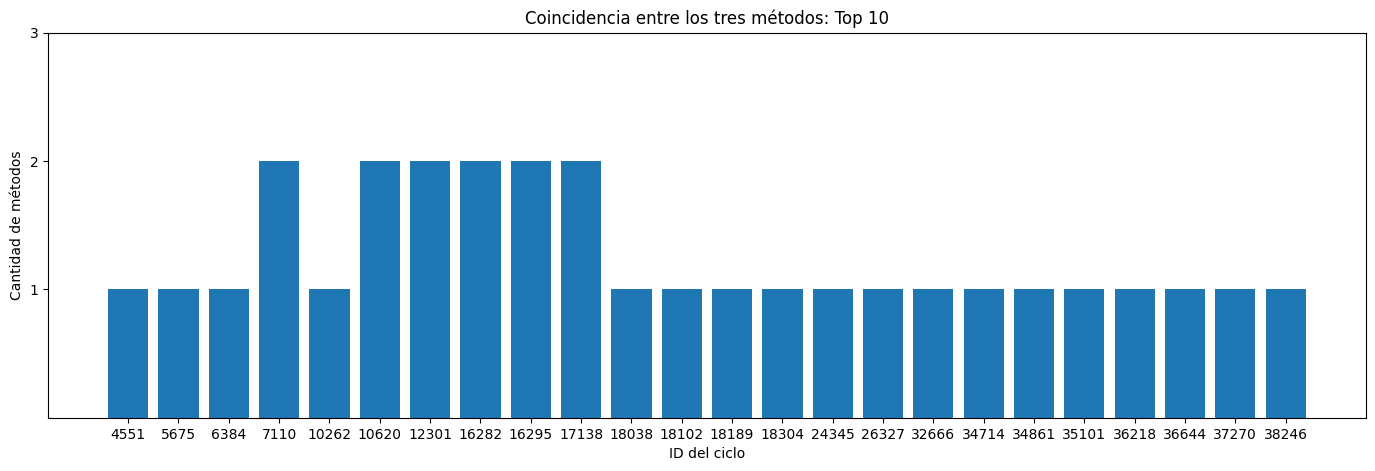

In [46]:
#A continuación una comparación entre los 3 métodos con el fin de observar cuáles fueron los resultados en común:
#Importación de matplotlib para gráficos
#!pip install matplotlib
import matplotlib.pyplot as plt

#Top 10:

top10_m = set(df.nlargest(10, 'mahalanobis_2')['id'])
top10_lof = set(df.nlargest(10, 'lof')['id'])
top10_if = set(df.nlargest(10, 'isolation_forest')['id'])
ids = sorted(top10_m | top10_lof | top10_if)
frecuencia = [sum(i in grupo for grupo in [top10_m, top10_lof, top10_if]) for i in ids]

plt.figure(figsize=(17, 5))
plt.bar([str(i) for i in ids], frecuencia)
plt.xlabel('ID del ciclo')
plt.ylabel('Cantidad de métodos')
plt.title('Coincidencia entre los tres métodos: Top 10')
plt.yticks([1, 2, 3])
plt.show()

La comparación de los resultados permitió identificar cinco observaciones que aparecen entre los diez registros con mayor puntuación de anomalía en dos de los métodos utilizados.

Estas observaciones serán examinadas con mayor detalle para identificar características compartidas y evaluar si presentan inconsistencias o comportamientos atípicos que justifiquen un tratamiento particular.

Es importante señalar que la coincidencia entre métodos constituye un criterio de revisión, pero no implica automáticamente que los registros deban eliminarse.

In [47]:
#intersección de conjuntos
df_outliers_6 = pd.DataFrame({"Art": ids,"Frecuencia Union 2": frecuencia}).sort_values("Frecuencia Union 2",ascending = False).head(6)
print(df_outliers_6)


#Conversión de los Números de artículo con métodos coincidentes a lista:
list_outliers_6 = df_outliers_6["Art"].to_list()
print(f"\n{list_outliers_6}")


     Art  Frecuencia Union 2
3   7110                   2
7  16282                   2
6  12301                   2
5  10620                   2
9  17138                   2
8  16295                   2

[7110, 16282, 12301, 10620, 17138, 16295]


In [48]:
#Filtrado del dataframe para los artículos con métodos coincidentes:
df[df["id"].isin(list_outliers_6)]



,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,average_token_length,...,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares,id,mahalanobis_2,lof,atipico_lof,isolation_forest,atipico_if
7109,9.0,299.0,0.559322032002,0.999999994286,0.731428567249,4.0,3.0,1.0,0.0,4.64882943144,...,0.5000000000000,0.000000000000,0.5000000000000,4200,7110,2190.491269567188283,8.002045545602773,True,-0.013944708082941,False
10619,11.0,358.0,0.575581393676,0.999999995146,0.733009705180,8.0,6.0,1.0,0.0,4.82681564246,...,0.0666666666667,0.266666666667,0.0666666666667,20000,10620,6455.424726791839930,7.938247608181176,True,-0.049500182227056,False
12300,9.0,200.0,0.572864318729,0.999999991597,0.714285708283,5.0,3.0,0.0,1.0,4.73500000000,...,-0.0500000000000,0.200000000000,0.0500000000000,478,12301,6341.846011471475322,11.228104459399979,True,-0.023856567490358,False
16281,8.0,192.0,0.697297293528,0.999999992857,0.735714280459,13.0,1.0,0.0,1.0,4.80208333333,...,-0.5000000000000,0.500000000000,0.5000000000000,17300,16282,6215.869334832545064,17.756705406788491,True,-0.023926397383392,False
16294,13.0,162.0,0.716049378296,0.999999990654,0.850467281771,8.0,7.0,0.0,0.0,4.80864197531,...,0.3000000000000,0.050000000000,0.3000000000000,555,16295,12031.654325436720683,15.837117420828227,True,0.000387463881926,True
17137,11.0,478.0,0.573275860833,0.999999996377,0.768115939246,4.0,0.0,0.0,1.0,4.68410041841,...,0.0000000000000,0.500000000000,0.0000000000000,1300,17138,8179.228634358915770,12.839278403783741,True,-0.064782757609562,False


*Las* seis observaciones identificadas presentan valores de n_non_stop_words muy próximos a 1 y fueron seleccionadas por su elevada puntuación en dos de los métodos de detección de anomalías.

Sin embargo, la presencia de estos valores no demuestra por sí sola que exista un error de carga o imputación, ya que se trata de una variable expresada como proporción.

Por este motivo, se conservarán los cinco registros en el conjunto de datos para los análisis posteriores. Su identificación se utilizará como información complementaria al interpretar los resultados de los modelos predictivos.

---

## 3. ANÁLISIS EXPLORATORIO Y DESCRIPTIVO

### 3.1 Estadísticos descriptivos


In [49]:
# 3.1 Estadísticos descriptivos
# Resumen de las variables numericas: media, dispersion, rango y cuartiles.
pd.set_option('display.precision', 3)

estadisticos = df[cols_cuantitativas + ['shares']].describe().T
estadisticos = estadisticos[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]

estadisticos

,count,mean,std,min,25%,50%,75%,max
n_tokens_title,39643.0,10.399,2.114,2.000,9.000,10.000,12.000,23.000
n_tokens_content,39643.0,546.489,471.085,0.000,246.000,409.000,716.000,8474.000
n_unique_tokens,39643.0,0.531,0.137,0.000,0.471,0.539,0.609,1.000
n_non_stop_words,39643.0,0.970,0.170,0.000,1.000,1.000,1.000,1.000
n_non_stop_unique_tokens,39643.0,0.673,0.154,0.000,0.626,0.690,0.755,1.000
average_token_length,39643.0,4.548,0.844,0.000,4.478,4.664,4.855,8.042
num_keywords,39643.0,7.224,1.909,1.000,6.000,7.000,9.000,10.000
num_hrefs,39643.0,10.884,11.332,0.000,4.000,8.000,14.000,304.000
num_self_hrefs,39643.0,3.293,3.855,0.000,1.000,3.000,4.000,116.000
num_imgs,39643.0,4.543,8.306,0.000,1.000,1.000,4.000,128.000


Los estadísticos descriptivos muestran que las variables del dataset presentan escalas, rangos y niveles de dispersión heterogéneos. El análisis de medidas como la media, la mediana, los cuartiles y la desviación estándar permite caracterizar su comportamiento, identificar posibles asimetrías y detectar valores extremos. Estas diferencias son relevantes para comprender la estructura de los datos y orientar las decisiones de preparación y selección de variables para el posterior modelado predictivo.

In [50]:
# Seleccionamos un subconjunto de variables con interpretación directa en
# términos de "qué hace popular a un artículo", para el análisis descriptivo.
variables_interes = [c for c in [
    "n_tokens_content", "num_hrefs", "num_imgs", "num_videos",
    "num_keywords", "average_token_length", "global_sentiment_polarity",
    "title_subjectivity", "kw_avg_avg"
] if c in df.columns]

df[variables_interes].describe().T


,count,mean,std,min,25%,50%,75%,max
n_tokens_content,39643.0,546.489,471.085,0.000,246.000,409.000,716.000,8474.000
num_hrefs,39643.0,10.884,11.332,0.000,4.000,8.000,14.000,304.000
num_imgs,39643.0,4.543,8.306,0.000,1.000,1.000,4.000,128.000
num_videos,39643.0,1.250,4.108,0.000,0.000,0.000,1.000,91.000
num_keywords,39643.0,7.224,1.909,1.000,6.000,7.000,9.000,10.000
average_token_length,39643.0,4.548,0.844,0.000,4.478,4.664,4.855,8.042
global_sentiment_polarity,39643.0,0.119,0.097,-0.394,0.058,0.119,0.178,0.728
title_subjectivity,39643.0,0.282,0.324,0.000,0.000,0.150,0.500,1.000
kw_avg_avg,39643.0,3135.864,1318.167,0.000,2382.443,2870.047,3600.312,43567.660


|Dimensión|	Variables|	Qué permiten explorar|
| :--- | :--- | :--- |
| **Extensión del contenido** |	n_tokens_content, average_token_length.	| Longitud del artículo y longitud media de sus palabras. |
| **Enlaces y recursos visuales** |	num_hrefs, num_imgs, num_videos.	| Incorporación de enlaces, imágenes y videos. |
| **Organización temática** | num_keywords, kw_avg_avg.	| Cantidad de palabras clave y promedio de popularidad de las palabras clave. |
| **Sentimiento y subjetividad** |	global_sentiment_polarity, title_subjectivity.	| Polaridad del contenido y subjetividad del título. |

#### `Justificación de inclusión` ####

Para profundizar el análisis descriptivo, se seleccionó un subconjunto de nueve variables que representan diferentes dimensiones de los artículos: extensión del contenido, recursos multimedia, enlaces, organización temática y características subjetivas y emocionales. La selección busca facilitar la interpretación de los datos y explorar posibles factores asociados con la cantidad de veces que se comparte un artículo (`shares`). Estas variables se consideran candidatas para el posterior análisis predictivo, sin asumir de antemano que todas tendrán capacidad explicativa.


### 3.2 Análisis de la variable objetivo: `shares`


In [51]:
# 3.2 Análisis de la variable objetivo: shares
# Se resumen los principales momentos de la distribución y
# se grafican sus medidas más importantes.

resumen_shares = df['shares'].describe()
percentiles_shares = df['shares'].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])

print('Resumen estadístico de shares:')
print(resumen_shares)
print("Asimetría:", df["shares"].skew())

print()

print('Percentiles relevantes:')
print(percentiles_shares)


Resumen estadístico de shares:
count     39643.000
mean       3395.317
std       11627.091
min           1.000
25%         946.000
50%        1400.000
75%        2800.000
max      843300.000
Name: shares, dtype: float64
Asimetría: 33.963532229397046

Percentiles relevantes:
0.01      381.0
0.05      584.0
0.25      946.0
0.50     1400.0
0.75     2800.0
0.90     6200.0
0.95    10800.0
0.99    31658.0
Name: shares, dtype: float64




`distribución está sesgada hacia la derecha`:
La media es de 3.395 shares, mientras que la mediana es de apenas 1.400. Esto sugiere que algunos artículos con muchísimos compartidos elevan el promedio.




`La mitad de los artículos tiene 1.400 shares o menos`:
La mediana divide las observaciones en dos mitades: aproximadamente el 50% tiene hasta 1.400 compartidos y el otro 50% tiene al menos esa cantidad.




`Gran dispersión`:
La desviación estándar es de aproximadamente 11.627 shares, más de tres veces la media. Esto indica una variabilidad muy elevada, aunque parte de ella puede deberse a valores extremos.




`Artículos extraordinariamente populares`:
El máximo es de 843.300 shares, frente a una mediana de 1.400. El máximo equivale a más de 600 veces la mediana, lo que sugiere la presencia de valores extremos.

`Funcion Calcular_bins`: Se define una función que calcula la cantidad de intervalos (*bins*) necesarios para dividir el rango de una variable numérica en intervalos de ancho fijo.

La función recibe el DataFrame, el nombre de la columna y el tamaño deseado para cada intervalo. Luego divide el valor máximo de la variable por el tamaño del intervalo y redondea el resultado hacia arriba para obtener una cantidad entera de intervalos.

In [52]:
def calcular_bins(df, columna, tamaño_intervalo):
    valor_maximo = df[columna].max()
    # Convertimos a int porque NumPy devuelve un float (ej: 800.0) y 'bins' requiere un entero
    return int(np.ceil(valor_maximo / tamaño_intervalo))
print(f"la cantidad bins para la columna shares con  intervalos de 3000 es {calcular_bins(df,'shares',3000)}")

la cantidad bins para la columna shares con  intervalos de 3000 es 282


Esta función queda definida como utilidad general para binning de ancho fijo; en los histogramas que siguen se usa, en cambio, un número de bins elegido manualmente (`bins=60`) por legibilidad visual, no el valor de 282 que calcularía `calcular_bins(df, "shares", 3000)` para el rango completo. Se deja la función disponible por si se la necesita más adelante para un binning equiespaciado.

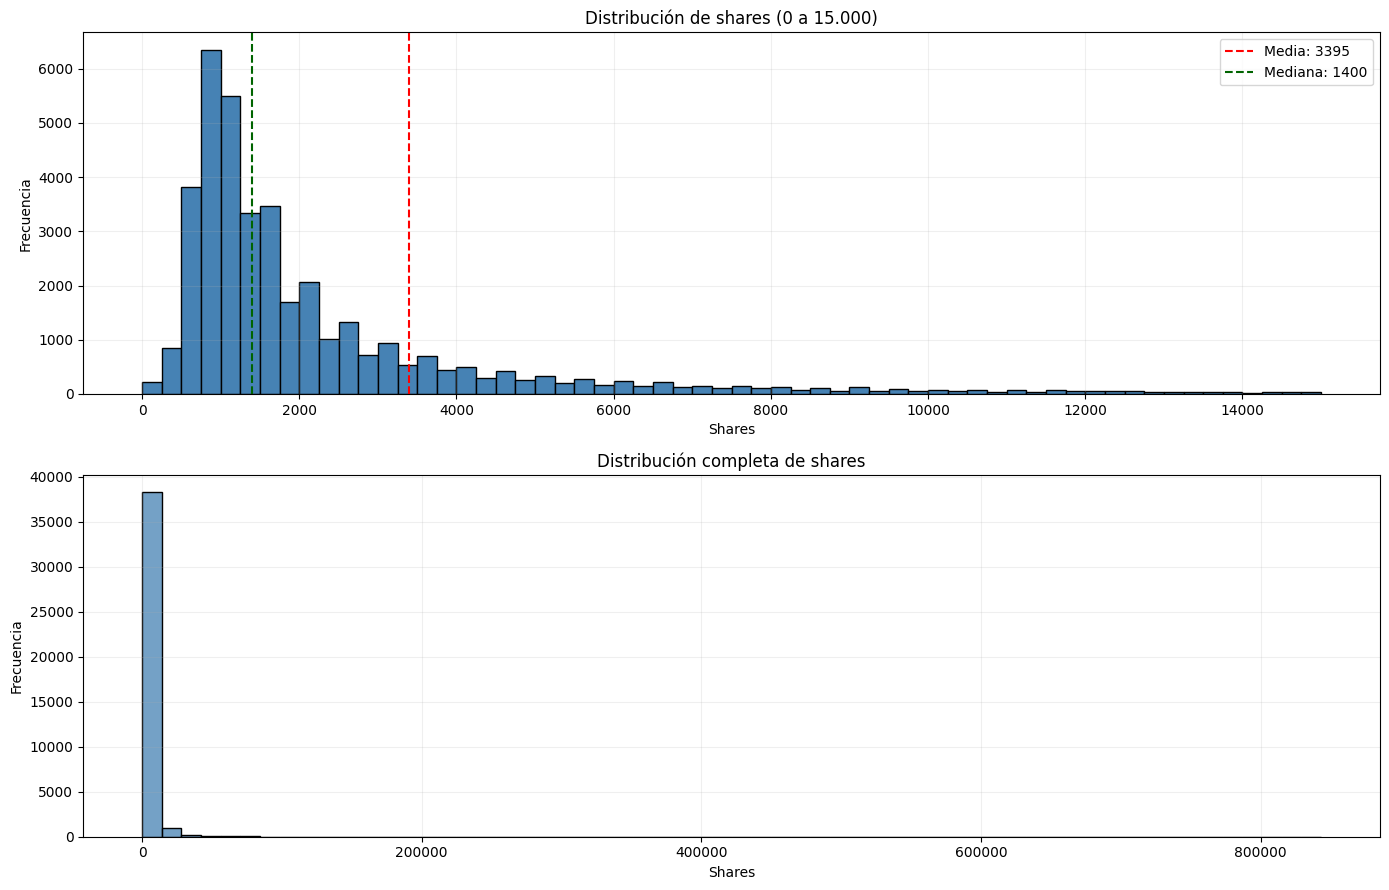

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

media = df["shares"].mean()
mediana = df["shares"].median()

# Histograma de la zona principal
df["shares"].hist(
    bins=60,
    range=(0, 15000),
    ax=axes[0],
    color="steelblue",
    edgecolor="black"
)

axes[0].axvline(
    media,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Media: {media:.0f}"
)

axes[0].axvline(
    mediana,
    color="darkgreen",
    linestyle="--",
    linewidth=1.5,
    label=f"Mediana: {mediana:.0f}"
)

axes[0].set_title("Distribución de shares (0 a 15.000)")
axes[0].set_xlabel("Shares")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Histograma de la distribución completa
sns.histplot(
    data=df,
    x="shares",
    bins=60,
    ax=axes[1],
    color="steelblue",
    edgecolor="black"
)

axes[1].set_title("Distribución completa de shares")
axes[1].set_xlabel("Shares")
axes[1].set_ylabel("Frecuencia")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

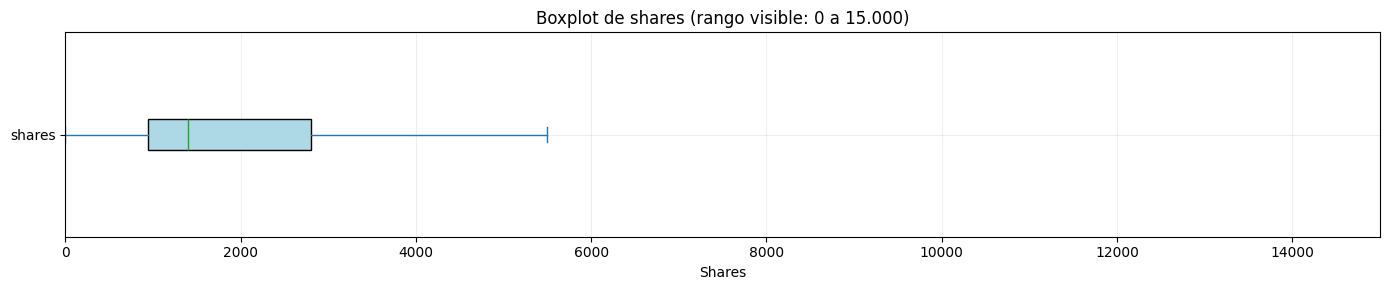

In [54]:
plt.figure(figsize=(14, 3))

df["shares"].plot.box(
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue"),
    showfliers=False
)

plt.xlim(0, 15000)
plt.title("Boxplot de shares (rango visible: 0 a 15.000)")
plt.xlabel("Shares")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

\[
RIC = Q3-Q1=2800-946=1854
\]

\[
Límite superior=2800+1.5(1854)=5581
\]

Por lo tanto, los artículos con más de 5.581 shares se consideran potenciales valores atípicos según este criterio.
Esto no significa necesariamente que sean errores: podrían representar artículos que alcanzaron una popularidad excepcional.

La variable *shares* presenta una distribución fuertemente asimétrica hacia la derecha, caracterizada por una elevada concentración de observaciones en valores bajos y la presencia de valores extremos superiores.

La media (3.395) es considerablemente mayor que la mediana (1.400), lo que evidencia la influencia de artículos con una cantidad excepcionalmente alta de compartidos.

Asimismo, el 50 % central de las observaciones se encuentra entre 946 y 2.800 shares, mientras que el valor máximo alcanza los 843.300, reflejando una importante dispersión.

En consecuencia, `la mediana resulta más representativa que la media para describir el comportamiento típico de la variable shares`, debido a su menor sensibilidad a los valores extremos.

Se elaboraron dos gráficos con diferentes escalas para facilitar la interpretación de la distribución de `shares`. Debido a la presencia de artículos con cantidades excepcionalmente elevadas de compartidos, un único gráfico dificultaba visualizar la concentración de observaciones en los valores más bajos. Por este motivo, se presenta una visualización de la distribución completa y otra ampliada sobre el rango de valores más frecuentes.

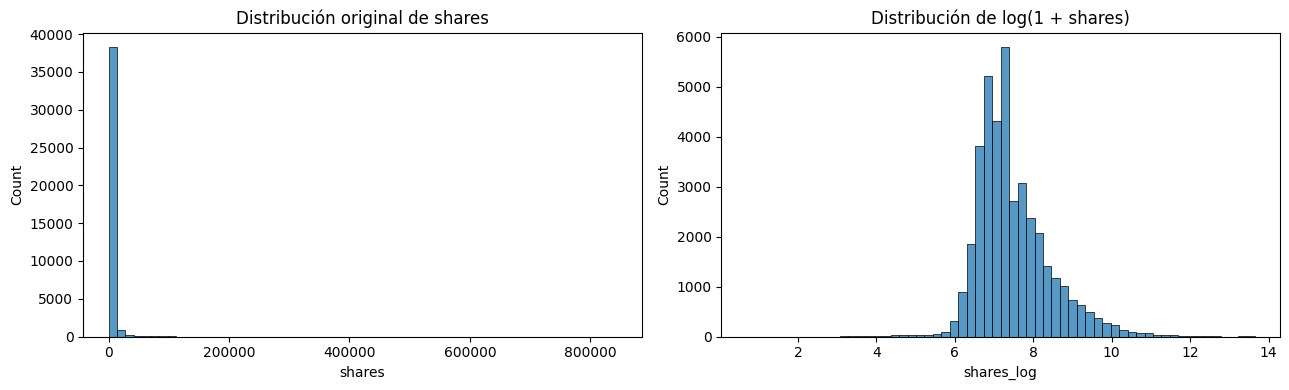

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
#nos permite acceder a dos graficos

sns.histplot(df["shares"], bins=60, ax=axes[0])#ax=axes[0]: es el primer grafico (el de la izquierda)
axes[0].set_title("Distribución original de shares")

df["shares_log"] = np.log1p(df["shares"])

sns.histplot(df["shares_log"], bins=60, ax=axes[1])
axes[1].set_title("Distribución de log(1 + shares)")

plt.tight_layout()
plt.show()


Se crea una nueva variable, `shares_log`, mediante la transformación logarítmica `log1p(shares)`. Esta decisión se fundamenta en la elevada asimetría positiva de la variable

original y en la presencia de valores extremos. La transformación reduce la escala de los valores más elevados, lo que puede facilitar el entrenamiento de modelos predictivos y

disminuir la influencia de las diferencias absolutas extremas. Se conserva la variable original para interpretar los resultados en términos de cantidad de compartidos y

comparar el desempeño de los modelos con y sin transformación.

In [56]:
# Casos atípicos estadísticos según IQR (umbral = Q3 + 1.5*RIC = 2800 + 1.5*1854 = 5581,
# tal como se calculó en la celda anterior; antes decía 5574 por error de transcripción).
outliers_iqr = df[df['shares'] > 5581]
# Casos ultra virales (corte editorial, no estadístico: artículos que multiplican
# muchas veces el límite anterior).
ultra_virales = df[df['shares'] > 50000]
print(f"outliers iqr:{len(outliers_iqr)} y ultravirales: {len(ultra_virales)}")


outliers iqr:4540 y ultravirales: 203


La variable `shares` confirma, con evidencia numérica, el diagnóstico cualitativo de 3.1: asimetría positiva muy fuerte (coeficiente de asimetría ≈ 34), media muy por encima de la mediana y una cola derecha extensa que llega hasta 843.300 shares frente a una mediana de apenas 1.400. El criterio de Tukey (Q3 + 1,5·RIC = 5.581) y el corte editorial de "ultra viral" (> 50.000) reportados en la celda anterior cuantifican cuántos artículos caen en esa cola; ninguno de esos registros debe eliminarse sin revisión, porque no hay evidencia de que sean errores de carga y sí de que representan episodios reales de alta viralidad. Esta asimetría es la razón concreta por la que se trabaja con `shares_log = log1p(shares)` en el resto del análisis y en el modelado: comprime la escala sin descartar información y permite que los supuestos de los modelos lineales sean más razonables.


### 3.3 Distribución de las variables


A partir de las nueve variables seleccionadas en 3.1 (`variables_interes`), se eligieron cinco para representar gráficamente sus distribuciones: `n_tokens_content`, `num_hrefs`, `num_imgs`, `average_token_length` y `global_sentiment_polarity`. Además, se incorporaron dos variables que no forman parte de ese conjunto original —`n_tokens_title` (extensión del título) e `is_weekend` (publicación en fin de semana)— porque aportan una lectura estructural y temporal directa que complementa a las nueve seleccionadas, y porque `is_weekend` se retoma más adelante al plantear hipótesis sobre el día de publicación (sección 4.3). Las cuatro variables restantes de 3.1 (`num_videos`, `num_keywords`, `title_subjectivity`, `kw_avg_avg`) no se graficaron para evitar una presentación excesivamente extensa, pero sus medidas descriptivas ya se calcularon y presentaron en 3.1.


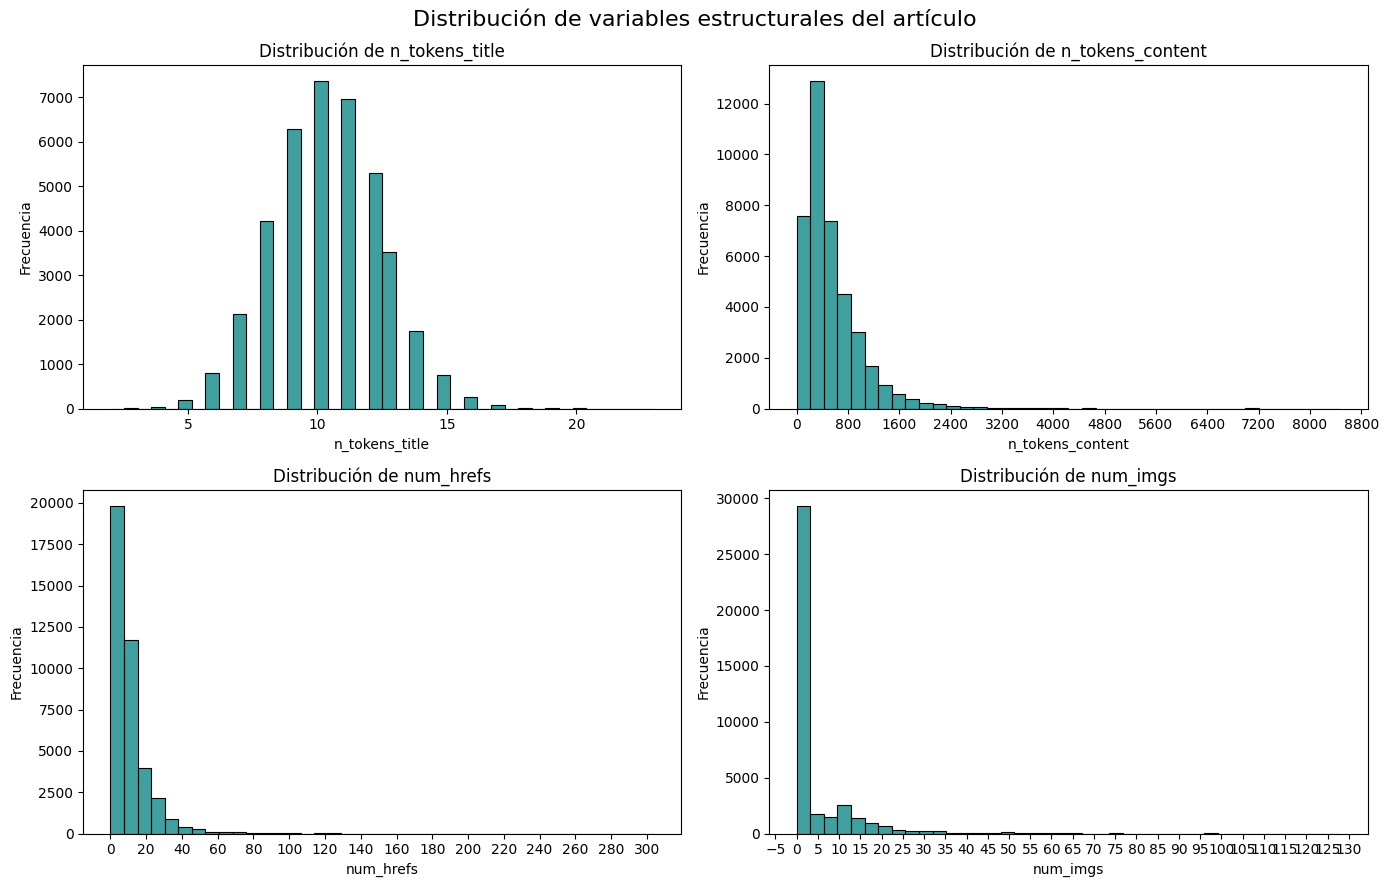

In [57]:

import matplotlib.ticker as ticker
import os

os.makedirs("imagenes", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

variables_1 = [
    "n_tokens_title",
    "n_tokens_content",
    "num_hrefs",
    "num_imgs"
]

for i, col in enumerate(variables_1):
    sns.histplot(
        data=df,
        x=col,
        bins=40,
        ax=axes[i],
        color="teal",
        edgecolor="black"
    )

    axes[i].set_title(f"Distribución de {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")

# Ajustes de los ejes X
axes[0].xaxis.set_major_locator(ticker.MultipleLocator(5))
axes[1].xaxis.set_major_locator(ticker.MultipleLocator(800))
axes[2].xaxis.set_major_locator(ticker.MultipleLocator(20))
axes[3].xaxis.set_major_locator(ticker.MultipleLocator(5))

fig.suptitle(
    "Distribución de variables estructurales del artículo",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "imagenes/distribucion_estructura_articulo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

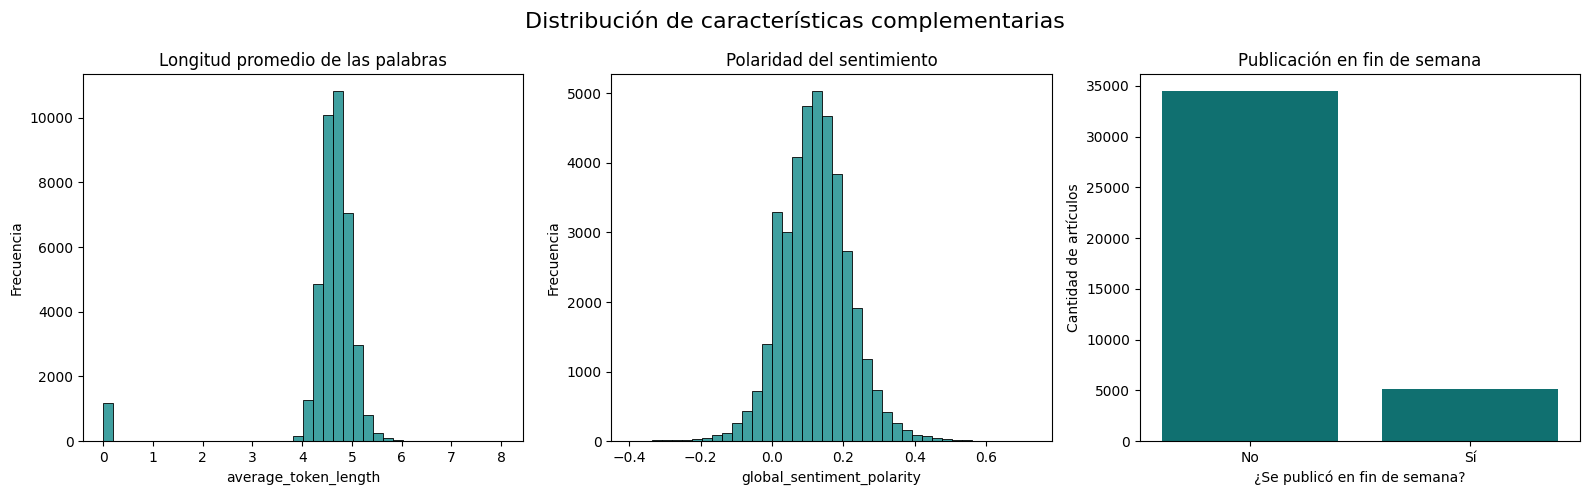

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

variables_2 = [
    "average_token_length",
    "global_sentiment_polarity",
    "is_weekend"
]

# Longitud promedio de las palabras
sns.histplot(
    data=df,
    x="average_token_length",
    bins=40,
    ax=axes[0],
    color="teal",
    edgecolor="black"
)
axes[0].set_title("Longitud promedio de las palabras")
axes[0].set_xlabel("average_token_length")
axes[0].set_ylabel("Frecuencia")

# Polaridad del sentimiento
sns.histplot(
    data=df,
    x="global_sentiment_polarity",
    bins=40,
    ax=axes[1],
    color="teal",
    edgecolor="black"
)
axes[1].set_title("Polaridad del sentimiento")
axes[1].set_xlabel("global_sentiment_polarity")
axes[1].set_ylabel("Frecuencia")

# Publicación en fin de semana
sns.countplot(
    data=df,
    x="is_weekend",
    ax=axes[2],
    color="teal"
)
axes[2].set_title("Publicación en fin de semana")
axes[2].set_xlabel("¿Se publicó en fin de semana?")
axes[2].set_ylabel("Cantidad de artículos")
axes[2].set_xticks([0, 1], labels=["No", "Sí"])

fig.suptitle(
    "Distribución de características complementarias",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "imagenes/distribucion_caracteristicas_complementarias.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Interpretación de los gráficos

El conjunto de datos contiene **39.643 observaciones**. Previamente, se calcularon los estadísticos descriptivos de las variables seleccionadas, cuyos valores de media, mediana, cuartiles y máximos se utilizan como referencia para la interpretación. Los histogramas permiten visualizar la forma de las distribuciones de las variables representadas, mientras que el gráfico de barras permite comparar la frecuencia de publicación entre días de semana y fines de semana. Como se aclaró en 3.3, dos de las variables graficadas (`n_tokens_title` e `is_weekend`) no forman parte del conjunto original de nueve variables de 3.1, sino que se agregaron para completar la lectura estructural y temporal.

No todas las variables seleccionadas fueron incluidas en los gráficos. Por este motivo, las variables `num_videos`, `num_keywords`, `title_subjectivity` y `kw_avg_avg` se describen a partir de sus estadísticos descriptivos, sin atribuirles patrones visuales que no se observan en las figuras.

### Figura 1. Distribución de variables estructurales del artículo

- **Extensión del artículo (`n_tokens_content`):** el promedio es de **546,5 palabras** y la mediana de **409**. La mitad central de los artículos tiene entre **246 y 716 palabras**. El histograma muestra una distribución marcadamente asimétrica hacia la derecha: la mayoría de los artículos se concentra en longitudes relativamente bajas, mientras que unos pocos presentan extensiones mucho mayores, con un máximo de **8.474 palabras**. Por esta razón, la mediana representa mejor la extensión de un artículo típico que el promedio.

- **Cantidad de enlaces (`num_hrefs`):** la mediana es de **8 enlaces**, con un primer cuartil de **4** y un tercer cuartil de **14**. El máximo alcanza los **304 enlaces**. Esta diferencia entre los valores centrales y el máximo sugiere una distribución con una cola hacia valores altos. Por lo tanto, la cantidad de enlaces varía entre artículos y algunos casos extremos pueden influir en el promedio.

- **Cantidad de imágenes (`num_imgs`):** la mediana es de **1 imagen** y el tercer cuartil es de **4**, mientras que el máximo alcanza las **128 imágenes**. El histograma concentra muchas observaciones en cantidades bajas y presenta una cola hacia valores altos. El promedio de **4,5 imágenes** resulta superior a la mediana, lo que es consistente con la influencia de artículos que contienen muchas imágenes.

- **Cantidad de palabras en el título (`n_tokens_title`):** el histograma permite observar cómo se distribuye la extensión de los títulos. Su interpretación debe complementarse con los estadísticos descriptivos para identificar el valor típico, la dispersión y la posible presencia de valores extremos.

### Figura 2. Distribución de características complementarias

- **Longitud promedio de las palabras (`average_token_length`):** la mediana es de **4,66 caracteres** y el promedio de **4,55**. La proximidad entre ambos valores sugiere que las medidas de tendencia central son relativamente similares, aunque la forma de la distribución debe evaluarse a partir del histograma.

- **Polaridad global del sentimiento (`global_sentiment_polarity`):** la distribución se centra alrededor de **0,12**, con una mediana de **0,119**. El histograma permite observar la concentración de los valores y la presencia de observaciones tanto negativas como positivas. La polaridad resume la orientación sentimental del texto, pero no permite determinar por sí sola si un artículo será más popular.

- **Día de publicación (`is_weekend`):** el gráfico de barras muestra una mayor cantidad de publicaciones durante los días de semana que durante los fines de semana. Las barras representan cantidades de artículos, no tasas de compartidos ni niveles de popularidad.

### Variables no representadas gráficamente

Las siguientes variables fueron consideradas en los estadísticos descriptivos, pero no se incluyeron en las figuras:

- **Cantidad de videos (`num_videos`):** la mediana es **0** y el tercer cuartil es **1**, lo que indica que al menos la mitad de los artículos no contiene videos y que el 75 % registra, como máximo, un video.

- **Cantidad de palabras clave (`num_keywords`):** la distribución de los valores descriptivos se concentra entre **6 y 9 palabras clave** (Q1: 6; mediana: 7; Q3: 9), con un rango observado de 1 a 10.

- **Subjetividad del título (`title_subjectivity`):** la mediana es **0,15** y el tercer cuartil es **0,50**, lo que indica variabilidad en los valores de subjetividad asignados a los títulos.

- **Promedio de popularidad de palabras clave (`kw_avg_avg`):** la mediana es **2.870** y el 75 % de los casos no supera **3.600**, mientras que el máximo llega a **43.568**. La diferencia entre el promedio (**3.136**) y la mediana sugiere la posible influencia de valores altos. Esta variable resume el promedio de popularidad de las palabras clave del artículo y no debe confundirse con la cantidad de compartidos (`shares`).

### Conclusión

Las variables presentan diferentes patrones de distribución. La extensión de los artículos, la cantidad de enlaces y la cantidad de imágenes muestran indicios de colas hacia valores altos, por lo que sus promedios pueden diferir de los valores típicos. Los estadísticos descriptivos de las variables no representadas gráficamente también permiten identificar diferencias en la cantidad de videos, palabras clave y en las características del título y de las palabras clave.

En cambio, la polaridad global se concentra alrededor de valores ligeramente positivos, mientras que las publicaciones de días de semana son más numerosas que las de fines de semana.

Estas observaciones son **descriptivas**: los histogramas y los estadísticos univariados no permiten concluir que una característica cause más compartidos ni establecer por sí solos su asociación con `shares`. Estas relaciones deberán analizarse posteriormente mediante técnicas bivariadas y modelos predictivos. Asimismo, los valores extremos no deben eliminarse sin comprobar antes si representan errores o casos válidos.


**`Aclaración metodológica`:** Los valores de la media, la mediana, los cuartiles y los máximos mencionados en la siguiente interpretación se obtuvieron de la tabla de estadísticos descriptivos presentada en la sección anterior. Los histogramas complementan esos resultados al permitir visualizar la forma de las distribuciones, su asimetría y la concentración de las observaciones. Por su parte, el gráfico de barras permite comparar la frecuencia de publicación entre días de semana y fines de semana.

### 3.4 Análisis de relaciones entre variables




Antes de acotar el análisis a un subconjunto de variables, se lista el conjunto completo de variables cuantitativas disponibles (`cols_cuantitativas`), para que quede explícito a partir de qué universo se eligieron las seis que se usan en la matriz de dispersión siguiente.

In [59]:
print(cols_cuantitativas)
#vars_relacion = cols_cuantitativas + ['shares']

['n_tokens_title', 'n_tokens_content', 'n_unique_tokens', 'n_non_stop_words', 'n_non_stop_unique_tokens', 'average_token_length', 'num_keywords', 'num_hrefs', 'num_self_hrefs', 'num_imgs', 'num_videos', 'kw_min_min', 'kw_max_min', 'kw_avg_min', 'kw_min_max', 'kw_max_max', 'kw_avg_max', 'kw_min_avg', 'kw_max_avg', 'kw_avg_avg', 'self_reference_min_shares', 'self_reference_max_shares', 'self_reference_avg_sharess', 'LDA_00', 'LDA_01', 'LDA_02', 'LDA_03', 'LDA_04', 'global_subjectivity', 'global_sentiment_polarity', 'global_rate_positive_words', 'global_rate_negative_words', 'rate_positive_words', 'rate_negative_words', 'avg_positive_polarity', 'min_positive_polarity', 'max_positive_polarity', 'avg_negative_polarity', 'min_negative_polarity', 'max_negative_polarity', 'title_subjectivity', 'title_sentiment_polarity', 'abs_title_subjectivity', 'abs_title_sentiment_polarity']


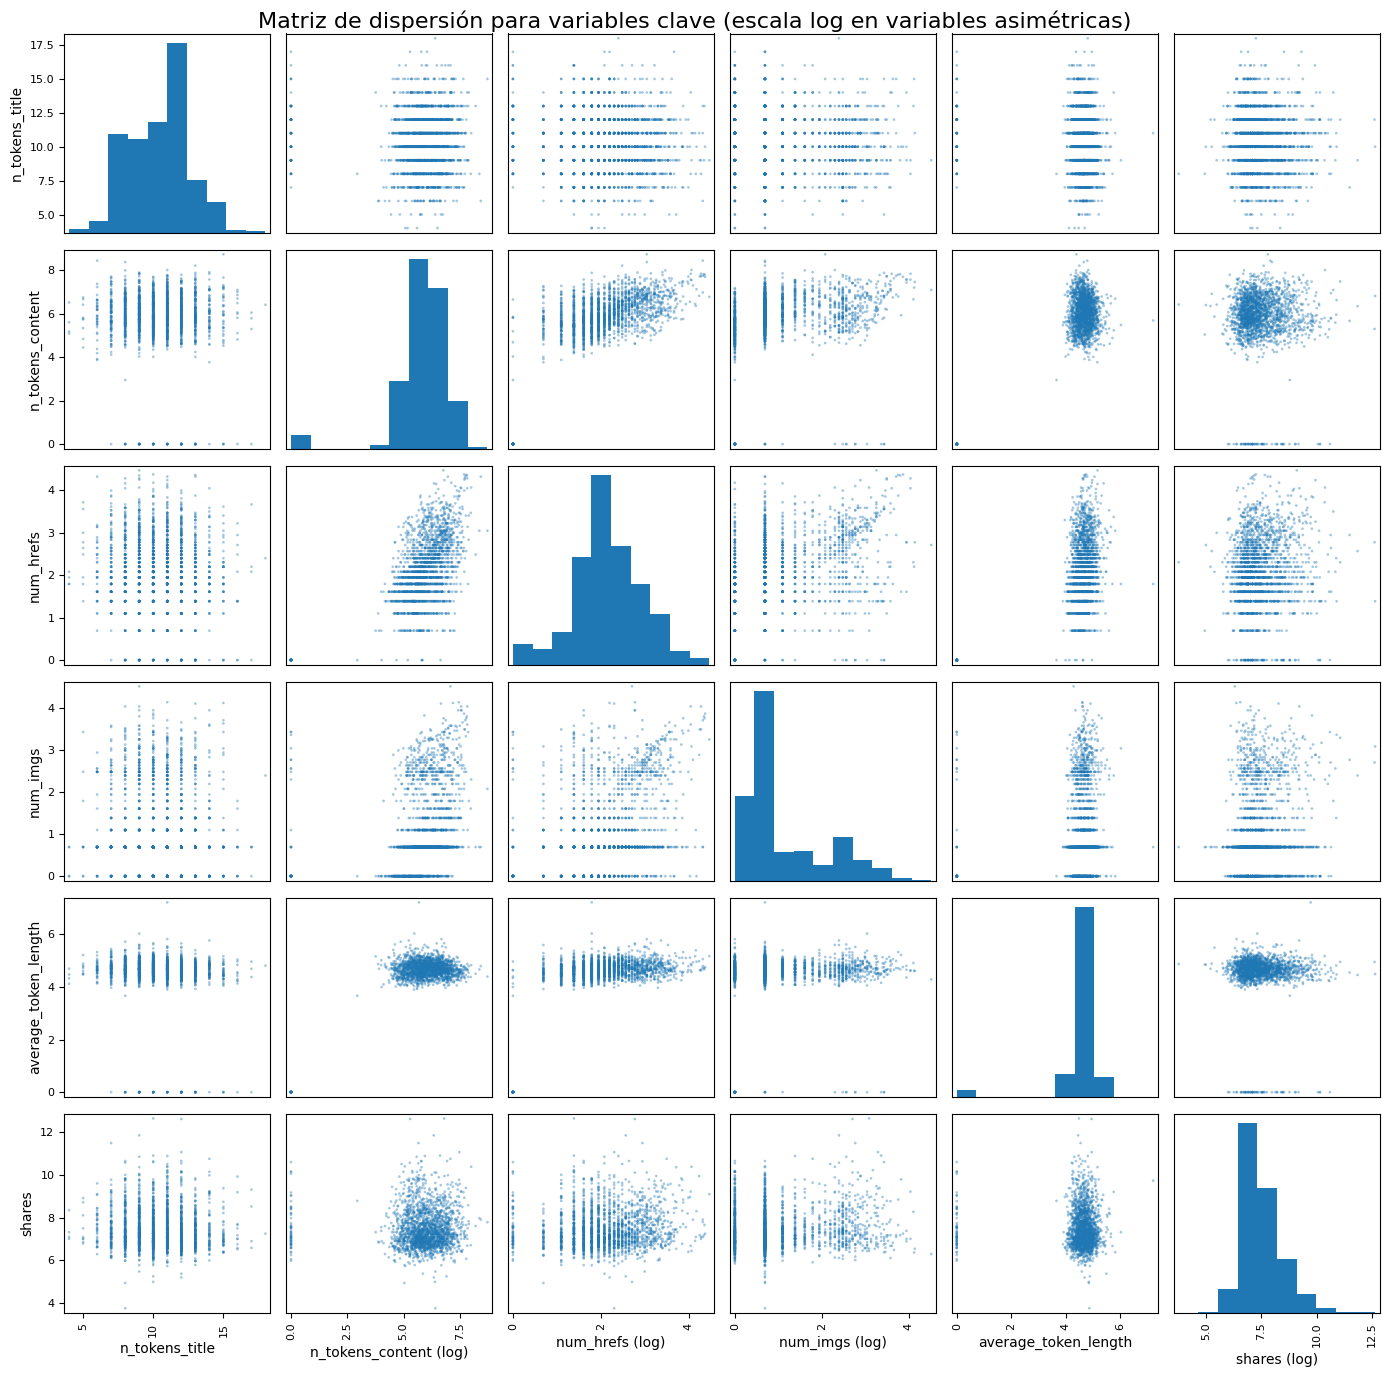

In [60]:
vars_relacion = ['n_tokens_title', 'n_tokens_content', 'num_hrefs', 'num_imgs', 'average_token_length', 'shares']
muestra = df[vars_relacion].sample(n=min(2000, len(df)), random_state=42).copy()

# log1p evita problemas con ceros (log(0) no está definido) escala logarítmica
for col in ['n_tokens_content', 'num_hrefs', 'num_imgs', 'shares']:
    muestra[col] = np.log1p(muestra[col])

ejes = pd.plotting.scatter_matrix(muestra, figsize=(14, 14), alpha=0.4, diagonal='hist', s=15)
for ax in ejes.flatten():
    ax.set_xlabel(ax.get_xlabel() + ' (log)' if ax.get_xlabel() in ['n_tokens_content','num_hrefs','num_imgs','shares'] else ax.get_xlabel())
plt.suptitle('Matriz de dispersión para variables clave (escala log en variables asimétricas)', fontsize=16)
plt.tight_layout()
plt.savefig("imagenes/relaciones_entre_variables.png")
plt.show()


La matriz de dispersión permite explorar las relaciones bivariadas entre las seis variables seleccionadas. Para facilitar la visualización, se aplicó una transformación logarítmica a las variables de conteo más asimétricas (`n_tokens_content`, `num_hrefs`, `num_imgs` y `shares`).

Dentro de las relaciones observadas:

- **`n_tokens_content` con `num_hrefs` y `num_imgs`:** se pueden observar indicios de una asociación positiva débil. Los artículos más extensos tienden a presentar algo más de enlaces e imágenes, aunque existe una dispersión considerable.
- **`shares` con el resto de las variables:** no se observa un patrón bivariado claramente definido. Los artículos con diferentes cantidades de compartidos aparecen distribuidos en distintos valores de los predictores analizados.
- **`average_token_length`:** no presenta una relación visual marcada con las demás variables. Los valores iguales a cero deben interpretarse considerando que existen artículos con `n_tokens_content = 0`, por lo que no necesariamente representan errores de carga.

### Aporte para el modelado

La ausencia de relaciones bivariadas claramente definidas sugiere que ninguna de estas variables, considerada de manera aislada, permite explicar adecuadamente la popularidad de los artículos.

Esto justifica avanzar hacia un análisis multivariado, incorporando diferentes características en conjunto. También será necesario evaluar el comportamiento de los modelos y sus supuestos antes de decidir qué transformaciones aplicar a los predictores.

Por último, esta matriz permite explorar las relaciones entre las seis variables seleccionadas, pero no alcanza para descartar la existencia de multicolinealidad en el conjunto completo de predictores.

### 3.5 Matriz de correlación

El análisis se hace en tres pasos, cada uno con un propósito distinto: primero se calcula la correlación de `shares` (en su escala original) contra **todas** las variables cuantitativas, para tener un ranking completo sin descartar nada de antemano. Luego se repite ese cálculo incorporando `shares_log`, se compara con la versión original y se visualiza como mapa de calor completo (incluye también la multicolinealidad entre predictores). Por último, se arma un mapa de calor acotado a las nueve variables de interés de 3.1 más ambas versiones de `shares`, para una lectura más legible de ese subconjunto puntual.


In [61]:
# 3.5 Matriz de correlacion
# Calculamos la correlacion lineal entre las variables numericas para identificar asociaciones con la variable objetivo.
cols_corr = cols_cuantitativas + ['shares']
matriz_corr = df[cols_corr].corr().round(3)
matriz_corr

correlaciones_con_shares = (
    matriz_corr['shares'].drop(labels='shares')
    .sort_values(key=lambda s: s.abs(), ascending=False)
)
correlaciones_con_shares



kw_avg_avg                      0.110
LDA_03                          0.084
kw_max_avg                      0.064
LDA_02                         -0.059
self_reference_avg_sharess      0.058
self_reference_min_shares       0.056
self_reference_max_shares       0.047
kw_avg_max                      0.045
num_hrefs                       0.045
kw_min_avg                      0.040
num_imgs                        0.039
global_subjectivity             0.032
avg_negative_polarity          -0.032
kw_avg_min                      0.030
kw_max_min                      0.030
abs_title_sentiment_polarity    0.027
num_videos                      0.024
average_token_length           -0.022
title_subjectivity              0.022
num_keywords                    0.022
n_non_stop_unique_tokens       -0.020
n_non_stop_words               -0.020
max_negative_polarity          -0.019
min_negative_polarity          -0.019
LDA_04                         -0.017
title_sentiment_polarity        0.013
rate_positiv

kw_avg_avg                      0.110
LDA_03                          0.084
kw_max_avg                      0.064
LDA_02                         -0.059
self_reference_avg_sharess      0.058
self_reference_min_shares       0.056
self_reference_max_shares       0.047
kw_avg_max                      0.045
num_hrefs                       0.045
kw_min_avg                      0.040
num_imgs                        0.039
global_subjectivity             0.032
avg_negative_polarity          -0.032
kw_avg_min                      0.030
kw_max_min                      0.030
abs_title_sentiment_polarity    0.027
num_videos                      0.024
average_token_length           -0.022
title_subjectivity              0.022
num_keywords                    0.022
n_non_stop_unique_tokens       -0.020
n_non_stop_words               -0.020
max_negative_polarity          -0.019
min_negative_polarity          -0.019
LDA_04                         -0.017
title_sentiment_polarity        0.013
rate_positiv

kw_avg_avg                      0.222
LDA_02                         -0.165
LDA_03                          0.126
kw_min_avg                      0.109
kw_max_avg                      0.109
num_hrefs                       0.105
num_imgs                        0.091
self_reference_avg_sharess      0.087
self_reference_max_shares       0.077
global_subjectivity             0.075
self_reference_min_shares       0.073
num_keywords                    0.066
kw_avg_max                      0.060
n_non_stop_unique_tokens       -0.059
abs_title_sentiment_polarity    0.059
LDA_01                         -0.053
title_subjectivity              0.053
title_sentiment_polarity        0.051
global_sentiment_polarity       0.049
rate_negative_words            -0.048
LDA_04                          0.045
average_token_length           -0.045
global_rate_positive_words      0.041
kw_avg_min                      0.040
n_unique_tokens                -0.040
avg_positive_polarity           0.035
max_positive

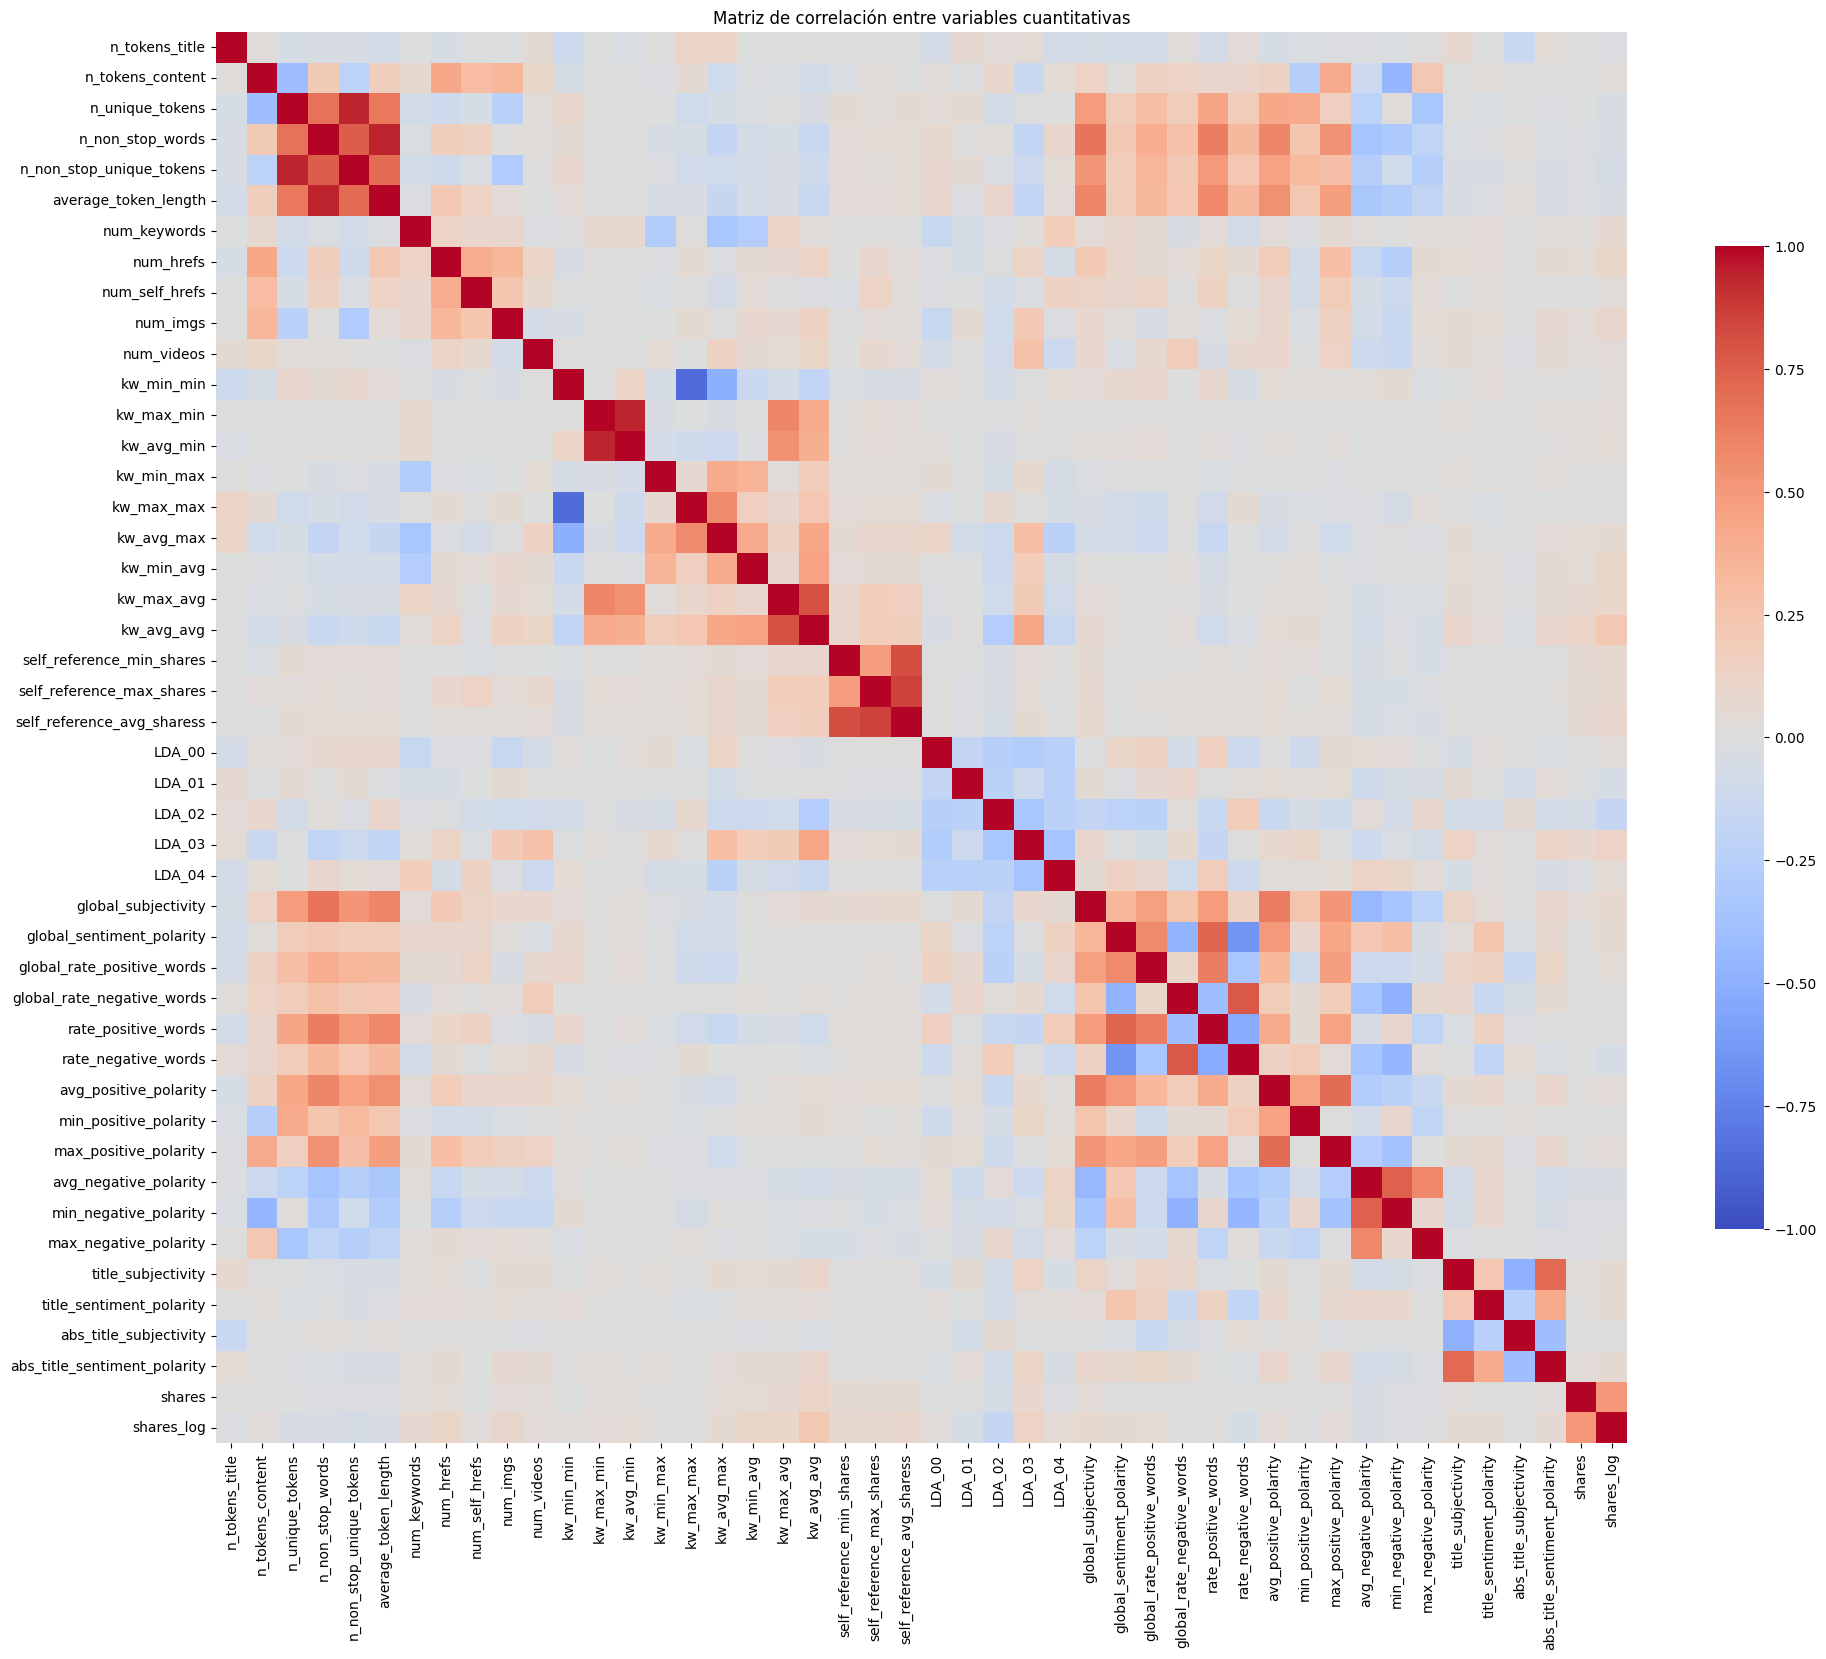

In [62]:
# 3.5 Matriz de correlación

os.makedirs("imagenes", exist_ok=True)

# Transformación de la variable objetivo
df["shares_log"] = np.log1p(df["shares"])

# Evitar duplicados y mantener las variables cuantitativas
cols_corr = list(dict.fromkeys(cols_cuantitativas + ["shares", "shares_log"]))

# Matriz de correlación
matriz_corr = df[cols_corr].corr().round(3)

# Correlaciones con shares original
correlaciones_con_shares = (
    matriz_corr["shares"]
    .drop(labels=["shares", "shares_log"], errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlaciones_con_shares)

# Correlaciones con shares_log
correlaciones_con_shares_log = (
    matriz_corr["shares_log"]
    .drop(labels=["shares", "shares_log"], errors="ignore")
    .sort_values(key=lambda s: s.abs(), ascending=False)
)

display(correlaciones_con_shares_log)

# Matriz completa
plt.figure(figsize=(20, 18))

sns.heatmap(
    matriz_corr,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot=False,
    cbar_kws={"shrink": 0.6}
)

plt.title("Matriz de correlación entre variables cuantitativas")
plt.tight_layout()

plt.savefig(
    "imagenes/matriz_correlaciones_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

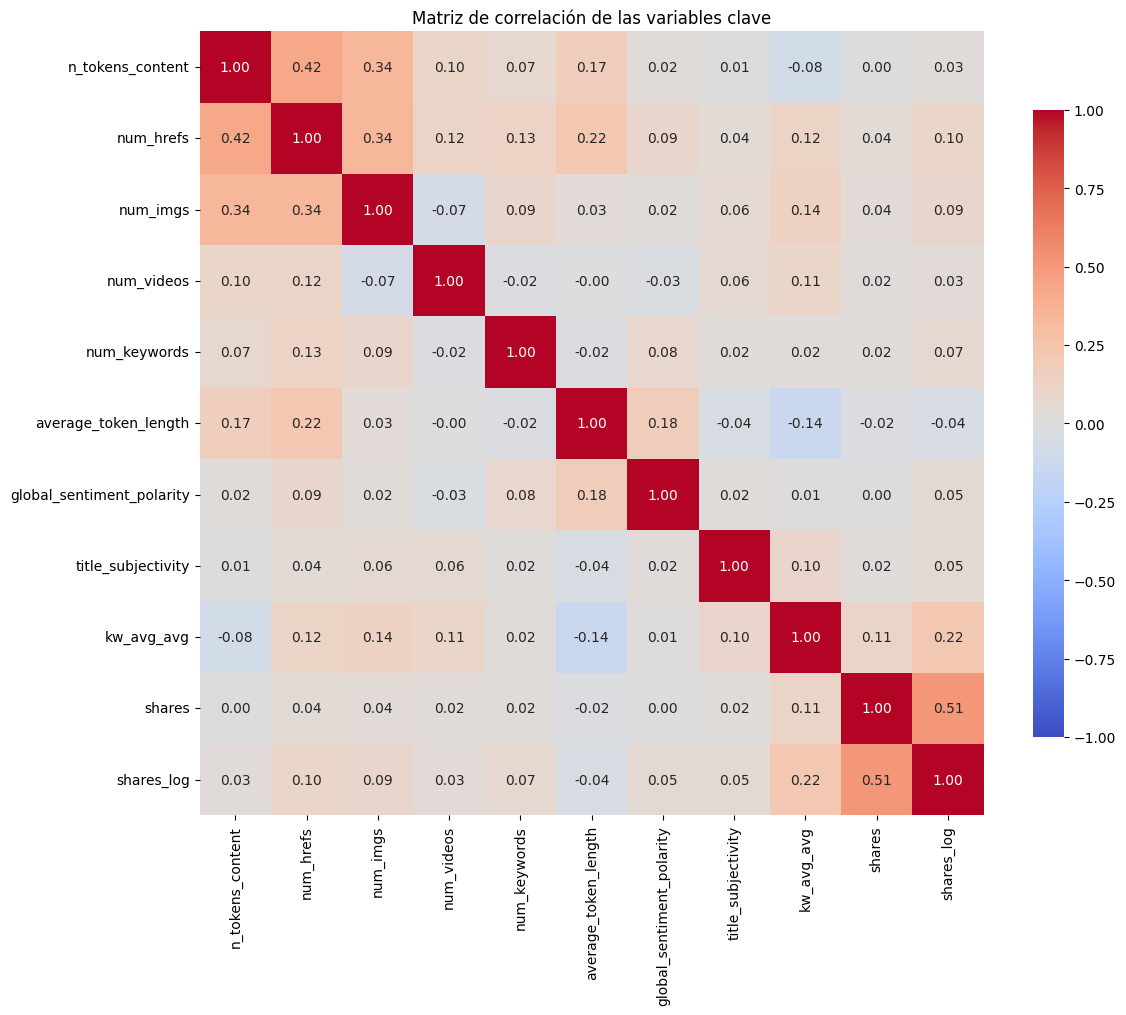

In [63]:
# 3.5 Matriz de correlación: variables clave


os.makedirs("imagenes", exist_ok=True)

# Las 9 variables seleccionadas
cols_clave = [
    "n_tokens_content",
    "num_hrefs",
    "num_imgs",
    "num_videos",
    "num_keywords",
    "average_token_length",
    "global_sentiment_polarity",
    "title_subjectivity",
    "kw_avg_avg"
]

# Agregamos las dos versiones de la variable objetivo
cols_corr_clave = cols_clave + ["shares", "shares_log"]

# Matriz de correlación
matriz_corr_clave = df[cols_corr_clave].corr().round(3)

# Visualización
plt.figure(figsize=(12, 10))

sns.heatmap(
    matriz_corr_clave,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de correlación de las variables clave")
plt.tight_layout()

plt.savefig(
    "imagenes/matriz_correlaciones_variables_clave.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Conclusión

La matriz de correlación entre todas las variables cuantitativas muestra que la variable objetivo, **`shares`** (y su transformación **`shares_log`**), tiene correlaciones muy débiles con prácticamente todos los predictores: en la fila y columna de `shares` casi todo el mapa de calor es de tonos neutros (cercanos a 0).

Las asociaciones más visibles, aunque modestas, aparecen con:

- **Variables de keywords:** `kw_avg_avg`, `kw_max_avg` y `kw_avg_max`.
- **Referencias a artículos propios:** variables `self_reference_*`.
- **Temas LDA:** por ejemplo, `LDA_03` en positivo y `LDA_02` en negativo.

Al pasar a `shares_log` la señal mejora levemente, lo que confirma que la distribución de `shares` está muy sesgada y que conviene modelar en escala logarítmica. En conjunto, esto indica que ninguna variable explica por sí sola la popularidad de un artículo y que, si hay poder predictivo, vendrá de combinar muchas variables y de relaciones no lineales.

### Multicolinealidad entre predictores

Por otro lado, el mapa muestra bloques de **fuerte multicolinealidad entre los propios predictores**, que se ven como zonas rojas y azules intensas fuera de la diagonal:

- **Longitud y vocabulario del texto:** `n_unique_tokens`, `n_non_stop_words` y `n_non_stop_unique_tokens` están muy correlacionadas entre sí (cercanas a 0,9), y también con `average_token_length`. Son medidas casi redundantes.

- **Keywords:** `kw_max_min` y `kw_avg_min` presentan una correlación muy alta; `kw_max_avg` y `kw_avg_avg`, una correlación alta; y `kw_min_min` con `kw_max_max`, una correlación fuertemente negativa (cercana a -0,9).

- **Referencias propias:** `self_reference_min_shares`, `self_reference_max_shares` y `self_reference_avg_sharess` forman un bloque correlacionado.

- **Sentimiento y polaridad:** `global_rate_negative_words` con `rate_negative_words`; `global_sentiment_polarity` con `rate_positive_words` (positiva) y con `rate_negative_words` (negativa); `avg_negative_polarity` con `min_negative_polarity`; y `title_subjectivity` con `abs_title_sentiment_polarity`.

- **Temas LDA:** correlaciones negativas moderadas entre `LDA_00` y `LDA_04`, lo esperable en proporciones de tópicos que suman 1.


### Exploración de multicolinealidad


In [64]:
# Comparación de correlaciones con shares: Pearson (original), Pearson (log).
cols_corr = (
    cols_cuantitativas
    + cols_canal_tematico
    + cols_dia_publicacion
)

# shares_log ya fue creado antes; si no existe en este punto, se recrea
df["shares_log"] = np.log1p(df["shares"])

comparacion_corr = pd.DataFrame({
    "pearson_shares":     df[cols_corr].corrwith(df["shares"], method="pearson"),
    "pearson_shares_log": df[cols_corr].corrwith(df["shares_log"], method="pearson"),

})

# Ordenamos por la magnitud de la correlación de SHARES
comparacion_corr = comparacion_corr.sort_values("pearson_shares", key=abs, ascending=False)

print(comparacion_corr.head(15).round(3))
print()
print("Máx. |r| por método:")
print(comparacion_corr.abs().max().round(3))

                            pearson_shares  pearson_shares_log
kw_avg_avg                           0.110               0.222
LDA_03                               0.084               0.126
kw_max_avg                           0.064               0.109
LDA_02                              -0.059              -0.165
self_reference_avg_sharess           0.058               0.087
self_reference_min_shares            0.056               0.073
data_channel_is_world               -0.049              -0.152
self_reference_max_shares            0.047               0.077
num_hrefs                            0.045               0.105
kw_avg_max                           0.045               0.060
kw_min_avg                           0.040               0.109
num_imgs                             0.039               0.091
avg_negative_polarity               -0.032              -0.034
global_subjectivity                  0.032               0.075
kw_avg_min                           0.030             

In [65]:
#%pip install statsmodels
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Predictoras candidatas. Se excluyen las que son combinación lineal exacta de otras:
# - is_weekend (= sábado + domingo)
# - un día de la semana (los 7 suman 1, colisionan con la constante)
# - LDA_04 (los 5 LDA suman 1, colisionan con la constante)
cols_vif = (
    [c for c in cols_cuantitativas if c != "LDA_04"]
    + cols_canal_tematico
    + [c for c in cols_dia_publicacion if c not in ("weekday_is_sunday", "is_weekend")]
)

def calcular_vif(data, columnas):
    X = sm.add_constant(data[columnas].astype(float))
    vif = pd.Series(
        [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
        index=X.columns
    ).drop("const")
    return vif.sort_values(ascending=False)

vif_inicial = calcular_vif(df, cols_vif)
print(vif_inicial.head(20).round(1))

rate_positive_words           361.7
n_non_stop_words              302.7
rate_negative_words           247.8
n_unique_tokens                20.7
self_reference_avg_sharess     19.2
n_non_stop_unique_tokens       18.9
average_token_length           12.6
kw_max_min                     11.2
kw_avg_min                     10.9
kw_avg_avg                     10.8
self_reference_max_shares       8.4
global_sentiment_polarity       7.8
avg_negative_polarity           7.7
kw_max_avg                      7.1
data_channel_is_world           7.1
self_reference_min_shares       6.6
global_rate_negative_words      6.6
data_channel_is_tech            6.2
avg_positive_polarity           6.1
LDA_03                          6.0
dtype: float64


`calcular_vif()`:
1. Selecciona las columnas indicadas.
2. Convierte sus valores a tipo numérico (float).
3. Agrega una constante con sm.add_constant(), correspondiente al intercepto.
4. Calcula el factor de inflación de la varianza (VIF) de cada variable.
5. Excluye el VIF de la constante y ordena los resultados de mayor a menor.
El VIF mide cuánto se incrementa la varianza estimada del coeficiente de una variable debido a su relación lineal con las demás variables predictoras.

En términos generales:
- VIF cercano a 1: poca colinealidad lineal con las demás variables.
- VIF elevado: una variable puede estar explicada linealmente por otras predictoras, lo que dificulta distinguir sus efectos individuales.

In [66]:
cols_cand = (
    [c for c in cols_cuantitativas if c != "LDA_04"]
    + cols_canal_tematico
    + [c for c in cols_dia_publicacion if c not in ("weekday_is_sunday", "is_weekend")]
)

corr_pred = df[cols_cand].corr().abs()

# Redundancia media de cada variable con las demás (no usa shares)
redundancia = (corr_pred.sum() - 1) / (len(cols_cand) - 1)

umbral_corr = 0.8
pares = [
    (a, b, corr_pred.loc[a, b])
    for i, a in enumerate(cols_cand)
    for b in cols_cand[i + 1:]
    if corr_pred.loc[a, b] > umbral_corr
]

a_eliminar = set()
for a, b, r in sorted(pares, key=lambda x: -x[2]):
    if a in a_eliminar or b in a_eliminar:
        continue
    # se descarta la más redundante con el resto
    a_eliminar.add(a if redundancia[a] > redundancia[b] else b)

cols_sin_multicol = [c for c in cols_cand if c not in a_eliminar]

print("Eliminadas:", sorted(a_eliminar))
print(calcular_vif(df, cols_sin_multicol).head(10).round(1))

Eliminadas: ['data_channel_is_world', 'kw_avg_avg', 'kw_avg_min', 'kw_max_max', 'n_non_stop_unique_tokens', 'n_non_stop_words', 'self_reference_avg_sharess']
rate_positive_words           20.6
rate_negative_words           17.7
average_token_length          11.3
global_sentiment_polarity      7.8
avg_negative_polarity          7.7
global_rate_negative_words     6.6
avg_positive_polarity          6.1
min_negative_polarity          5.3
n_unique_tokens                5.0
LDA_03                         4.8
dtype: float64


El filtro automático por correlación utiliza un umbral de 0,8 para identificar pares de variables predictoras que presentan una alta correlación entre sí. Cuando encuentra estas relaciones, descarta una de las variables considerando su redundancia media con las demás.

Este procedimiento constituye una selección preliminar basada en un criterio heurístico, por lo que no garantiza encontrar la combinación óptima de predictores. La selección definitiva deberá evaluarse durante el modelado, comparando el desempeño de los distintos modelos.El filtro automático por correlación (umbral 0,8) eliminó, entre otras, `kw_avg_avg`, `self_reference_avg_sharess` y `data_channel_is_world` — las tres habían sido señaladas en 3.1 como variables de interés por su interpretabilidad directa. Las celdas siguientes revisan caso por caso si esa eliminación automática es apropiada o si conviene reincorporarlas por criterio conceptual, antes de fijar el conjunto `cols_v2`.

In [67]:
print(df[["data_channel_is_world", "LDA_02"]].corr().round(2))

                       data_channel_is_world  LDA_02
data_channel_is_world                   1.00    0.84
LDA_02                                  0.84    1.00


`data_channel_is_world` y `LDA_02`

- `data_channel_is_world`: Pearson con `shares_log` de −0,152.
- `LDA_02`: Pearson de −0,165.
- Correlación entre ambas variables: 0,84.
    
    

 no se conservaría automáticamente ambas. Se probaría cada una por separado y compararía el rendimiento(en el apartado de entrenamiento).

`LDA_02`tiene una asociación individual ligeramente más fuerte con `shares_log`,

pero eso no demuestra que prediga mejor en conjunto con los demás atributos.

In [68]:
print(df[["kw_avg_avg", "kw_min_avg", "kw_max_avg"]].corr().round(2))

            kw_avg_avg  kw_min_avg  kw_max_avg
kw_avg_avg        1.00        0.45        0.81
kw_min_avg        0.45        1.00        0.09
kw_max_avg        0.81        0.09        1.00


- `kw_avg_avg`: Pearson con `shares_log` de 0,222; VIF inicial de 10,8.
- `kw_min_avg`: Pearson de 0,109; correlación con `kw_avg_avg` de 0,45 y con `kw_max_avg` de 0,09.
- `kw_max_avg`: Pearson de 0,109; correlación con `kw_avg_avg` de 0,81.

Se conservaría inicialmente `kw_avg_avg` por su mayor asociación con `shares_log`. Entre `kw_avg_avg` y `kw_max_avg`,

 se probaría un modelo sin cada una por separado. No  se descartaría `kw_min_avg` automáticamente,

 porque su relación con las otras dos es bastante menor

In [69]:

# Ajustes por criterio conceptual
volver = ["kw_avg_avg", "self_reference_avg_sharess", "data_channel_is_world"]
sacar = [
    "kw_min_avg", "kw_max_avg",
    "self_reference_min_shares", "self_reference_max_shares",
    "rate_positive_words", "rate_negative_words",
    "LDA_02",  # solo si la correlación con world resultó > 0.8
]

cols_v2 = [c for c in cols_sin_multicol if c not in sacar] + volver
print(calcular_vif(df, cols_v2).head(10).round(1))

avg_negative_polarity        7.7
global_sentiment_polarity    7.3
data_channel_is_world        6.1
avg_positive_polarity        6.0
data_channel_is_bus          5.6
data_channel_is_tech         5.4
min_negative_polarity        5.2
LDA_03                       4.7
n_unique_tokens              4.4
average_token_length         4.0
dtype: float64


In [70]:
# ¿Son redundantes las self_reference con su promedio?
print(df[["self_reference_avg_sharess",
          "self_reference_min_shares",
          "self_reference_max_shares"]].corr().round(2))



                            self_reference_avg_sharess  \
self_reference_avg_sharess                        1.00   
self_reference_min_shares                         0.82   
self_reference_max_shares                         0.85   

                            self_reference_min_shares  \
self_reference_avg_sharess                       0.82   
self_reference_min_shares                        1.00   
self_reference_max_shares                        0.48   

                            self_reference_max_shares  
self_reference_avg_sharess                       0.85  
self_reference_min_shares                        0.48  
self_reference_max_shares                        1.00  


La variable `self_reference_avg_sharess` presenta un VIF inicial de 19,2, lo que indica una elevada multicolinealidad con otros predictores.

Además, la correlación entre la media y el mínimo es de 0,82, mientras que entre la media y el máximo es de 0,85. Esto evidencia una fuerte relación lineal entre estas variables.

Como primera alternativa, se propone conservar la variable promedio (`self_reference_avg_sharess`) y excluir las variables de mínimo y máximo (`self_reference_min_shares` y `self_reference_max_shares`), debido a que la media presenta la mayor correlación de Pearson con `shares_log` dentro de este grupo.

Esta decisión es preliminar y deberá evaluarse posteriormente comparando el desempeño de los modelos predictivos.

### Alcance del análisis exploratorio y selección de variables

El análisis de esta sección tiene como objetivo comprender la distribución de las variables, explorar su relación con la variable objetivo (`shares_log`) e identificar posibles redundancias entre los predictores. Para ello, se utilizan medidas de asociación, correlaciones y el factor de inflación de la varianza (VIF).

Los resultados permiten formular hipótesis preliminares sobre qué características podrían aportar información predictiva y qué variables podrían presentar multicolinealidad. Sin embargo, la asociación individual con la variable objetivo y la multicolinealidad entre predictores no determinan por sí solas la utilidad de una variable en el modelo.

Los resultados permiten identificar variables candidatas y posibles redundancias entre los predictores. A partir de este análisis y de criterios conceptuales de selección, se definió un conjunto de 28 variables explicativas para el modelado estadístico y predictivo.

Este conjunto se mantuvo constante en los modelos desarrollados, con el objetivo de trabajar con las mismas características y facilitar la comparación entre los enfoques estadístico y de Machine Learning. La selección realizada no implica que se haya encontrado una combinación óptima de predictores, sino que constituye una decisión metodológica fundamentada en el análisis exploratorio y de multicolinealidad.

### 3.6 Principales hallazgos del análisis exploratorio

Los resultados del análisis descriptivo muestran que la popularidad de los artículos es altamente heterogénea. La variable objetivo `shares` presenta una distribución sesgada a la derecha, con una media superior a la mediana y una cola larga marcada, lo que indica la presencia de casos de difusión excepcional: la mayoría de las noticias obtiene un nivel de "compartidos" relativamente bajo, mientras que un pequeño conjunto logra una difusión desproporcionada.

Las variables predictoras analizadas también presentan distribuciones asimétricas y concentraciones en rangos bajos, con valores extremos que elevan la dispersión general. Sus relaciones con `shares`, evaluadas de forma individual, resultan débiles en todos los casos. Esto sugiere que ninguna variable aislada explica por sí sola la popularidad de un artículo, y que su capacidad predictiva —si existe— probablemente dependa de la combinación de múltiples factores relacionados con el contenido, la estructura del artículo y su forma de publicación.

Además, el análisis de multicolinealidad (3.5) identificó varios bloques de predictores fuertemente correlacionados entre sí —la familia `n_unique_tokens`/`n_non_stop_*`/`average_token_length`, los pares `kw_*`, el trío `self_reference_*_shares` y el par `data_channel_is_world`/`LDA_02`— que no deben incluirse todos juntos en un modelo lineal sin tratamiento, porque inflan la varianza de los coeficientes (VIF alto) y pueden volver inestable la estimación. El filtrado automático por correlación y el VIF dan un primer recorte razonable, pero en al menos tres casos (`kw_avg_avg`, `self_reference_avg_sharess`, `data_channel_is_world`) se optó por reincorporar la variable por criterio conceptual, dado que entre las mencionadas eran las más interpretables y las de mayor asociación con `shares_log` dentro de su grupo.

En conjunto, el análisis exploratorio indica que el problema de predicción no es trivial. La asimetría de la variable objetivo exige un tratamiento específico (transformación, análisis robusto a outliers), la debilidad de las relaciones bivariadas justifica avanzar hacia un modelo de regresión múltiple antes de sacar conclusiones sobre la linealidad del fenómeno, y la multicolinealidad detectada entre predictores obliga a tratar con cuidado qué variables conviven en el mismo modelo.


---

## 4. DEFINICIÓN DEL PROBLEMA PREDICTIVO

### 4.1 Pregunta de investigación, objetivo y variable objetivo

**Pregunta de investigación**

¿En qué medida las características de un artículo (contenido, estructura, temática, sentimiento y popularidad previa de sus palabras clave) permiten predecir la cantidad de veces que será compartido en redes sociales?

**Objetivo general**

Estimar la popularidad de los artículos de Mashable a partir de sus características, comparando dos enfoques: un modelo estadístico de regresión lineal múltiple, orientado a explicar qué variables se asocian con la cantidad de compartidos, y modelos de Machine Learning, orientados a maximizar la precisión predictiva.

**Objetivos específicos**

- Identificar qué características se asocian de forma significativa con la popularidad (sección 6).
- Evaluar la capacidad predictiva de dos modelos de Machine Learning mediante MAE, MSE, RMSE y R² sobre datos de prueba (sección 7).
- Comparar ambos enfoques en términos de interpretabilidad y precisión, y seleccionar el más adecuado para el problema (sección 8).

**Unidad de análisis y población**

Cada observación es un artículo publicado por Mashable durante un período de dos años. Luego de la limpieza (sección 2), la población de trabajo es de 39.643 artículos; de ella se extrae la muestra aleatoria de n = 750 utilizada en la sección 5.

**Variable objetivo**

La variable dependiente es `shares`, la cantidad de veces que un artículo fue compartido en redes sociales. Dado que su distribución es fuertemente asimétrica hacia la derecha (media de 3.395 frente a una mediana de 1.400, con un máximo de 843.300), el modelado se realizará principalmente sobre `shares_log = log(1 + shares)`. La variable original se conserva para interpretar los resultados en cantidad de compartidos y comparar el desempeño con y sin transformación.

**Variables predictoras**

Se utilizarán las familias de variables descriptas en la sección 1.6: estructura del artículo, enlaces y multimedia, canal temático, palabras clave, referencias a artículos propios, día de publicación, temas LDA y sentimiento/subjetividad. Se excluyen `url` y `timedelta` por ser no predictivas (sección 2.4). Las variables que superaron el análisis de multicolinealidad (sección 3.5) son *candidatas iniciales*: la selección definitiva se realizará en la etapa de modelado, comparando combinaciones sobre los datos de entrenamiento y reservando el conjunto de prueba para la evaluación final.

**Tipo de problema**

Regresión supervisada: se predice una variable cuantitativa a partir de múltiples variables explicativas.



### 4.2 Necesidad que busca resolver el modelo

Un medio de contenidos digitales como Mashable publica gran cantidad de artículos, pero no todos alcanzan la misma difusión. Un equipo editorial necesita saber qué características de sus notas se asocian con una mayor circulación en redes (extensión, cantidad de imágenes y videos, temática, tono del texto, día de publicación) para decidir cómo producir y cuándo publicar.

El modelo busca estimar, a partir de características conocidas al momento de redactar el artículo, cuántas veces podría compartirse, y ofrecer a la vez una lectura interpretable de qué factores se asocian con esa popularidad.

Se establecen dos límites desde el inicio:

- Las relaciones que se encuentren son **asociaciones, no causas**.
- El análisis exploratorio mostró correlaciones individuales débiles con `shares`, por lo que se anticipa un poder predictivo moderado y predicciones con margen de error considerable. Un modelo será útil si mejora una predicción de referencia simple (por ejemplo, predecir siempre la mediana).

La evaluación de la capacidad predictiva se realizará mediante la comparación de los modelos sobre las mismas observaciones del conjunto de prueba, utilizando métricas de error y de ajuste. Esto permitirá analizar sus resultados bajo condiciones de evaluación equivalentes.


### 4.3 Hipótesis iniciales

Cada hipótesis se vincula con variables concretas del dataset y se evaluará en las secciones 6 y 7 (signo y significatividad de los coeficientes, consistencia entre la muestra de 750 y la base completa, e importancia de variables en Machine Learning). Su planteo no implica causalidad.

| Hipótesis | Variables | Relación esperada | Evidencia exploratoria previa |
| :--- | :--- | :--- | :--- |
| **H1. Multimedia**: más imágenes y videos se asocian con más compartidos. | `num_imgs`, `num_videos` | Positiva | No se observó relación bivariada clara (3.4); se evaluará en el modelo multivariado. |
| **H2. Extensión**: la longitud del contenido se asocia con la popularidad. | `n_tokens_content`, `n_tokens_title` | Sin sentido definido a priori; puede ser no lineal | Distribución muy asimétrica; relación bivariada débil. |
| **H3. Temática**: la popularidad difiere según el canal temático y los temas del artículo. | `data_channel_is_*`, `LDA_*` | Diferencias entre temáticas | `data_channel_is_world` (r = −0,152) y `LDA_02` (r = −0,165) con `shares_log`; entre sí r = 0,84, por lo que se probarán por separado. |
| **H4. Sentimiento**: el tono emocional se asocia con los compartidos. | `global_sentiment_polarity`, `global_subjectivity` | Sin sentido definido a priori | Polaridad centrada en valores levemente positivos (~0,12). |
| **H5. Popularidad previa de keywords**: palabras clave que ya generaron muchos compartidos se asocian con más compartidos. | `kw_avg_avg` (y resto de `kw_*`) | Positiva | Mayor correlación individual con `shares_log` (r = 0,222). |

---
## 5. MUESTREO E INFERENCIA

#### 5.1 Extracción de la muestra aleatoria de n = 750

Se seleccionó inicialmente una muestra de 750 artículos mediante un muestreo aleatorio simple sin reposición. Este tamaño se tomó como punto de partida para estudiar qué tan bien representa la muestra a la población completa.

A lo largo de esta sección se analizará la representatividad de la muestra, comparando sus características con las de la población y evaluando cómo influye el tamaño muestral en la precisión de las estimaciones.

También se consideran distintos métodos de muestreo —estratificado, por conglomerados, aleatorio simple y sistemático— como alternativas metodológicas. En esta primera extracción se utiliza el muestreo aleatorio simple.

El enfoque predictivo posterior será la regresión lineal múltiple, utilizando como variable objetivo transformada `shares_log`.

In [71]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# Manejo universal de entornos (VSC / Colab) para evitar el ModuleNotFoundError
try:
    from google.colab import data_table
    data_table.disable_dataframe_formatter()
except ModuleNotFoundError:
    pass

# Definimos las metodologías correctas para los objetivos del TP
tipos_muestreo = ["Estratificado", "Por conglomerados", "Aleatorio Simple", "Sistemático"]

# Creamos la matriz metodológica enfocada puramente en Regresión Lineal Múltiple
df_muestreo = pd.DataFrame({
    "Metodología de Muestreo": tipos_muestreo,
    "Modelo Estadístico Aplicado": ["Regresión Lineal Múltiple"] * len(tipos_muestreo)
})

# Desplegamos la tabla metodológica corregida
df_muestreo


,Metodología de Muestreo,Modelo Estadístico Aplicado
0,Estratificado,Regresión Lineal Múltiple
1,Por conglomerados,Regresión Lineal Múltiple
2,Aleatorio Simple,Regresión Lineal Múltiple
3,Sistemático,Regresión Lineal Múltiple


La tabla presenta cuatro metodologías de muestreo que pueden considerarse para seleccionar observaciones de la población: estratificado, por conglomerados, aleatorio simple y sistemático. Su inclusión tiene como finalidad identificar las alternativas metodológicas posibles, pero no implica que las cuatro hayan sido aplicadas o comparadas en este trabajo.

Para el desarrollo del análisis se utilizará inicialmente el muestreo aleatorio simple sin reposición, con un tamaño de muestra de 750 artículos. Posteriormente, se evaluará qué tan representativa resulta esta selección respecto de la población completa.

El modelo estadístico previsto para el análisis predictivo será la regresión lineal múltiple, utilizando `shares_log` como variable objetivo.

In [72]:
# 5.1 Extracción de la muestra
from scipy import stats
import os

df["shares_log"] = np.log1p(df["shares"])

N_POB = len(df)        # lee el tamaño completo de la poblacion
N_MUESTRA = 750        # tamaño de muestra por probar

# Muestreo aleatorio simple sin reposición, con semilla fija para reproducibilidad
muestra_750 = df.sample(n=N_MUESTRA, replace=False, random_state=42)

print(f"Tamaño de la población (N): {N_POB}")
print(f"Tamaño de la muestra (n):   {len(muestra_750)}")
print(f"Fracción de muestreo n/N:   {N_MUESTRA / N_POB:.2%}")
print(f"Artículos repetidos en la muestra: {muestra_750['id'].duplicated().sum()}")

# Factor de corrección por población finita
fcp = np.sqrt((N_POB - N_MUESTRA) / (N_POB - 1))
print(f"Factor de corrección por población finita: {fcp:.4f}")

Tamaño de la población (N): 39643
Tamaño de la muestra (n):   750
Fracción de muestreo n/N:   1.89%
Artículos repetidos en la muestra: 0
Factor de corrección por población finita: 0.9905


**Artículos repetidos:** La muestra no presenta artículos duplicados, lo que es consistente con el procedimiento de muestreo sin reposición utilizado.

**Fracción de muestreo:** La muestra representa el 1,89 % de la población total.

**Factor de corrección por población finita:** El valor obtenido es 0,9905, muy cercano a 1. Esto indica que, debido a que la fracción de muestreo es pequeña, la corrección por población finita produce una reducción muy leve en los errores estándar.

Para el análisis posterior se utilizará la regresión lineal múltiple, dado que la variable objetivo transformada (`shares_log`) es cuantitativa continua. Este modelo permitirá estudiar la relación entre las características de los artículos y su nivel de difusión.

   ### 5.2 Comparación muestra vs. población

In [73]:
# 5.2 a) Comparación de variables cuantitativas
vars_comp = [
    "shares", "shares_log",
    "n_tokens_content", "num_hrefs", "num_imgs", "num_videos",
    "kw_avg_avg", "global_sentiment_polarity"
]

comparacion_muestra = pd.DataFrame({
    "media_poblacion":   df[vars_comp].mean(),
    "media_muestra":     muestra_750[vars_comp].mean(),
    "mediana_poblacion": df[vars_comp].median(),
    "mediana_muestra":   muestra_750[vars_comp].median(),
    "desvio_poblacion":  df[vars_comp].std(ddof=0),
    "desvio_muestra":    muestra_750[vars_comp].std(ddof=1),
})

comparacion_muestra["dif_media_%"] = (
    comparacion_muestra["media_muestra"] / comparacion_muestra["media_poblacion"] - 1
) * 100

# Diferencia medida en desvíos de la población (permite comparar variables de distinta escala)
comparacion_muestra["dif_estandarizada"] = (
    (comparacion_muestra["media_muestra"] - comparacion_muestra["media_poblacion"])
    / comparacion_muestra["desvio_poblacion"]
)

display(comparacion_muestra.round(3))

desbalanceadas = comparacion_muestra.index[comparacion_muestra["dif_estandarizada"].abs() >= 0.1]
if len(desbalanceadas) == 0:
    print("Todas las variables tienen una diferencia estandarizada menor a 0,1 desvíos.")
else:
    print("Variables con diferencia estandarizada mayor o igual a 0,1:", list(desbalanceadas))

,media_poblacion,media_muestra,mediana_poblacion,mediana_muestra,desvio_poblacion,desvio_muestra,dif_media_%,dif_estandarizada
shares,3395.317,3234.363,1400.000,1400.000,11626.944,6283.268,-4.740,-0.014
shares_log,7.476,7.488,7.245,7.245,0.930,0.927,0.166,0.013
n_tokens_content,546.489,526.133,409.000,378.000,471.079,450.141,-3.725,-0.043
num_hrefs,10.884,9.981,8.000,7.000,11.332,9.919,-8.291,-0.080
num_imgs,4.543,4.235,1.000,1.000,8.306,7.432,-6.786,-0.037
num_videos,1.250,1.152,0.000,0.000,4.108,3.637,-7.833,-0.024
kw_avg_avg,3135.864,3126.911,2870.047,2893.684,1318.150,1103.969,-0.286,-0.007
global_sentiment_polarity,0.119,0.122,0.119,0.123,0.097,0.098,2.435,0.030


Todas las variables tienen una diferencia estandarizada menor a 0,1 desvíos.


**Interpretación:**

Se compararon ocho variables cuantitativas entre la muestra de 750 artículos y la población completa. En todas ellas, la diferencia estandarizada entre las medias fue menor a 0,1 desvíos poblacionales. Esto indica que, para las variables analizadas, las medias de la muestra son similares a las de la población.

Las medianas también presentan valores muy cercanos. En particular, la mediana de `shares` es de 1.400 tanto en la muestra como en la población.

Sin embargo, se observa una diferencia importante en el desvío estándar de `shares`: en la muestra es de aproximadamente 6.283, mientras que en la población alcanza los 11.627. Esto indica que la muestra presenta una menor dispersión y que no reproduce completamente la variabilidad de la cantidad de compartidos, especialmente por la presencia de artículos extremadamente populares.

Por lo tanto, la muestra presenta una buena aproximación en las medias de las variables examinadas, aunque esto no implica que reproduzca todas las características de la población.

**5.2b) Variables cualitativas: canal temático y fin de semana**

In [74]:
# 5.2 b) Comparación de variables cualitativas: canal temático y fin de semana

import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Manejo universal de entornos (VSC / Colab) para la visualización
try:
    import google.colab
    from google.colab import data_table
    data_table.disable_dataframe_formatter()
except ModuleNotFoundError:
    pass

# 2. Carga automática de respaldo por si se borró la memoria del VSC
try:
    df  # Verificamos si existe en memoria
except NameError:
    # Si no existe, lo lee directo de la ruta del repositorio de tu grupo
    import os
    ruta_datos = os.path.join("datos", "OnlineNewsPopularity.csv")
    if os.path.exists(ruta_datos):
        df = pd.read_csv(ruta_datos)
        # Limpieza rápida de espacios en los nombres de las columnas que hace el dataset
        df.columns = df.columns.str.strip()
    else:
        print("Aviso: No se encontró el archivo csv en 'datos/OnlineNewsPopularity.csv'.")
        print("Por favor, ejecutá las celdas del Punto 1 y Punto 2 para cargar el 'df' original.")

# 3. Carga automática de la muestra por si no se ejecutó la celda anterior
try:
    muestra_750
except NameError:
    try:
        muestra_750 = df.sample(n=750, random_state=42).copy()
    except NameError:
        pass



def canal_tematico(data):
    # Convierte las 6 columnas dummy en una sola variable categórica
    canales = data[cols_canal_tematico]
    nombre = canales.idxmax(axis=1).str.replace("data_channel_is_", "", regex=False)
    return nombre.where(canales.sum(axis=1) > 0, "sin_canal")

canal_pob = canal_tematico(df)
canal_mue = canal_pob.loc[muestra_750.index]

proporciones_canal = pd.DataFrame({
    "poblacion_%": canal_pob.value_counts(normalize=True) * 100,
    "muestra_%":   canal_mue.value_counts(normalize=True) * 100,
}).fillna(0)
proporciones_canal["diferencia_pp"] = proporciones_canal["muestra_%"] - proporciones_canal["poblacion_%"]

display(proporciones_canal.round(2))

# Chi-cuadrado. H0: la muestra tiene la misma distribución por canal que la población
observados = canal_mue.value_counts().reindex(proporciones_canal.index, fill_value=0)
esperados = proporciones_canal["poblacion_%"] / 100 * N_MUESTRA
chi2_canal, p_canal = stats.chisquare(observados, esperados)
print(f"Chi-cuadrado canal temático: estadístico = {chi2_canal:.2f}, p-valor = {p_canal:.4f}")

# Prueba binomial. H0: la proporción de fin de semana en la muestra es igual a la poblacional
p_finde_pob = df["is_weekend"].mean()
k_finde = int(muestra_750["is_weekend"].sum())
p_finde = stats.binomtest(k_finde, N_MUESTRA, p_finde_pob).pvalue
print(f"Fin de semana: población = {p_finde_pob:.2%}, muestra = {k_finde / N_MUESTRA:.2%}, p-valor = {p_finde:.4f}")

,poblacion_%,muestra_%,diferencia_pp
bus,15.79,15.87,0.08
entertainment,17.80,17.47,-0.33
lifestyle,5.29,5.07,-0.23
sin_canal,15.47,16.00,0.53
socmed,5.86,5.60,-0.26
tech,18.53,19.60,1.07
world,21.26,20.40,-0.86


Chi-cuadrado canal temático: estadístico = 1.07, p-valor = 0.9830
Fin de semana: población = 13.09%, muestra = 12.00%, p-valor = 0.4166


La tabla muestra qué porcentaje de artículos pertenece a cada canal temático en la población y en la muestra. Las diferencias son pequeñas; la mayor corresponde al canal `tech`, con 1,07 puntos porcentuales.

La prueba chi-cuadrado obtuvo un p-valor de 0,9830, superior al nivel de significación de 0,05. Por lo tanto, no se rechaza la hipótesis nula y no se encuentra evidencia estadística de diferencias entre la distribución por canales de la muestra y la de la población.

En cuanto a las publicaciones durante el fin de semana, la población presenta una proporción del 13,09 %, mientras que en la muestra es del 12 %. La prueba binomial obtuvo un p-valor de 0,4166, por lo que tampoco se encontraron diferencias estadísticamente significativas.

En esta extracción, el muestreo aleatorio simple logró una distribución similar a la poblacional para las variables cualitativas analizadas. Sin embargo, estos resultados corresponden a la muestra seleccionada y no permiten descartar que el muestreo estratificado pueda resultar conveniente en otras extracciones o para otros objetivos.

### 5.3 Media de `shares`

In [75]:
# 5.3 Intervalo de confianza del 95% para la media y prueba t

def ic_media(valores, confianza=0.95):
    n = len(valores)
    media = valores.mean()
    error_estandar = valores.std(ddof=1) / np.sqrt(n)
    t_critico = stats.t.ppf((1 + confianza) / 2, df=n - 1)
    return media, error_estandar, media - t_critico * error_estandar, media + t_critico * error_estandar

filas = []
for var in ["shares", "shares_log"]:
    mu_pob = df[var].mean()
    media_m, ee, lim_inf, lim_sup = ic_media(muestra_750[var])
    _, p_valor = stats.ttest_1samp(muestra_750[var], mu_pob)
    filas.append({
        "variable": var,
        "media_poblacion": mu_pob,
        "media_muestra": media_m,
        "error_estandar": ee,
        "IC95_inferior": lim_inf,
        "IC95_superior": lim_sup,
        "margen_error_%": (lim_sup - media_m) / media_m * 100,
        "IC_contiene_media_pob": lim_inf <= mu_pob <= lim_sup,
        "p_valor_prueba_t": p_valor,
    })

tabla_media = pd.DataFrame(filas).set_index("variable")
display(tabla_media.round(3))

li_log, ls_log = tabla_media.loc["shares_log", ["IC95_inferior", "IC95_superior"]]
print(f"IC 95% de shares_log expresado en shares: entre {np.expm1(li_log):.0f} y {np.expm1(ls_log):.0f}")
print(f"Valor poblacional equivalente: {np.expm1(df['shares_log'].mean()):.0f} shares")

,media_poblacion,media_muestra,error_estandar,IC95_inferior,IC95_superior,margen_error_%,IC_contiene_media_pob,p_valor_prueba_t
variable,,,,,,,,
shares,3395.317,3234.363,229.433,2783.955,3684.770,13.926,True,0.483
shares_log,7.476,7.488,0.034,7.422,7.555,0.888,True,0.714


IC 95% de shares_log expresado en shares: entre 1671 y 1908
Valor poblacional equivalente: 1764 shares


El intervalo de confianza del 95 % para la media de `shares` va de aproximadamente 2.784 a 3.685 y contiene la media poblacional, que es de 3.395. La prueba t obtuvo un p-valor de 0,483, superior al nivel de significación de 0,05. Por lo tanto, no se rechaza la hipótesis nula y no se encuentra evidencia estadística de una diferencia entre la media muestral y la poblacional.

El margen de error estimado es de aproximadamente 13,93 %. Sin embargo, esta estimación debe interpretarse con cautela, porque el desvío estándar de `shares` en la muestra (6.283) es bastante menor que el de la población (11.627). Esto indica que la muestra no reproduce completamente la dispersión de la variable original, posiblemente debido a la baja presencia de artículos extremadamente populares.

En cambio, para `shares_log`, el intervalo de confianza del 95 % contiene la media poblacional y el margen de error es de aproximadamente 0,89 %. La prueba t obtuvo un p-valor de 0,714, por lo que tampoco se encuentra evidencia estadística de una diferencia entre ambas medias.

Al aplicar la transformación inversa a los límites del intervalo de `shares_log`, se obtiene un rango aproximado de 1.671 a 1.908 shares. El valor de 1.764 shares corresponde a la transformación inversa de la media poblacional de `shares_log`; no representa la media aritmética de `shares`. Esta escala transformada permite analizar la tendencia central de los datos reduciendo la influencia de los valores extremos.

### 5.4 Varianza de `shares`

In [76]:
# 5.4 Varianza: comparación e intervalos de confianza
rng = np.random.default_rng(42)

def ic_varianza_bootstrap(valores, repeticiones=2000):
    valores = np.asarray(valores)
    n = len(valores)
    indices = rng.integers(0, n, size=(repeticiones, n))
    varianzas = valores[indices].var(axis=1, ddof=1)
    return np.percentile(varianzas, [2.5, 97.5])

filas = []
for var in ["shares", "shares_log"]:
    var_pob = df[var].var(ddof=0)
    s2 = muestra_750[var].var(ddof=1)
    n = N_MUESTRA
    chi_inf = (n - 1) * s2 / stats.chi2.ppf(0.975, n - 1)   # supone normalidad
    chi_sup = (n - 1) * s2 / stats.chi2.ppf(0.025, n - 1)
    boot_inf, boot_sup = ic_varianza_bootstrap(muestra_750[var])  # no supone normalidad
    filas.append({
        "variable": var,
        "varianza_poblacion": var_pob,
        "varianza_muestra": s2,
        "cociente_muestra/poblacion": s2 / var_pob,
        "IC_chi2_inf": chi_inf, "IC_chi2_sup": chi_sup,
        "chi2_contiene_pob": chi_inf <= var_pob <= chi_sup,
        "IC_boot_inf": boot_inf, "IC_boot_sup": boot_sup,
        "boot_contiene_pob": boot_inf <= var_pob <= boot_sup,
    })

tabla_varianza = pd.DataFrame(filas).set_index("variable")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
display(tabla_varianza)
pd.reset_option("display.float_format")

desvios_cuadrados = (df["shares"] - df["shares"].mean()) ** 2
aporte_max = desvios_cuadrados.max() / desvios_cuadrados.sum()
aporte_top10 = desvios_cuadrados.nlargest(10).sum() / desvios_cuadrados.sum()
print(f"El artículo más compartido aporta el {aporte_max:.1%} de la varianza poblacional de shares.")
print(f"Los 10 artículos más compartidos aportan el {aporte_top10:.1%}.")
print(f"Artículos con más de 50.000 shares: población = {(df['shares'] > 50000).sum()}, "
      f"muestra = {(muestra_750['shares'] > 50000).sum()} "
      f"(esperados en una muestra de 750: {(df['shares'] > 50000).mean() * N_MUESTRA:.1f})")

,varianza_poblacion,varianza_muestra,cociente_muestra/poblacion,IC_chi2_inf,IC_chi2_sup,chi2_contiene_pob,IC_boot_inf,IC_boot_sup,boot_contiene_pob
variable,,,,,,,,,
shares,"135,185,825.467","39,479,462.352",0.292,"35,767,362.397","43,804,125.622",False,"19,133,144.264","71,452,833.724",False
shares_log,0.864,0.860,0.995,0.779,0.954,True,0.751,0.974,True


El artículo más compartido aporta el 13.2% de la varianza poblacional de shares.
Los 10 artículos más compartidos aportan el 55.2%.
Artículos con más de 50.000 shares: población = 203, muestra = 3 (esperados en una muestra de 750: 3.8)


La varianza de `shares` en la muestra (aproximadamente 39,5 millones) es considerablemente menor que la varianza poblacional (135,2 millones). El cociente entre ambas es de 0,292, lo que indica que la muestra reproduce solo una parte de la variabilidad observada en la población.

Ninguno de los dos intervalos de confianza calculados contiene la varianza poblacional. El intervalo basado en chi-cuadrado utiliza un supuesto de normalidad que no resulta adecuado para `shares`, debido a su marcada asimetría positiva y a la presencia de valores extremos. Por su parte, el intervalo bootstrap tampoco contiene la varianza poblacional. Esto muestra que, aunque no requiere normalidad, el método sigue dependiendo de los datos incluidos en la muestra y no puede recuperar los valores extremos que quedaron fuera de ella.

El artículo más compartido aporta el 13,2 % de la varianza poblacional, mientras que los diez artículos más compartidos aportan en conjunto el 55,2 %. Esto evidencia la fuerte influencia de unos pocos artículos extremadamente populares sobre la dispersión de `shares`.

Por último, la población contiene 203 artículos con más de 50.000 shares, mientras que en la muestra aparecen 3. La cantidad esperada para una muestra de 750 artículos era aproximadamente 3,8. Aunque la cantidad observada es cercana a la esperada, esto no garantiza que hayan ingresado a la muestra los artículos más extremos de la población.

### 5.5 Evaluación de la representatividad de la muestra

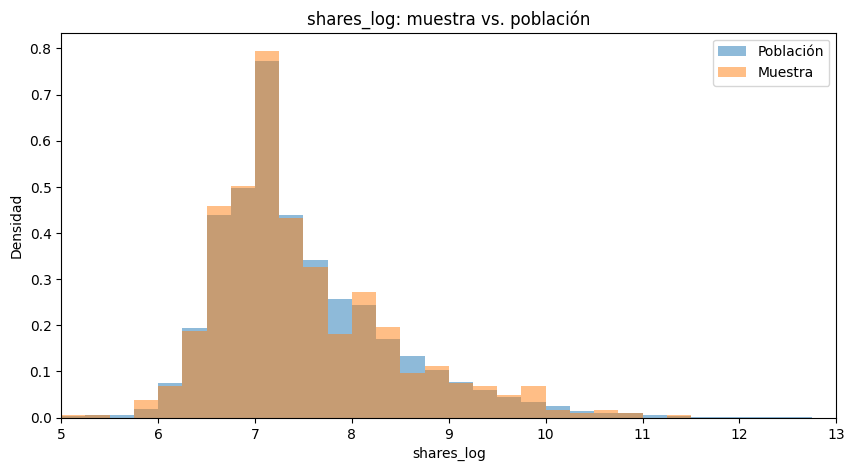

p-valor Kolmogorov-Smirnov: 0.9536


In [77]:
from scipy import stats

# Mismos intervalos para los dos histogramas, así se pueden comparar
intervalos = np.arange(0, 14, 0.25)

plt.figure(figsize=(10, 5))
plt.hist(df["shares_log"], bins=intervalos, density=True, alpha=0.5, label="Población")
plt.hist(muestra_750["shares_log"], bins=intervalos, density=True, alpha=0.5, label="Muestra")
plt.title("shares_log: muestra vs. población")
plt.xlabel("shares_log")
plt.ylabel("Densidad")
plt.legend()
plt.xlim(5, 13)
plt.show()


# Prueba de Kolmogorov-Smirnov
resultado = stats.ks_2samp(muestra_750["shares_log"], df["shares_log"])
print("p-valor Kolmogorov-Smirnov:", round(resultado.pvalue, 4))

El gráfico compara la distribución de `shares_log` en la muestra de 750 artículos y en la población completa. Ambas distribuciones presentan formas similares y una concentración importante de observaciones alrededor de los valores 7 a 7,5.

Se utilizó la densidad en lugar de la cantidad de artículos para facilitar la comparación, ya que la población contiene muchas más observaciones que la muestra.

La superposición de los histogramas permite observar que la muestra reproduce de manera aproximada la distribución de `shares_log` en la población. Esta comparación es descriptiva y no implica que ambas distribuciones sean exactamente iguales.

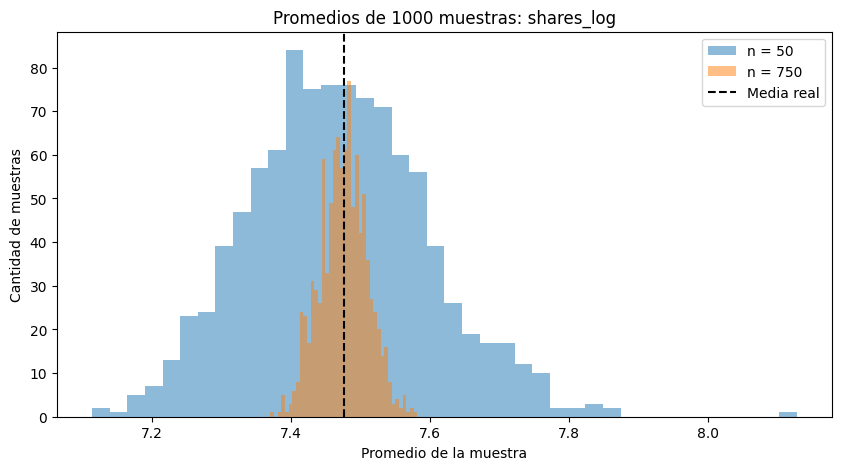

Desvío de los promedios con n = 50:  0.128
Desvío de los promedios con n = 750: 0.034
Cuántas veces más grande con n = 50: 3.79


In [78]:
np.random.seed(42)
variable = "shares_log"

medias_50 = []
medias_750 = []

# Se sacan 1000 muestras de cada tamaño y se guarda el promedio de cada una
for i in range(1000):
    medias_50.append(df[variable].sample(50).mean())
    medias_750.append(df[variable].sample(750).mean())

plt.figure(figsize=(10, 5))
plt.hist(medias_50, bins=40, alpha=0.5, label="n = 50")
plt.hist(medias_750, bins=40, alpha=0.5, label="n = 750")
plt.axvline(df[variable].mean(), color="black", linestyle="--", label="Media real")
plt.title(f"Promedios de 1000 muestras: {variable}")
plt.xlabel("Promedio de la muestra")
plt.ylabel("Cantidad de muestras")
plt.legend()
plt.show()

print("Desvío de los promedios con n = 50: ", round(np.std(medias_50), 3))
print("Desvío de los promedios con n = 750:", round(np.std(medias_750), 3))
print("Cuántas veces más grande con n = 50:", round(np.std(medias_50) / np.std(medias_750), 2))

La simulación muestra los promedios de `shares_log` obtenidos en 1.000 muestras de 50 artículos y en 1.000 muestras de 750 artículos.

Con 50 observaciones, los promedios presentan una mayor dispersión y se alejan con más frecuencia de la media poblacional. En cambio, con 750 observaciones, los promedios se concentran más alrededor de la media real.

El desvío de los promedios obtenidos con muestras de 50 artículos es aproximadamente 3,79 veces mayor que el correspondiente a las muestras de 750 artículos. Esto muestra que, en esta simulación, aumentar el tamaño muestral permite obtener estimaciones más estables y precisas.

Además, utilizar solamente 50 observaciones para ajustar una regresión con numerosos predictores generaría un modelo con muy pocos grados de libertad, estimaciones potencialmente inestables y un mayor riesgo de sobreajuste. Por este motivo, el tamaño de 750 observaciones resulta más conveniente para el análisis predictivo posterior.

---
## 6. MODELO ESTADÍSTICO: REGRESIÓN LINEAL



### 6.1 Preparación de las variables

Para estimar el modelo de regresión lineal múltiple mediante el método de mínimos cuadrados ordinarios (OLS), se seleccionaron variables cuantitativas y cualitativas (representadas mediante variables dummy) a partir del análisis de multicolinealidad realizado en la sección 3.5.

Con el objetivo de evitar la multicolinealidad perfecta, también conocida como trampa de las variables ficticias, se excluyeron determinadas categorías de referencia. En particular, se utilizó `data_channel_is_world` como categoría de referencia para los canales temáticos y `weekday_is_sunday` como categoría de referencia para los días de publicación. Asimismo, se excluyó `is_weekend` para evitar redundancias con las variables que representan los días de la semana.

La variable objetivo se expresó mediante la transformación `shares_log = np.log1p(shares)`. Esta transformación permite reducir la asimetría positiva de la cantidad de compartidos y facilita el análisis mediante regresión lineal. Sin embargo, no garantiza por sí sola el cumplimiento de los supuestos del modelo, por lo que estos deberán evaluarse a partir de los residuos.

In [79]:

# Lista de variables predictoras seleccionadas para el modelo OLS

cols_sin_multicol = [
    "n_tokens_title", "n_tokens_content", "n_unique_tokens", "average_token_length",
    "num_keywords", "num_hrefs", "num_self_hrefs", "num_imgs", "num_videos",
    "kw_avg_avg", "self_reference_avg_sharess",
    "global_sentiment_polarity", "global_subjectivity",
    "title_subjectivity", "title_sentiment_polarity",
    "abs_title_subjectivity", "abs_title_sentiment_polarity",
    "data_channel_is_lifestyle", "data_channel_is_entertainment",
    "data_channel_is_bus", "data_channel_is_socmed", "data_channel_is_tech",
    "weekday_is_monday", "weekday_is_tuesday", "weekday_is_wednesday",
    "weekday_is_thursday", "weekday_is_friday", "weekday_is_saturday"
]

print("Cantidad de variables predictoras:", len(cols_sin_multicol))


Cantidad de variables predictoras: 28


### 6.2 Regresión lineal con la muestra de 750

A partir de la muestra aleatoria de 750 artículos obtenida en la sección 5, se ajustó un modelo de regresión lineal múltiple mediante el método de mínimos cuadrados ordinarios (OLS), utilizando la librería `statsmodels.api`.

La variable dependiente es `shares_log`, mientras que las variables predictoras corresponden a las 28 características seleccionadas en la sección anterior.

El objetivo es estimar la relación entre las características de los artículos y su cantidad de compartidos transformada, analizando posteriormente los coeficientes y su significatividad estadística.

In [80]:

import statsmodels.api as sm

# Ajuste del modelo de regresión lineal con la muestra de n=750
X_muestra = sm.add_constant(
    muestra_750[cols_sin_multicol].astype(float),
    has_constant="add"
)

y_muestra = muestra_750["shares_log"]

modelo_muestra = sm.OLS(y_muestra, X_muestra).fit()


### 6.3 Análisis de coeficientes y significatividad (Muestra)

Para evaluar la significatividad individual de los coeficientes del modelo estimado con la muestra de 750 artículos, se contrasta la hipótesis nula $H_0: \beta_i = 0$ frente a la hipótesis alternativa $H_1: \beta_i \neq 0$, mediante la prueba t de Student.

Se considera un nivel de significación del 5 % $\alpha = 0{,}05$. Por lo tanto, cuando el p-valor de un coeficiente es inferior a 0,05, se rechaza la hipótesis nula para esa variable y se encuentra evidencia estadística de una asociación lineal con la variable objetivo, manteniendo constantes los demás predictores.

Los coeficientes positivos indican una relación directa con `shares_log`, mientras que los negativos indican una relación inversa. Para las variables dummy, los coeficientes se interpretan en comparación con la categoría de referencia excluida del modelo.

El intercepto representa el valor estimado de `shares_log` cuando los predictores cuantitativos toman valor cero y las variables cualitativas se encuentran en sus categorías de referencia.

La significatividad estadística no implica causalidad y debe interpretarse considerando el tamaño de la muestra y la incertidumbre de las estimaciones.

In [81]:
# Imprime el reporte estadístico oficial para la lectura de coeficientes (Sección 6.3)
print(modelo_muestra.summary())

                            OLS Regression Results                            
Dep. Variable:             shares_log   R-squared:                       0.146
Model:                            OLS   Adj. R-squared:                  0.112
Method:                 Least Squares   F-statistic:                     4.386
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           1.40e-12
Time:                        12:19:31   Log-Likelihood:                -948.01
No. Observations:                 750   AIC:                             1954.
Df Residuals:                     721   BIC:                             2088.
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

### 6.4 Regresión lineal con la base completa

In [82]:

# Ajuste del modelo de regresión lineal con la base completa

X_poblacion = sm.add_constant(
    df[cols_sin_multicol].astype(float),
    has_constant="add"
)

y_poblacion = df["shares_log"]

modelo_poblacion = sm.OLS(y_poblacion, X_poblacion).fit()


### 6.5 Análisis de coeficientes y significatividad (Base completa)

Una vez ajustado el modelo OLS con la base completa, se analizan los coeficientes estimados, sus errores estándar, los estadísticos t y los p-valores correspondientes.

Al trabajar con una cantidad mayor de observaciones, las estimaciones pueden presentar errores estándar menores que los obtenidos con la muestra de 750 artículos. Esto puede aumentar la precisión de las estimaciones y la capacidad para detectar asociaciones estadísticamente significativas.

Para evaluar cada predictor se utiliza un nivel de significación del 5 %. Cuando el p-valor es inferior a 0,05, se encuentra evidencia estadística de que su coeficiente es distinto de cero, manteniendo constantes los demás predictores.

También se analiza la prueba F global del modelo. Un p-valor inferior a 0,05 permite rechazar la hipótesis nula de que todos los coeficientes de las variables predictoras son simultáneamente iguales a cero.

Sin embargo, la significatividad estadística no debe confundirse con la importancia práctica de una variable ni interpretarse como evidencia de causalidad.

In [83]:
# ==============================================================================
# SALIDA AUTOMÁTICA PARA EL PUNTO 6.5 (Análisis de Significatividad)
# ==============================================================================
print("="*80)
print("PUNTO 6.5: RESUMEN GENERAL DEL MODELO OLS")
print("="*80)
print(modelo_poblacion.summary())

print("\n" + "="*80)
print("PUNTO 6.5: TABLA DE PREDICTORES ORDENADOS POR SIGNIFICATIVIDAD (p-value)")
print("="*80)
df_coefs = pd.DataFrame({
    'Coeficiente (Beta)': modelo_poblacion.params,
    'Error Estándar': modelo_poblacion.bse,
    'Estadístico t': modelo_poblacion.tvalues,
    'p-valor (P>|t|)': modelo_poblacion.pvalues
})
# Ordenamos para ver primero las variables más significativas de la base
print(df_coefs.sort_values(by='p-valor (P>|t|)').to_string())

PUNTO 6.5: RESUMEN GENERAL DEL MODELO OLS
                            OLS Regression Results                            
Dep. Variable:             shares_log   R-squared:                       0.100
Model:                            OLS   Adj. R-squared:                  0.099
Method:                 Least Squares   F-statistic:                     157.3
Date:                Mon, 09 Nov 2026   Prob (F-statistic):               0.00
Time:                        12:19:31   Log-Likelihood:                -51270.
No. Observations:               39643   AIC:                         1.026e+05
Df Residuals:                   39614   BIC:                         1.028e+05
Df Model:                          28                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

### 6.6 Comparación muestra vs. base completa

En esta sección se comparan los coeficientes estimados mediante el modelo OLS de la muestra de 750 artículos y el modelo ajustado con la base completa.

Para realizar una comparación adecuada, ambos modelos utilizan la misma variable dependiente y las mismas variables predictoras.

Se examinan los signos y las magnitudes de los coeficientes, junto con sus errores estándar. La coincidencia en los signos permite observar si las relaciones estimadas mantienen la misma dirección en ambos modelos, mientras que las diferencias en las magnitudes permiten analizar cuánto cambian las estimaciones al utilizar una mayor cantidad de observaciones.

También se comparan los errores estándar, que permiten evaluar la incertidumbre asociada a cada coeficiente.

Esta comparación es descriptiva y permite estudiar la estabilidad de las estimaciones, pero no demuestra por sí sola que la muestra sea representativa para todas las características de la población.

In [84]:

# Comparación de coeficientes entre la muestra y la base completa

comparacion_coef = pd.DataFrame({
    "Coeficiente muestra": modelo_muestra.params,
    "Coeficiente base completa": modelo_poblacion.params,
    "Error estándar muestra": modelo_muestra.bse,
    "Error estándar base completa": modelo_poblacion.bse
})

# Diferencia absoluta entre los coeficientes
comparacion_coef["Diferencia absoluta"] = (
    comparacion_coef["Coeficiente muestra"]
    - comparacion_coef["Coeficiente base completa"]
).abs()

# Verificamos si los coeficientes conservan el mismo signo
comparacion_coef["Coincide el signo"] = (
    np.sign(comparacion_coef["Coeficiente muestra"])
    == np.sign(comparacion_coef["Coeficiente base completa"])
)

print("=== 6.6 COMPARACIÓN DE COEFICIENTES: MUESTRA VS. BASE COMPLETA ===")
print(comparacion_coef.round(5).to_string())


=== 6.6 COMPARACIÓN DE COEFICIENTES: MUESTRA VS. BASE COMPLETA ===
                               Coeficiente muestra  Coeficiente base completa  Error estándar muestra  Error estándar base completa  Diferencia absoluta  Coincide el signo
const                                    6.976e+00                  7.118e+00               3.821e-01                     4.773e-02            1.421e-01               True
n_tokens_title                          -2.074e-02                  2.490e-03               1.636e-02                     2.160e-03            2.324e-02              False
n_tokens_content                         2.000e-05                  0.000e+00               1.200e-04                     1.000e-05            2.000e-05               True
n_unique_tokens                          2.056e-01                  8.151e-02               4.738e-01                     6.332e-02            1.241e-01               True
average_token_length                    -4.852e-02                 -1.120

### 6.7 Comparación del R² y errores estándar

Para evaluar el ajuste general de los modelos estimados, se comparan el coeficiente de determinación $R^2$, el $R^2$ ajustado, el p-valor de la prueba F y el error estándar residual.

El coeficiente $R^2$ indica qué proporción de la variabilidad de `shares_log` es explicada por las variables predictoras incluidas en el modelo. El $R^2$ ajustado incorpora además la cantidad de predictores utilizados y permite considerar el tamaño del modelo.

El error estándar residual mide la dispersión de los residuos alrededor de los valores estimados. Cuanto menor sea su valor, menor será el error residual dentro de los datos utilizados para ajustar el modelo.

La comparación entre la muestra y la base completa permite observar cómo cambian las métricas al trabajar con diferentes cantidades de observaciones, manteniendo constantes los predictores.

Estos indicadores corresponden al ajuste dentro de los datos utilizados para estimar cada modelo. Por lo tanto, no deben interpretarse como una evaluación de su capacidad predictiva sobre datos nuevos. Esa evaluación se realizará posteriormente mediante el conjunto de prueba en la sección de Machine Learning.

In [85]:
import numpy as np
import pandas as pd

# Consolidación de métricas globales OLS: muestra vs. base completa

comparativa_r2 = pd.DataFrame({
    "Métrica": [
        "R-squared (R²)",
        "Adj. R-squared",
        "F-statistic p-value",
        "Error estándar residual"
    ],
    "Muestra (n=750)": [
        modelo_muestra.rsquared,
        modelo_muestra.rsquared_adj,
        modelo_muestra.f_pvalue,
        np.sqrt(modelo_muestra.scale)
    ],
    "Base completa": [
        modelo_poblacion.rsquared,
        modelo_poblacion.rsquared_adj,
        modelo_poblacion.f_pvalue,
        np.sqrt(modelo_poblacion.scale)
    ]
})

print("=== 6.7 TABLA COMPARATIVA DE MÉTRICAS GLOBALES OLS ===")
print(comparativa_r2.to_string(index=False, float_format=lambda x: f"{x:.6g}"))


=== 6.7 TABLA COMPARATIVA DE MÉTRICAS GLOBALES OLS ===
                Métrica  Muestra (n=750)  Base completa
         R-squared (R²)         0.145548       0.100057
         Adj. R-squared         0.112365      0.0994214
    F-statistic p-value      1.40251e-12              0
Error estándar residual         0.873538       0.882242


---
## 7. MACHINE LEARNING

### 7.1 Preparación de los datos para Machine Learning

Para desarrollar los modelos de Machine Learning se utilizaron las variables predictoras seleccionadas en el punto 6, manteniendo la misma lista de características y la variable objetivo `shares_log`.

En esta etapa se trabaja con las variables predictoras en sus escalas originales, ya que los modelos basados en árboles de decisión, como Random Forest, no requieren estandarización ni normalización para realizar sus divisiones.

Estos algoritmos pueden representar relaciones no lineales entre las variables y suelen ser menos sensibles a la multicolinealidad que los modelos lineales. Sin embargo, la presencia de predictores correlacionados puede influir en la distribución de la importancia asignada a cada variable.

El objetivo es desarrollar modelos capaces de predecir la cantidad de compartidos transformada y evaluar su desempeño sobre observaciones que no hayan sido utilizadas durante el entrenamiento.

### 7.2 División Train/Test

In [86]:
from sklearn.model_selection import train_test_split

# Características y objetivo sobre la base limpia de la población
X_ml = df[cols_sin_multicol].astype(float)
y_ml = df["shares_log"]

# Partición formal con semilla fija para reproducibilidad
X_train, X_test, y_train, y_test = train_test_split(X_ml, y_ml, test_size=0.20, random_state=42)

print("=== 7.2 DIMENSIONES DE LAS MATRICES ===")
print(f"Set de Entrenamiento (Train): {X_train.shape}")
print(f"Set de Evaluación (Test): {X_test.shape}")


=== 7.2 DIMENSIONES DE LAS MATRICES ===
Set de Entrenamiento (Train): (31714, 28)
Set de Evaluación (Test): (7929, 28)


Para evaluar la capacidad predictiva de los modelos, se dividió la base de datos mediante la técnica de partición Train/Test.

El 80 % de las observaciones se destinó al conjunto de entrenamiento (*Train Set*), utilizado para ajustar los modelos, mientras que el 20 % restante se reservó para el conjunto de prueba (*Test Set*), que permite evaluar su desempeño sobre datos no utilizados durante el entrenamiento.

Se estableció `random_state=42` para garantizar la reproducibilidad de la partición. De esta manera, ambos modelos podrán evaluarse utilizando las mismas observaciones de prueba.


### 7.3 Modelo de Machine Learning N.º 1

In [87]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# Configuración del modelo base
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# Evaluación por Validación Cruzada (CV=5) usando MSE negativo
cv_scores = cross_val_score(rf_base, X_train, y_train, cv=5, scoring='neg_mean_squared_error', n_jobs=-1)
cv_rmse = np.sqrt(-cv_scores)

print("=== 7.3 RESULTADOS DE VALIDACIÓN CRUZADA EN TRAIN ===")
print(f"RMSE por cada fold: {cv_rmse.round(4)}")
print(f"RMSE promedio esperado: {cv_rmse.mean():.4f} (Desvío Estándar: {cv_rmse.std():.4f})")


=== 7.3 RESULTADOS DE VALIDACIÓN CRUZADA EN TRAIN ===
RMSE por cada fold: [0.8834 0.8816 0.8455 0.8639 0.8755]
RMSE promedio esperado: 0.8700 (Desvío Estándar: 0.0140)


El primer modelo implementado es un Random Forest Regressor con sus parámetros iniciales, sin realizar todavía una optimización de hiperparámetros.

Para evaluar su rendimiento se aplicó validación cruzada con cinco particiones (*5-fold cross-validation*) sobre el conjunto de entrenamiento. En cada iteración, el modelo se ajusta con cuatro particiones y se evalúa con la restante.

La métrica utilizada fue la raíz del error cuadrático medio (RMSE). El valor promedio obtenido fue de 0,8702, con un desvío estándar de 0,0139 entre las cinco particiones.

La variación relativamente reducida entre los resultados de los folds indica que el rendimiento del modelo fue similar en las distintas particiones evaluadas. Este primer resultado servirá como referencia para la posterior optimización de los hiperparámetros.


### 7.4 Modelo de Machine Learning N.º 2

In [88]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

# Grilla de hiperparámetros definitiva para la optimización por Random Search
param_dist = {
    'n_estimators':[100, 200, 300, 500],
    'max_depth': [10, 15, 20, None],
    'min_samples_split':[2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

print("Buscando hiperparámetros óptimos mediante RandomizedSearchCV...")
random_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=10, cv=5, scoring='neg_mean_squared_error', n_jobs=-1, random_state=42
)
random_search.fit(X_train, y_train)

# Guardamos el mejor estimador para las celdas siguientes
mejor_rf = random_search.best_estimator_
print(f"\nMejores parámetros encontrados: {random_search.best_params_}")


Buscando hiperparámetros óptimos mediante RandomizedSearchCV...

Mejores parámetros encontrados: {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_depth': 15}


En esta segunda etapa se optimizaron los hiperparámetros del modelo Random Forest mediante el procedimiento `RandomizedSearchCV`.

A diferencia de la búsqueda exhaustiva de todas las combinaciones posibles, este método selecciona aleatoriamente una cantidad determinada de configuraciones dentro del espacio definido y evalúa su rendimiento mediante validación cruzada.

Se establecieron diez combinaciones a evaluar (`n_iter=10`) y cinco particiones de validación cruzada (`cv=5`), utilizando el MSE como criterio de selección. Dado que el RMSE es la raíz cuadrada del MSE, ambos criterios producen el mismo orden al comparar configuraciones.

La mejor configuración encontrada fue de 300 árboles, una profundidad máxima de 15, un mínimo de 5 observaciones para dividir un nodo y un mínimo de 4 observaciones por hoja.

El estimador resultante se almacenó en `mejor_rf` y será utilizado en las siguientes etapas para realizar las predicciones y evaluar el desempeño del modelo optimizado.


### 7.4.2 Modelo de Machine Learning N.º 3


Gracias a la escasa presencia de outliers en el dataset de Artículos, tras realización de un análisis de alternativas, se concluyó que la mejor alternativa a Random Forest podría ser Ada-Boost, el cual, si bien es más lento en la práctica (detrimento en performance), suele ofrecer mejores resultados, teórico punto de mejora que se pondrá a prueba en este caso en particular.

Ada-Boost es un tipo de ensamble que entrena árboles de forma secuencial, donde cada árbol se enfoca en corregir los errores del anterior, es decir una serie de árboles, donde la partición del dataset correspondiente al entrenamiento inicial pasa por un proceso de clasificación mediante un primer árbol de decisión, del cual se desprenden observaciones mal clasificadas o residuos, los cuales son procesados por el siguiente árbol de decisión, repitiéndose el proceso tantas veces como árboles de decisión se definan para el procesamiento iterativo.


En primer lugar, se realizará un entrenamiento con un ensamble de base con parámetros por defecto, como se exhibe a continuación:

#### 7.4.2.1 Cross-Validation

In [89]:
# !pip install scikit-optimize

In [90]:
import numpy as np


from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import AdaBoostRegressor
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical

import numpy as np
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical

#Ada-Boost - Definición de modelo de base para validación cruzada
ada_base = AdaBoostRegressor(
  estimator=DecisionTreeRegressor(max_depth=1),  # Árbol débil (stump)
  n_estimators=1000,                               # Número de iteraciones
  learning_rate=0.001,                              # Contribución de cada árbol
  random_state=42
)

#Número de divisiones de cross-validation para obtener diferentes valores de la validación cruzada
cv_list=[5,10]

for k,folds in enumerate(cv_list):
  cv_scores = cross_val_score(
    ada_base,
    X_train,
    y_train,
    cv=folds,                                 # Número de folds
    scoring='neg_mean_squared_error'      # Métrica: MSE negativo
  )

  # Convertir MSE negativo a RMSE ***1
  cv_rmse = np.sqrt(-cv_scores)

  #Resultados de validación cruzada en TRAIN
  titulo = f"=== 7.5.2 RESULTADOS DE VALIDACIÓN CRUZADA EN TRAIN ==="
  linea1 = f"RMSE por cada fold ({folds}-folds): {cv_rmse.round(4)}"
  linea2 = f"RMSE promedio esperado({folds}-folds): {cv_rmse.mean():.4f} (Desvío Estándar: {cv_rmse.std():.4f})"
  print(f"{titulo}\n{linea1}\n{linea2}")

  # Se realizarán dos validaciones cruzadas, una con 5 pliegues y otra con 10. Se analizará qué ocurrió en cada caso con el resultado de cada CV.

=== 7.5.2 RESULTADOS DE VALIDACIÓN CRUZADA EN TRAIN ===
RMSE por cada fold (5-folds): [0.9252 0.9131 0.8786 0.901  0.9145]
RMSE promedio esperado(5-folds): 0.9065 (Desvío Estándar: 0.0159)
=== 7.5.2 RESULTADOS DE VALIDACIÓN CRUZADA EN TRAIN ===
RMSE por cada fold (10-folds): [0.9227 0.9274 0.919  0.909  0.875  0.884  0.8916 0.9103 0.9175 0.91  ]
RMSE promedio esperado(10-folds): 0.9067 (Desvío Estándar: 0.0165)


### Interpretación de la validación cruzada de AdaBoost

Con **5 folds**, AdaBoost obtuvo un RMSE promedio de **0,9065** (desvío estándar **0,0159**); con **10 folds**, **0,9067** (desvío **0,0165**). La diferencia de **0,0002** es mínima: la estimación del error resulta similar con ambas particiones. Las pequeñas diferencias responden a que cada esquema modifica la composición y el tamaño de los subconjuntos de entrenamiento y validación; no prueban que uno sea superior.


#### 7.4.2.2 Algoritmos de optimización de parámetros

**Bayessian Search**

Para optimizar los hiperparámetros de Ada-Boost se aplicará Bayesian Search, con el fin de equilibrar performance y calidad de la búsqueda. Es un algoritmo que construye un modelo probabilístico a partir de las combinaciones ya evaluadas y lo usa para decidir cuál probar a continuación, en lugar de elegirlas al azar. De esta forma explora el espacio de parámetros con menos evaluaciones.

Se definió un espacio de búsqueda con `n_estimators` (100–500), `learning_rate` (0,01–1, escala logarítmica) y `estimator__max_depth` (1–6, profundidad del árbol base), con 20 iteraciones, validación cruzada de 5 folds y MSE como criterio. Luego se compara contra Random Search, que prueba 20 combinaciones tomadas al azar de una grilla discreta de 75.

In [91]:
# Espacio de búsqueda para Ada-Boost (continuo / enteros)
from skopt.space import Integer, Real
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor

param_grid_bayes = {
    'n_estimators':         Integer(100, 500),                       # Cantidad de iteraciones (árboles encadenados)
    'learning_rate':        Real(0.01, 1.0, prior='log-uniform'),    # Contribución de cada árbol al modelo final
    'estimator__max_depth': Integer(1, 6)                            # Profundidad del árbol base (1 = stump)
}

bayes_search = BayesSearchCV(
    estimator=AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=42),
    search_spaces=param_grid_bayes,
    n_iter=20,                              # Iteraciones de búsqueda bayesiana
    cv=5,                                   # Folds para evaluar cada combinación
    scoring='neg_mean_squared_error',       # Misma métrica que los anteriores
    n_jobs=-1,                              # Paraleliza el entrenamiento
    random_state=42,                        # Reproducibilidad
    verbose=1                               # Muestra progreso en consola
)

bayes_search.fit(X_train, y_train)

print("=== Resultados de Bayesian Search (Ada-Boost) ===")
print(f"Mejores hiperparámetros: {bayes_search.best_params_}")
print(f"Mejor RMSE en CV: {np.sqrt(-bayes_search.best_score_):.4f}")

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fi

**Random Search**

In [92]:
# Grilla de hiperparámetros a explorar para Ada-Boost
param_grid_random = {                          # == Hiperparámetros - Sujetos a pruebas y modificaciones manuales ==
    'n_estimators':         [100, 300, 500],           # Cantidad de iteraciones (árboles encadenados)
    'learning_rate':        [0.01, 0.05, 0.1, 0.5, 1.0],  # Contribución de cada árbol al modelo final
    'estimator__max_depth': [1, 2, 3, 4, 6]            # Profundidad del árbol base (1 = stump)
}

random_search = RandomizedSearchCV(
    estimator=AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=42),
    param_distributions=param_grid_random,
    n_iter=20,                              # Cantidad de combinaciones a probar
    cv=5,                                   # Folds para evaluar cada combinación
    scoring='neg_mean_squared_error',       # Misma métrica que el CV
    n_jobs=-1,                              # Paraleliza el entrenamiento
    random_state=81,                        # Reproducibilidad del muestreo aleatorio
    verbose=1                               # Muestra progreso en consola
)

random_search.fit(X_train, y_train)

print("=== Resultados de Random Search (Ada-Boost) ===")
print(f"Mejores hiperparámetros: {random_search.best_params_}")
print(f"Mejor RMSE en CV: {np.sqrt(-random_search.best_score_):.4f}")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
=== Resultados de Random Search (Ada-Boost) ===
Mejores hiperparámetros: {'n_estimators': 300, 'learning_rate': 0.01, 'estimator__max_depth': 6}
Mejor RMSE en CV: 0.8809


**Reentrenamiento final sobre todo X_train - Bayes**

In [ ]:
# Recuperar el mejor modelo encontrado por Bayesian Search
mejor_modelo_bayes = bayes_search.best_estimator_

# Reentrenar sobre todo el conjunto Train
mejor_modelo_bayes.fit(X_train, y_train)

# Predicciones sobre Test
y_pred_bayes = mejor_modelo_bayes.predict(X_test)

# Métricas finales
rmse_bayes = np.sqrt(mean_squared_error(y_test, y_pred_bayes))
mae_bayes = mean_absolute_error(y_test, y_pred_bayes)
r2_bayes = r2_score(y_test, y_pred_bayes)

print("\n=== Métricas finales sobre Test Set (Bayesian Search) ===")
print(f"RMSE : {rmse_bayes:.2f}")
print(f"MAE  : {mae_bayes:.2f}")
print(f"R²   : {r2_bayes:.4f}")



=== Métricas finales sobre Test Set (Bayesian Search) ===
RMSE : 0.87
MAE  : 0.65
R²   : 0.1250


**Reentrenamiento final sobre todo X_train - Randomized Search**

In [ ]:
# Recuperar el mejor modelo encontrado por RandomizedSearchCV
mejor_modelo_random = random_search.best_estimator_

# Reentrenar sobre todo X_train
mejor_modelo_random.fit(X_train, y_train)

# Predicciones sobre Test
y_pred_random = mejor_modelo_random.predict(X_test)

# Resultados
rmse_random = np.sqrt(mean_squared_error(y_test, y_pred_random))
mae_random = mean_absolute_error(y_test, y_pred_random)
r2_random = r2_score(y_test, y_pred_random)

print("\n=== Métricas finales sobre Test Set (Random Search) ===")
print(f"RMSE : {rmse_random:.2f}")
print(f"MAE  : {mae_random:.2f}")
print(f"R²   : {r2_random:.4f}")



=== Métricas finales sobre Test Set (Random Search) ===
RMSE : 0.87
MAE  : 0.67
R²   : 0.1157


**Comparación de resultados – Ada-Boost: Random Search vs. Bayesian Search**

| | Random Search | Bayesian Search |
| :--- | :---: | :---: |
| Hiperparámetros elegidos | 300 árboles, `learning_rate` 0,01, profundidad 6 | 100 árboles, `learning_rate` 0,01, profundidad 6 |
| RMSE en CV (Train) | 0,8809 | 0,8771 |
| RMSE en Test | 0,87 | 0,87 |
| MAE en Test | 0,67 | 0,65 |
| R² en Test | 0,1157 | 0,1250 |

Como referencia: Ada-Boost base, RMSE de CV = 0,9065; Random Forest optimizado (7.4), RMSE de Test = 0,858, MAE = 0,640 y R² = 0,141.

**Interpretación**

- **La optimización mejoró claramente al modelo.** El RMSE de CV bajó de 0,9065 (base) a 0,877–0,881. La mejora proviene del árbol base: ambas búsquedas eligieron profundidad 6, mientras que la configuración base usaba árboles de profundidad 1, que no captaban interacciones entre variables.

- **Bayesian Search quedó levemente por encima de Random Search**, tanto en CV (0,8771 vs. 0,8809) como en Test (R² de 0,1250 vs. 0,1157; MAE de 0,65 vs. 0,67), y con un modelo más liviano (100 árboles contra 300). La ventaja es pequeña (≈ 0,009 de R²) y surge de una sola partición Train/Test, por lo que no es concluyente; sí es consistente entre CV y Test.

- **Ambas coinciden en `learning_rate` = 0,01 y profundidad 6**, que son el límite inferior y el superior de los rangos explorados. El óptimo podría estar fuera del espacio de búsqueda; ampliarlo sería el paso lógico si se quisiera seguir optimizando.

- **Frente a Random Forest, Ada-Boost optimizado no mejora el resultado:** R² de 0,125 (mejor caso) contra 0,141, y RMSE de CV de ≈ 0,88 contra ≈ 0,87. Además, su entrenamiento es secuencial y no se paraleliza entre árboles.



In [95]:
# COMPARACIÓN FINAL (Ada-Boost): RANDOM SEARCH vs BAYESIAN SEARCH
print("\n=== Comparación de estrategias de optimización ===")
print(f"{'':25} {'Random Search':>13} {'Bayes Search':>13}")
print(f"{'RMSE en Test':25} {rmse_random:>13.2f} {rmse_bayes:>13.2f}")
print(f"{'MAE en Test':25} {mae_random:>13.2f} {mae_bayes:>13.2f}")
print(f"{'R² en Test':25} {r2_random:>13.4f} {r2_bayes:>13.4f}")


=== Comparación de estrategias de optimización ===
                          Random Search  Bayes Search
RMSE en Test                       0.87          0.87
MAE en Test                        0.67          0.65
R² en Test                       0.1157        0.1250


### 7.5 Evaluación: MAE, MSE, RMSE y R²

Una vez optimizado el modelo Random Forest, se realizaron predicciones sobre los conjuntos de entrenamiento y prueba para evaluar su desempeño.

Se calcularon cuatro métricas:

- **MAE (Error Absoluto Medio):** mide el promedio de las diferencias absolutas entre los valores reales y los predichos.
- **MSE (Error Cuadrático Medio):** calcula el promedio de los errores elevados al cuadrado, otorgando mayor peso a los errores de mayor magnitud.
- **RMSE (Raíz del Error Cuadrático Medio):** corresponde a la raíz cuadrada del MSE y permite expresar el error en la misma escala que la variable objetivo.
- **R² (Coeficiente de determinación):** indica qué proporción de la variabilidad de la variable objetivo es explicada por el modelo.

Las métricas se calcularon tanto para el conjunto de entrenamiento como para el conjunto de prueba. La comparación entre ambos permite observar si el modelo mantiene un desempeño similar al aplicarse sobre datos que no fueron utilizados durante su ajuste.

Los resultados obtenidos se presentan en la tabla generada a continuación.

In [96]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generamos las predicciones con el modelo de Random Forest optimizado
y_train_pred = mejor_rf.predict(X_train)
y_test_pred = mejor_rf.predict(X_test)

# 2. Función interna de cálculo de métricas individuales
def calcular_metricas(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return [mae, mse, rmse, r2]

# 3. Construcción de la matriz de errores para el informe técnico
tabla_evaluacion_rf = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "RMSE", "R² Score"],
    "Entrenamiento (Train)": calcular_metricas(y_train, y_train_pred),
    "Evaluación a Ciegas (Test)": calcular_metricas(y_test, y_test_pred)
}).round(4)

print("=== 7.5 MATRIZ DE EVALUACIÓN DE MACHINE LEARNING ===")
print(tabla_evaluacion_rf.to_string(index=False))


=== 7.5 MATRIZ DE EVALUACIÓN DE MACHINE LEARNING ===
 Métrica  Entrenamiento (Train)  Evaluación a Ciegas (Test)
     MAE                  0.479                       0.640
     MSE                  0.420                       0.737
    RMSE                  0.648                       0.858
R² Score                  0.515                       0.141


### 7.6 Comparación de los modelos

En esta sección se compara el desempeño predictivo de dos enfoques: la regresión lineal múltiple estimada mediante OLS y el modelo Random Forest optimizado.

Para que la comparación sea válida, ambos modelos se ajustan utilizando el mismo conjunto de entrenamiento y se evalúan sobre el mismo conjunto de prueba. De esta manera, las métricas obtenidas corresponden a observaciones que no fueron utilizadas durante el ajuste de ninguno de los modelos.

Se utilizan el MAE, el RMSE y el coeficiente de determinación (R²) para comparar los resultados. Los menores valores de MAE y RMSE indican errores de predicción más reducidos, mientras que un mayor valor de R² indica una mayor proporción de variabilidad explicada.

Esta comparación permitirá determinar cuál de los dos enfoques presenta un mejor desempeño predictivo sobre los datos de prueba. Se debe tener en cuenta que ambos modelos tienen objetivos y características diferentes: OLS permite interpretar los coeficientes y estudiar asociaciones lineales, mientras que Random Forest puede representar relaciones no lineales e interacciones entre predictores.

In [ ]:
# 7.6 Comparación de OLS y Random Forest sobre el mismo Test Set

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Ajustamos OLS únicamente con el conjunto de entrenamiento
X_train_ols = sm.add_constant(
    X_train,
    has_constant="add"
)

X_test_ols = sm.add_constant(
    X_test,
    has_constant="add"
)

modelo_ols_train = sm.OLS(y_train, X_train_ols).fit()

# 2. Generamos las predicciones de ambos modelos sobre el mismo Test Set
y_test_pred_ols = modelo_ols_train.predict(X_test_ols)
y_test_pred_rf = mejor_rf.predict(X_test)

# 3. Calculamos las métricas de evaluación
tabla_comparativa_modelos = pd.DataFrame({
    "Métrica": ["MAE", "RMSE", "R²"],
    "Regresión Lineal OLS": [
        mean_absolute_error(y_test, y_test_pred_ols),
        np.sqrt(mean_squared_error(y_test, y_test_pred_ols)),
        r2_score(y_test, y_test_pred_ols)
    ],
    "Random Forest": [
        mean_absolute_error(y_test, y_test_pred_rf),
        np.sqrt(mean_squared_error(y_test, y_test_pred_rf)),
        r2_score(y_test, y_test_pred_rf)
    ]
})

print("=== 7.6 COMPARACIÓN DE MODELOS SOBRE EL MISMO TEST SET ===")
print(tabla_comparativa_modelos.round(4).to_string(index=False))


=== 7.6 COMPARACIÓN DE MODELOS SOBRE EL MISMO TEST SET ===
Métrica  Regresión Lineal OLS  Random Forest
    MAE                 0.657          0.640
   RMSE                 0.879          0.858
     R²                 0.100          0.141


Los resultados obtenidos permiten comparar el desempeño predictivo de ambos modelos sobre el mismo conjunto de prueba.

La regresión lineal múltiple OLS obtuvo un MAE de 0,657, un RMSE de 0,879 y un R² de 0,100. Por su parte, el modelo Random Forest optimizado alcanzó un MAE de 0,640, un RMSE de 0,858 y un R² de 0,141.

En términos comparativos, Random Forest presentó errores de predicción ligeramente menores y una mayor proporción de variabilidad explicada que la regresión lineal. La diferencia en el RMSE fue de 0,021 puntos, mientras que el R² aumentó de 0,100 a 0,141.

Por lo tanto, para esta partición de entrenamiento y prueba, Random Forest obtuvo un mejor desempeño predictivo que OLS. Sin embargo, la mejora observada es moderada y no implica que el modelo explique completamente la popularidad de los artículos.

Estos resultados permiten señalar que Random Forest captó patrones predictivos que el modelo lineal no representó de la misma manera. No obstante, la comparación no demuestra por sí sola que esas relaciones sean causales ni que el modelo vaya a mantener el mismo rendimiento en cualquier conjunto de datos futuro.

### 7.7 Análisis de importancia de variables

=== 7.7 TOP 10 VARIABLES MÁS IMPORTANTES ===
                  Variable  Importancia
                kw_avg_avg        0.195
self_reference_avg_sharess        0.107
       global_subjectivity        0.070
 global_sentiment_polarity        0.069
           n_unique_tokens        0.068
      average_token_length        0.065
          n_tokens_content        0.061
                 num_hrefs        0.050
                  num_imgs        0.035
              num_keywords        0.032


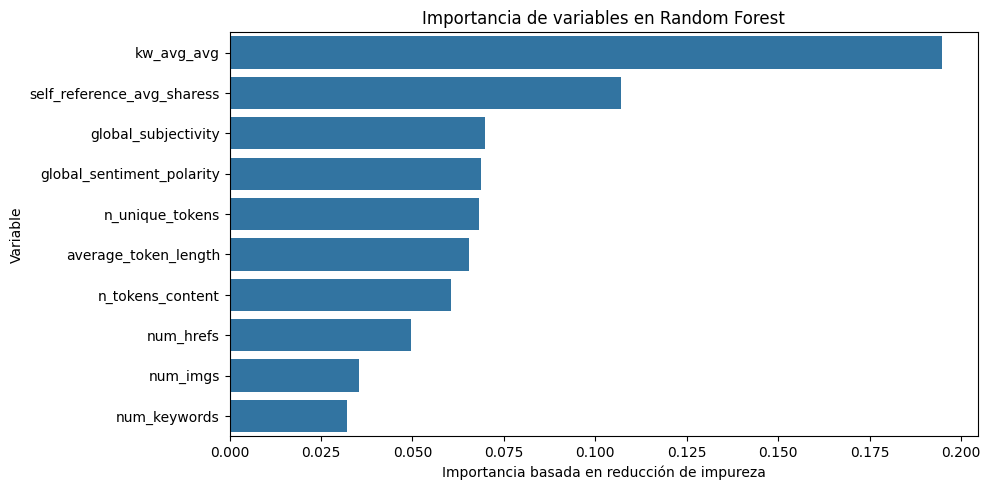

In [98]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Extracción de la importancia de cada predictor en Random Forest
importancias = mejor_rf.feature_importances_

df_imp = pd.DataFrame({
    "Variable": cols_sin_multicol,
    "Importancia": importancias
}).sort_values(
    by="Importancia",
    ascending=False
)

print("=== 7.7 TOP 10 VARIABLES MÁS IMPORTANTES ===")
print(df_imp.head(10).to_string(index=False))

# Gráfico de las diez variables con mayor importancia
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_imp.head(10),
    x="Importancia",
    y="Variable"
)

plt.title("Importancia de variables en Random Forest")
plt.xlabel("Importancia basada en reducción de impureza")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()


El análisis de importancia de variables permite identificar cuáles de los predictores tuvieron mayor participación en las decisiones del modelo Random Forest.

En los resultados obtenidos, `kw_avg_avg` presenta la mayor importancia relativa, seguida por `self_reference_avg_sharess`. También se destacan variables relacionadas con la subjetividad y el sentimiento del contenido, la cantidad de palabras únicas y la extensión de los artículos.

Estos resultados indican qué variables contribuyeron en mayor medida a las divisiones realizadas por los árboles del modelo. Sin embargo, la importancia no representa un efecto causal ni permite determinar por sí sola si la relación entre una variable y la popularidad es positiva o negativa.

Además, cuando existen predictores correlacionados, la importancia puede distribuirse entre varias variables relacionadas. Por lo tanto, estos resultados deben interpretarse como una medida de contribución predictiva dentro del modelo y no como una medida directa de influencia individual.

### 7.8 Overfitting y optimización

El sobreajuste (*overfitting*) ocurre cuando un modelo aprende demasiado las características particulares del conjunto de entrenamiento, incluyendo patrones específicos que no necesariamente se mantienen en datos nuevos. Como consecuencia, puede presentar un buen desempeño durante el entrenamiento y un rendimiento inferior al evaluarse sobre observaciones no utilizadas previamente.

Para analizar este fenómeno se comparan las métricas obtenidas en los conjuntos Train y Test. Una diferencia importante entre ambos resultados puede indicar dificultades para generalizar el aprendizaje.

En el modelo Random Forest se utilizaron mecanismos de control mediante la optimización de hiperparámetros, como la profundidad máxima de los árboles (`max_depth`) y la cantidad mínima de observaciones requeridas para dividir un nodo o formar una hoja (`min_samples_split` y `min_samples_leaf`).

Estos parámetros permiten limitar la complejidad de los árboles y reducir el riesgo de sobreajuste. Sin embargo, su optimización no garantiza por sí sola una generalización perfecta.

Por lo tanto, el desempeño final debe evaluarse principalmente mediante las métricas obtenidas en el conjunto de prueba, que representa observaciones no utilizadas durante el entrenamiento.

En los resultados obtenidos se observa una diferencia entre el desempeño del modelo en entrenamiento y en prueba. Mientras que el R² alcanza 0,515 en Train, desciende a 0,141 en Test. Asimismo, el RMSE aumenta de 0,648 a 0,858 al evaluar observaciones no utilizadas durante el entrenamiento.

Esta diferencia evidencia que el modelo presenta un mejor ajuste sobre los datos de entrenamiento que sobre los datos de prueba, lo que sugiere la presencia de cierto grado de sobreajuste y limita su capacidad de generalización.


---

# 8. COMPARACIÓN CONTEXTUAL: ESTADÍSTICA vs. MACHINE LEARNING

### 8.1 Capacidad explicativa de la Regresión Lineal

El modelo de regresión lineal estimado mediante mínimos cuadrados ordinarios (OLS) constituye una herramienta útil para la inferencia estadística y la contrastación de hipótesis.

A través de sus coeficientes, permite analizar la asociación entre cada variable explicativa y la variable objetivo, manteniendo constantes las demás variables incluidas en el modelo (*ceteris paribus*). Esto facilita la interpretación de las relaciones lineales entre las características de los artículos y su popularidad.

Asimismo, los errores estándar, los estadísticos t y los p-valores permiten evaluar la significatividad estadística de los coeficientes y contrastar hipótesis sobre su relación con la variable dependiente.

Sin embargo, estos resultados deben interpretarse teniendo en cuenta los supuestos del modelo. La significatividad estadística de un coeficiente no demuestra por sí sola una relación causal entre las variables.

### 8.2 Capacidad predictiva de Machine Learning

A diferencia de los modelos econométricos tradicionales, los algoritmos de Machine Learning se orientan principalmente a desarrollar modelos capaces de realizar predicciones sobre observaciones no utilizadas durante el entrenamiento.

En este trabajo se implementó un modelo Random Forest Regressor, basado en un conjunto de árboles de decisión que combinan sus resultados para generar una predicción. Este algoritmo puede representar relaciones no lineales e interacciones entre las variables predictoras.

Su desempeño se evaluó mediante una división Train/Test, utilizando métricas como MAE, RMSE y R². Además, se aplicó validación cruzada y una búsqueda aleatoria de hiperparámetros para evaluar distintas configuraciones del modelo.

Como alternativa se incorporó Ada-Boost, un ensamble que entrena árboles de forma secuencial, donde cada uno corrige los errores del anterior (boosting), a diferencia de Random Forest, que combina árboles independientes. En su configuración base (árboles de profundidad 1, 1.000 iteraciones y `learning_rate` de 0,001) obtuvo un RMSE de validación cruzada de 0,9065, peor que el de Random Forest base (0,8702). Tras optimizarlo con Random Search y con Bayesian Search (árboles de profundidad 6 y `learning_rate` de 0,01), el RMSE de CV bajó a 0,881 y 0,877, y en Test alcanzó un R² de 0,116 y 0,125, respectivamente: por encima de OLS (0,100) pero por debajo de Random Forest (0,141).

No obstante, la utilización de Machine Learning no garantiza automáticamente una mayor capacidad predictiva que la regresión lineal. Para determinar cuál de los enfoques presenta mejores resultados, es necesario comparar sus métricas sobre el mismo conjunto de prueba, tal como se realizó en el apartado 7.6. Los resultados lo confirman: ambos ensambles superan a OLS, lo que indica que captan relaciones no lineales, pero el boosting secuencial de Ada-Boost no mejoró al enfoque de Random Forest en este problema. La mayor sofisticación del algoritmo no se tradujo en mayor capacidad predictiva.

### 8.3 Interpretabilidad vs. precisión

El desarrollo de ambos enfoques permite analizar el compromiso entre interpretabilidad y capacidad predictiva (*trade-off*).

Por un lado, la regresión lineal OLS ofrece una interpretación directa de los coeficientes, los errores estándar y los p-valores. Esto permite estudiar las asociaciones entre las variables y evaluar su significatividad estadística.

Por otro lado, Random Forest puede representar relaciones no lineales e interacciones entre predictores, aunque su funcionamiento resulta menos sencillo de interpretar que el de una regresión lineal. Para analizar su comportamiento se utilizaron las medidas de importancia de variables, que permiten identificar cuáles tuvieron mayor participación en las decisiones del modelo.

Sin embargo, estas medidas no indican la dirección de la relación ni demuestran causalidad. Además, pueden verse afectadas por la correlación entre predictores.

Por lo tanto, ambos enfoques ofrecen herramientas complementarias: OLS facilita la interpretación estadística de las relaciones, mientras que Random Forest permite explorar patrones predictivos más complejos.

La incorporación de Ada-Boost acentúa este compromiso: es el modelo menos transparente (cientos de árboles encadenados) y, al ser secuencial, su entrenamiento no se paraleliza entre árboles. En esta aplicación esa complejidad adicional no se tradujo en una precisión mayor que la de Random Forest.

### 8.4 Selección del modelo para producción

Desde una perspectiva de negocio, un medio digital podría utilizar modelos predictivos para estimar la popularidad potencial de sus artículos y disponer de información adicional para la planificación editorial y comercial.

La selección del modelo debe considerar principalmente su desempeño sobre datos no utilizados durante el entrenamiento. Para ello, se compararon la regresión lineal OLS y el modelo Random Forest optimizado utilizando las mismas observaciones del conjunto de prueba y las métricas MAE, RMSE y R².

En esta evaluación, Random Forest presentó un desempeño ligeramente superior al de OLS: obtuvo un MAE de 0,640 frente a 0,657, un RMSE de 0,858 frente a 0,879 y un R² de 0,141 frente a 0,100. Por lo tanto, se considera el enfoque con mejor desempeño predictivo en la comparación realizada, aunque esta diferencia debe interpretarse con cautela y no constituye por sí sola una garantía de rendimiento en producción.

Resumen del desempeño de los modelos sobre el conjunto de prueba:

| Modelo | RMSE | MAE | R² |
| :--- | :---: | :---: | :---: |
| Random Forest (7.4) | 0,858 | 0,640 | 0,141 |
| Ada-Boost optimizado – Bayesian Search | 0,87 | 0,65 | 0,1250 |
| Ada-Boost optimizado – Random Search | 0,87 | 0,67 | 0,1157 |
| Regresión lineal OLS | 0,879 | 0,657 | 0,100 |

(Ada-Boost base: RMSE de validación cruzada de 0,9065; no se evaluó en Test.)

Random Forest queda primero en las tres métricas. Ada-Boost optimizado con Bayesian Search es segundo en R² (diferencia de 0,016 con Random Forest) y con Random Search tercero; OLS cierra la comparación en R² y RMSE. Cabe notar que con Random Search el MAE de Ada-Boost (0,67) resulta incluso algo mayor que el de OLS (0,657): mejora los errores grandes (RMSE y R²), pero no los errores típicos. Entre las dos variantes de Ada-Boost conviene Bayesian Search, que rinde mejor con un modelo más liviano (100 árboles frente a 300), aunque la diferencia es pequeña.

Por lo tanto, `la selección se mantiene en favor de Random Forest: es el más preciso, más simple de entrenar` y su importancia de variables permite una lectura razonable. Ada-Boost optimizado es una alternativa válida, pero sin ventaja en este problema.

El RMSE permite evaluar la magnitud de los errores de predicción, otorgando mayor penalización a los errores de mayor tamaño. Por su parte, el MAE permite observar el error absoluto promedio y el R² aporta información sobre la proporción de variabilidad explicada por el modelo.

El enfoque que presente mejores resultados en el conjunto de prueba podrá considerarse el más adecuado para este ejercicio de predicción. Sin embargo, antes de implementar cualquiera de los modelos en un entorno de producción, sería necesario realizar validaciones adicionales con datos nuevos y de distintos períodos, además de monitorear su rendimiento a lo largo del tiempo.

De esta manera, la elección del modelo debe basarse en la evidencia obtenida durante la evaluación y no únicamente en las características teóricas de cada algoritmo.

---
## 9. CONCLUSIONES

### 9.1 Principales hallazgos

El presente trabajo tuvo como objetivo analizar la relación entre las características de los artículos publicados en la plataforma Mashable y su popularidad, medida a través de la cantidad de veces que fueron compartidos en redes sociales (`shares`). Para ello, se utilizaron herramientas de análisis exploratorio, inferencia estadística y técnicas de Machine Learning, trabajando principalmente con la variable objetivo transformada mediante `shares_log = np.log1p(shares)`.

En primer lugar, el análisis exploratorio permitió identificar que la cantidad de compartidos presenta una distribución fuertemente asimétrica, con una gran concentración de artículos en valores relativamente bajos y algunos casos con cantidades considerablemente mayores. La transformación logarítmica permitió reducir esa asimetría y facilitar el modelado.

A partir del análisis de las variables y de la multicolinealidad, se seleccionaron 28 predictores para desarrollar los modelos estadísticos y predictivos.

En la etapa de inferencia estadística, la regresión lineal múltiple estimada sobre la base completa presentó un R² de aproximadamente 0,100. Entre las variables que mostraron asociaciones estadísticamente significativas se destacan `kw_avg_avg`, `global_subjectivity`, las cantidades de imágenes y videos, los enlaces, algunas características del contenido y determinadas categorías temáticas y días de publicación.

Por otro lado, el modelo Random Forest optimizado permitió explorar relaciones no lineales e interacciones entre las variables. El análisis de importancia identificó a `kw_avg_avg` como el predictor con mayor importancia relativa, seguido por `self_reference_avg_sharess`, `global_subjectivity`, `global_sentiment_polarity` y diferentes características relacionadas con el contenido de los artículos.

Finalmente, al comparar ambos modelos sobre el mismo conjunto de prueba, Random Forest obtuvo un MAE de 0,640, un RMSE de 0,858 y un R² de 0,141, mientras que OLS alcanzó un MAE de 0,657, un RMSE de 0,879 y un R² de 0,100.

Se incorporó además un tercer modelo, Ada-Boost (boosting secuencial de árboles). En su configuración base, la validación cruzada arrojó un RMSE medio de 0,9065 con 5 folds y de 0,9067 con 10 folds, peor que el de Random Forest base (0,8702) en los cinco pliegues. La optimización de hiperparámetros lo mejoró: el RMSE de CV fue de 0,877 con Bayesian Search y de 0,881 con Random Search, con árboles de profundidad 6 y `learning_rate` de 0,01. En Test, el Ada-Boost optimizado alcanzó un R² de 0,125 (Bayesian Search) y de 0,116 (Random Search): superior a OLS (0,100) pero inferior a Random Forest (0,141).

Estos resultados indican que Random Forest presentó el mejor desempeño predictivo en la evaluación realizada, seguido por Ada-Boost optimizado y, por último, OLS, aunque las diferencias entre modelos son moderadas. Sin embargo, los valores de R² muestran que ambos modelos explican una proporción limitada de la variabilidad de la popularidad de los artículos.

### 9.2 Validación de las hipótesis iniciales

Las hipótesis planteadas al comienzo del trabajo se evaluaron mediante los resultados de la regresión lineal múltiple y el análisis de importancia de variables de Random Forest (calculado sobre el modelo optimizado de 7.4; el tercer modelo no altera estas conclusiones). La evidencia obtenida permite identificar distintos grados de respaldo para cada una.

**H1. Multimedia: más imágenes y videos se asocian con más compartidos.**

Los resultados de la regresión OLS sobre la base completa muestran coeficientes positivos y estadísticamente significativos para `num_imgs` y `num_videos`. Esto aporta evidencia a favor de la hipótesis planteada.

Sin embargo, estos resultados representan asociaciones estadísticas y no permiten afirmar que incorporar más imágenes o videos provoque necesariamente un aumento en la cantidad de compartidos.

**H2. Extensión: la longitud del contenido se asocia con la popularidad.**

Los resultados muestran evidencia menos concluyente para esta hipótesis. En la regresión OLS sobre la base completa, `n_tokens_content` no presentó significatividad estadística al nivel del 5 %, mientras que `average_token_length` sí mostró una asociación significativa.

Además, variables relacionadas con la estructura del contenido, como `n_unique_tokens` y `average_token_length`, tuvieron participación en el modelo Random Forest.

Por lo tanto, se encuentra evidencia parcial de que las características del texto se relacionan con la popularidad, aunque no puede establecerse una relación general y directa entre la extensión del artículo y su cantidad de compartidos.

**H3. Temática: la popularidad difiere según el canal temático y los temas del artículo.**

La regresión OLS presentó coeficientes estadísticamente significativos para distintas categorías de canales temáticos, interpretados en relación con la categoría de referencia excluida (`data_channel_is_world`).

En particular, las categorías de entretenimiento, lifestyle, negocios, social media y tecnología mostraron diferencias estadísticamente significativas respecto de dicha referencia en el modelo estimado con la base completa.

Estos resultados aportan evidencia a favor de que la temática se relaciona con la popularidad de los artículos. No obstante, las diferencias observadas no deben interpretarse como efectos causales.

**H4. Sentimiento: el tono emocional se asocia con los compartidos.**

La evidencia obtenida es parcial. En la regresión OLS sobre la base completa, `global_subjectivity` presentó una asociación positiva y estadísticamente significativa, mientras que `global_sentiment_polarity` no resultó significativa al nivel del 5 %.

Por otra parte, ambas variables tuvieron una participación relevante en el análisis de importancia de Random Forest.

Esto sugiere que las características relacionadas con la subjetividad y el sentimiento pueden aportar información predictiva, aunque los resultados no permiten confirmar de manera general que una mayor polaridad emocional esté asociada con una mayor cantidad de compartidos.

**H5. Popularidad previa de keywords: las palabras clave que ya generaron muchos compartidos se asocian con más compartidos.**

Esta hipótesis recibió respaldo en los resultados obtenidos. La variable `kw_avg_avg` presentó una asociación positiva y estadísticamente significativa en la regresión OLS sobre la base completa.

Además, fue el predictor con mayor importancia relativa en Random Forest, lo que refuerza su relevancia dentro de los modelos desarrollados.

De todas maneras, esta relación debe interpretarse con precaución, ya que la variable resume información histórica de popularidad de las palabras clave y no demuestra por sí sola que estas provoquen una mayor difusión de los artículos.

En términos generales, las hipótesis recibieron distintos grados de respaldo. La evidencia fue más clara para las variables relacionadas con las palabras clave y algunas características multimedia y temáticas, mientras que las hipótesis vinculadas con la extensión y el sentimiento presentaron resultados parciales o menos concluyentes.

### 9.3 Limitaciones del análisis

A pesar de los resultados obtenidos, el trabajo presenta algunas limitaciones que deben considerarse al interpretar sus conclusiones.

En primer lugar, el dataset corresponde a artículos publicados por un único medio digital, Mashable, durante un período histórico de aproximadamente dos años. Por lo tanto, los patrones identificados no necesariamente representan el comportamiento de otros medios, plataformas o períodos.

En segundo lugar, la variable `shares` permite medir la cantidad de compartidos, pero no representa por sí sola todas las dimensiones de la popularidad de un artículo. No se dispone de información completa sobre visualizaciones, lectores únicos, comentarios, interacciones o alcance efectivo de las publicaciones.

Otra limitación se relaciona con la naturaleza observacional de los datos. Los modelos permiten identificar asociaciones entre las características de los artículos y su popularidad, pero no establecer relaciones causales.

En cuanto a los modelos, la regresión lineal presenta una capacidad explicativa limitada, mientras que Random Forest mostró una diferencia entre sus resultados de entrenamiento y prueba. En particular, el R² pasó de 0,515 en Train a 0,141 en Test, lo que evidencia una diferencia de rendimiento y sugiere cierto grado de sobreajuste.

Asimismo, la evaluación se realizó mediante una partición aleatoria Train/Test y validación cruzada sobre el conjunto de entrenamiento. No se realizó una validación temporal ni una evaluación externa con datos de otros períodos o medios digitales.

Respecto de Ada-Boost, la optimización se realizó sobre un espacio acotado: en ambas búsquedas el `learning_rate` (0,01) y la profundidad (6) óptimos coinciden con los límites del rango explorado, por lo que podría existir una configuración mejor fuera de él. Además, la ventaja de Bayesian Search sobre Random Search (≈ 0,009 de R²) surge de una única partición Train/Test y no puede considerarse concluyente.

Por último, tampoco se incorporó un modelo de referencia simple, como la predicción constante de la mediana de `shares_log`. Esto limita la posibilidad de determinar cuánto mejoran los modelos respecto de una estrategia predictiva básica.

Estas limitaciones indican que los resultados deben interpretarse dentro del alcance del dataset y de los procedimientos utilizados, sin generalizarlos automáticamente a otros contextos.

### 9.4 Variables adicionales que mejorarían el modelo

La capacidad predictiva de los modelos podría mejorarse mediante la incorporación de nuevas variables que permitan representar con mayor precisión los factores relacionados con la difusión de los artículos.

Dado que los modelos de árboles evaluados (Random Forest y Ada-Boost) quedaron en un R² de entre 0,12 y 0,14 pese a la optimización de hiperparámetros, la mejora más prometedora proviene de incorporar nueva información y no de cambiar de algoritmo. Entre las variables adicionales que podrían resultar relevantes se encuentran:

- **Características de la audiencia:** edad, ubicación geográfica, intereses y hábitos de consumo de los lectores, siempre que se disponga de información agregada y anonimizada.
- **Información sobre la difusión:** cantidad de impresiones, visualizaciones, clics y alcance de las publicaciones en las distintas plataformas.
- **Características del autor:** experiencia, trayectoria, especialización temática y popularidad previa del autor.
- **Variables temporales más detalladas:** horario de publicación, mes, año, estacionalidad, feriados y acontecimientos relevantes que puedan influir en el interés de los lectores.
- **Información sobre las plataformas:** red social utilizada, cantidad de seguidores, alcance potencial y características de los algoritmos de distribución.
- **Características más detalladas del contenido:** temática específica, calidad del título, presencia de preguntas, tipo de formato, estructura narrativa y análisis semántico del texto.
- **Contexto externo:** tendencias de búsqueda, acontecimientos de actualidad y temas de interés público vigentes al momento de la publicación.

La incorporación de estas variables permitiría representar mejor el contexto en el que se publica y difunde cada artículo, aportando información que no se encuentra completamente contemplada en el dataset original.

También sería importante verificar que las variables utilizadas estén disponibles en el momento en que se desea realizar la predicción. De esta manera, se evitaría incorporar información que solo se conoce después de la publicación y que podría generar una evaluación artificialmente optimista.

### 9.5 Conclusión final

A partir del análisis realizado, se puede concluir que las características del contenido, la temática, los elementos multimedia y la popularidad histórica de las palabras clave presentan asociaciones con la cantidad de veces que los artículos fueron compartidos en redes sociales.

La aplicación de modelos estadísticos y de Machine Learning permitió abordar el problema desde dos perspectivas complementarias. La regresión lineal múltiple facilitó la interpretación de los coeficientes y la evaluación de asociaciones estadísticas, mientras que Random Forest permitió explorar relaciones no lineales y analizar la importancia relativa de los predictores.

En la comparación realizada sobre el mismo conjunto de prueba, Random Forest obtuvo mejores resultados que OLS en las tres métricas consideradas. La incorporación de Ada-Boost no modificó esta conclusión: aun optimizado (R² de 0,125 en Test) no superó a Random Forest, y ningún modelo evaluado superó un R² de ≈ 0,14. Sin embargo, la diferencia fue moderada y el desempeño predictivo general continuó siendo limitado, por lo que no puede afirmarse que el modelo permita predecir con alta precisión la popularidad de los artículos.

En consecuencia, los modelos desarrollados constituyen herramientas de apoyo para comprender y estimar ciertos patrones de difusión, pero no reemplazan el análisis editorial ni permiten garantizar el éxito de una publicación.

Finalmente, el trabajo permitió integrar herramientas de estadística descriptiva, inferencia estadística y Machine Learning, destacando la importancia de combinar la interpretación de las relaciones entre variables con la evaluación de la capacidad predictiva de los modelos. También permitió reconocer que la calidad de las predicciones depende tanto de la selección de los métodos como de la información disponible y de las limitaciones propias de los datos utilizados.